![](/../assets/header-logo.png)

## Motion Forecasting for Autonomous Driving

**Automated and Connected Driving Challenges - Research Project - 09/2026**

**Research Topic 16b: Motion Forecasting**

| Author | Mail |
| --- | --- |
| Tanay Ranjan | tanay.ranjan@rwth-aachen.de |
| Ishita Jain | ishita.jain@rwth-aachen.de |
| Manish Rajasekar | manish.rajasekar@rwth-aachen.de |

#### Dependencies & Setup

##### Execution Environment

This report falls into the category *Python, excl. TensorFlow*: all models use PyTorch, with no ROS or C++ components. The notebook was developed and validated on the institute's GPU server (NVIDIA A40, 47.7 GB VRAM) via a Jupyter kernel, using the following configuration:

| Component | Version |
| --- | --- |
| Python | 3.9.6 (conda-forge) |
| PyTorch | 2.8.0 (CUDA 12.8 build) |
| GPU / CUDA | NVIDIA A40, CUDA 12.8 |
| NumPy | 1.22.3 |
| pandas | 2.0.0 |
| pyarrow | 21.0.0 |
| Matplotlib | 3.4.3 |
| ipympl / ipywidgets | 0.7.0 / 7.7.5 |
| av2 | 0.3.6 |
| tqdm | as installed on the server (unpinned) |

A CUDA GPU is strongly recommended; all cells fall back to the CPU otherwise, at a much higher runtime. The parallel map preprocessing (Section 3.4.1) and multi-worker DataLoaders target this Linux server.

##### How to Run This Notebook

1. Place the data and weights listed under *Downloads* at the stated relative paths.
2. Run the notebook top to bottom.
3. The three vehicle training cells (Sections 3.2.8, 3.3.5 and 3.4.4) run in **demonstration mode** (`DEMO_MODE = True`): 2 epochs on 100 scenarios, finishing within seconds. Setting `DEMO_MODE = False` in a cell reproduces its full training run. Demonstration runs save under separate `*_demo.pt` names, so the provided checkpoints are never overwritten, and the evaluation cells in Section 5 load the provided weights and rebuild their validation DataLoaders themselves.
4. The raw-data preprocessing cells (Sections 3.2.3, 3.3.1 and 3.4.1) run in **demonstration mode**, processing only 100 scenarios per split and writing `sample_*` files to the working directory. The full-scale preprocessing was run once on the server; its calls remain as comments in each cell, and later cells read the full arrays from the folders below.
5. The pedestrian caching and training cells (Section 3.5.6) also run in demonstration mode, writing `sample_*` caches and demonstration checkpoints to the working directory without modifying the provided weights. The pedestrian evaluation (Section 5.3) requires the full validation cache `val_samples.pt` and the trained weights `social_lstm_human.pth` in the working directory; the cache can be generated by the full-scale caching run (Section 3.5.6) or copied from the project's server directory.
6. The scenario plots in Section 5.2 use the interactive `%matplotlib widget` backend (package `ipympl`) for pan and zoom. Without `ipympl`, replace it with `%matplotlib inline` for static plots.

Excluding training, runtime is dominated by loading the full preprocessed arrays and evaluating the 24,988 vehicle validation scenarios (Sections 5.1 and 5.2) and the 19,603 pedestrian validation scenes (Section 5.3).

##### Downloads

**Argoverse 2 Motion Forecasting dataset (raw scenarios).** Available from the [Argoverse website](https://www.argoverse.org/av2.html); the format is documented in the [Argoverse user guide](https://argoverse.github.io/user-guide/tasks/motion_forecasting.html). The raw scenarios are needed only by the preprocessing cells. On the server they are located at **/work/acdc-research-project-ss26/acdc-rp-rajasekar/acdc-research-project-ss26/Datasets** (containing train/, val/, and test/).

**Preprocessed arrays and trained weights (provided with this report).** The full preprocessed arrays exceed the Git repository's size limit and are stored on the server; the trained weights accompany this notebook. All paths are relative to the notebook:

| Folder | File(s) | Used in |
| --- | --- | --- |
| `Baseline_LSTM_preprocessing_output/` | `server_train_full_real_coords.npy`, `server_val_full_real_coords.npy` | Baseline LSTM data loading (Section 3.2.6) and evaluation (Section 5.1.2) |
| | `server_test_full_real_coords.npy` | CV/CA/LSTM scenario plots (Sections 5.2.1 and 5.2.2) |
| | `lstm_best_weights_200k_tuned.pt` | Trained Baseline LSTM |
| | `val/` (200 raw Argoverse 2 scenario folders) | CV/CA benchmark (Section 5.1.1) |
| `Social_LSTM_output/` | `server_train_11s_multi_agent_coords.npy`, `server_val_11s_multi_agent_coords.npy` | Social MHA LSTM sanity checks (Section 3.3) and evaluation (Section 5.1.3) |
| | `multimodal_social_lstm_V2.pt` | Trained Social MHA LSTM |
| `Map_aware_output/` | `av2_train_map_aware.npy`, `av2_val_map_aware.npy` | Map-Aware sanity checks (Section 3.4) and evaluation (Section 5.1.4) |
| | `multimodal_social_map_aware_V4.pt` | Trained Map-Aware model (reported checkpoint) |
| | `multimodal_social_map_aware_V5.pt` *(optional)* | Only for the optional refinement training cell (Section 3.4.4) |
| notebook directory (repository root) | `social_lstm_human.pth` | Trained pedestrian Map-Aware Social-LSTM (Section 5.3) |
| | `val_samples.pt` | Full pedestrian validation cache (19,603 scenes), required for pedestrian evaluation (Section 5.3) |
| | `train_samples.pt` *(optional)* | Full pedestrian training cache (approx. 8.5 GB), only for full-scale pedestrian training (Section 3.5.6) |

**Acquiring the Preprocessed Data**

Due to repository file size limits, the GitLab repository only includes the model weights (`lstm_best_weights_200k_tuned.pt`, `multimodal_social_lstm_V2.pt`, `multimodal_social_map_aware_V4.pt`, `multimodal_social_map_aware_V5.pt`, and `social_lstm_human.pth`).

The heavy preprocessed dataset arrays must be copied manually from the institute's server. Navigate to the directory containing this report and execute the following commands

```bash
# 1. Baseline LSTM data & validation folders
cp /work/acdc-research-project-ss26/acdc-rp-rajasekar/acdc-research-project-ss26/topics/16-Motion-Forecasting/Map_aware/Report_testing/Baseline_LSTM_preprocessing_output/server_train_full_real_coords.npy ./Baseline_LSTM_preprocessing_output/
cp /work/acdc-research-project-ss26/acdc-rp-rajasekar/acdc-research-project-ss26/topics/16-Motion-Forecasting/Map_aware/Report_testing/Baseline_LSTM_preprocessing_output/server_val_full_real_coords.npy ./Baseline_LSTM_preprocessing_output/
cp /work/acdc-research-project-ss26/acdc-rp-rajasekar/acdc-research-project-ss26/topics/16-Motion-Forecasting/Map_aware/Report_testing/Baseline_LSTM_preprocessing_output/server_test_full_real_coords.npy ./Baseline_LSTM_preprocessing_output/
cp -r /work/acdc-research-project-ss26/acdc-rp-rajasekar/acdc-research-project-ss26/topics/16-Motion-Forecasting/Map_aware/Report_testing/Baseline_LSTM_preprocessing_output/val ./Baseline_LSTM_preprocessing_output/

# 2. Social LSTM data
cp /work/acdc-research-project-ss26/acdc-rp-rajasekar/acdc-research-project-ss26/topics/16-Motion-Forecasting/Map_aware/Report_testing/Social_LSTM_output/server_train_11s_multi_agent_coords.npy ./Social_LSTM_output/
cp /work/acdc-research-project-ss26/acdc-rp-rajasekar/acdc-research-project-ss26/topics/16-Motion-Forecasting/Map_aware/Report_testing/Social_LSTM_output/server_val_11s_multi_agent_coords.npy ./Social_LSTM_output/

# 3. Map-Aware data
cp /work/acdc-research-project-ss26/acdc-rp-rajasekar/acdc-research-project-ss26/topics/16-Motion-Forecasting/Map_aware/Report_testing/Map_aware_output/av2_train_map_aware.npy ./Map_aware_output/
cp /work/acdc-research-project-ss26/acdc-rp-rajasekar/acdc-research-project-ss26/topics/16-Motion-Forecasting/Map_aware/Report_testing/Map_aware_output/av2_val_map_aware.npy ./Map_aware_output/

# 4. Pedestrian validation and training caches (root directory)
cp /work/acdc-research-project-ss26/acdc-rp-ranjan/acdc-research-project-ss26/topics/16-Motion-Forecasting/val_samples.pt ./
cp /work/acdc-research-project-ss26/acdc-rp-ranjan/acdc-research-project-ss26/topics/16-Motion-Forecasting/train_samples.pt ./  # Optional

# 5. Dataset
cp -r /work/acdc-research-project-ss26/acdc-rp-rajasekar/acdc-research-project-ss26/Datasets ./
```

##### Dependencies

All packages used, including `pyarrow` (parquet backend) and `tqdm` (pedestrian pipeline progress bars), are listed in the installation cell below. They are pre-installed on the GPU server, so the cell only installs packages missing from the active kernel, at the versions listed under *Execution Environment*, leaving existing installations unchanged. The next cell prints the exact package versions of the executing environment for reproducibility.

**Dependency installation:** Installs each required package via `pip` only if it is missing, printing one status line per package.

In [2]:
# === INSTALLATION OF PYTHON DEPENDENCIES ==========================
# Installs only the packages that are missing from the active kernel,
# so the cell does not modify an already configured environment.
import importlib
import subprocess
import sys

# Versions of the environment in which the reported results were produced
# (Python 3.9.6, CUDA 12.8, NVIDIA A40).
REQUIRED_PACKAGES = {
    # import name : pip specifier
    "numpy": "numpy==1.22.3",
    "pandas": "pandas==2.0.0",
    "pyarrow": "pyarrow==21.0.0",        # parquet backend used by pandas.read_parquet
    "torch": "torch==2.8.0",             # CUDA 12.8 build on the development server
    "matplotlib": "matplotlib==3.4.3",
    "ipywidgets": "ipywidgets==7.7.5",   # widget framework required by ipympl
    "ipympl": "ipympl==0.7.0",           # interactive '%matplotlib widget' backend
    "av2": "av2==0.3.6",                 # Argoverse 2 API
    "tqdm": "tqdm",                      # progress bars (pedestrian pipeline)
}

for module_name, pip_spec in REQUIRED_PACKAGES.items():
    try:
        importlib.import_module(module_name)
        print(f" {module_name:<11} already installed")
    except ImportError:
        print(f" installing {pip_spec} ...")
        subprocess.check_call([sys.executable, "-m", "pip", "install", pip_spec])

 numpy       already installed
 pandas      already installed
 pyarrow     already installed
 torch       already installed
 matplotlib  already installed
 ipywidgets  already installed
 ipympl      already installed
 av2         already installed
 tqdm        already installed


**Environment report:** Prints the Python, package and CUDA versions and the detected GPU for reproducibility.

In [3]:
import platform
import sys

import matplotlib
import numpy
import pandas
import torch

print(f"Python      : {sys.version.split()[0]} ({platform.platform()})")
for module in (numpy, pandas, torch, matplotlib):
    print(f"{module.__name__:<12}: {module.__version__}")
try:
    import av2
    print(f"{'av2':<12}: {getattr(av2, '__version__', 'installed')}")
except ImportError:
    print(f"{'av2':<12}: not installed")

if torch.cuda.is_available():
    print(f"GPU         : {torch.cuda.get_device_name(0)} | CUDA {torch.version.cuda}")
else:
    print("GPU         : not available (CPU execution)")

Python      : 3.9.6 (Linux-6.8.0-139-generic-x86_64-with-glibc2.31)
numpy       : 1.22.3
pandas      : 2.0.0
torch       : 2.8.0+cu128
matplotlib  : 3.4.3
av2         : installed
GPU         : NVIDIA A40 | CUDA 12.8


The packages required for the code cells in this report are imported centrally below. Individual cells re-import the modules they use, so that each section can also be executed on its own.

**Central imports:** Loads the core packages used throughout the report.

In [4]:
import glob
import json
import os
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from torch.utils.data import DataLoader, Dataset, Subset

#### Abstract

Predicting the future trajectories of surrounding traffic agents from observed motion history and map context is a core component of autonomous driving. The prediction stage, within the typical perception-prediction-planning pipeline, acts as a critical link between sensing the environment and planning how to act safely within it. This report presents a trajectory prediction on the AV2 Motion forecasting dataset, progressing from physics-based and a plain LSTM through social pooling architectures to two map aware extensions. The first is an agent-agnostic architecture that combines cross attention social pooling with a 1D-CNN encoder over the nearest 16 map lane centerlines to predict 6 diverse future trajectories per agent, trained so that only the best matching prediction is reinforced at each step, following the standard AV2 5 seconds history/ 6 seconds future. On the validation subset, this model achieves a minADE of 0.8966 m, a minFDE of 2.1126 m and a miss rate of 43.03%, improving on the non-map baseline and supporting the hypothesis that explicit map context resolves much of the ambiguity in agent intent. A second model of pedestrian-specific Map-Aware Social-LSTM, combining grid-based social pooling with hand-crafted map features over a 2 s history and horizon, reaches 0.2187 m ADE, 0.5107 m FDE and a 23.67% miss rate at a 0.8 m threshold. Key limitations include the absence of agent type embeddings in agent agnostic model and single mode output in pedestrian specific model. Planned future work extends the analysis to transformer-based architectures such as HiVT and QCNet.

### 1. Introduction

Driving automation is commonly classified by the SAE J3016 levels [[12]](https://www.sae.org/standards/content/j3016_202104/), from Level 0 (no driving automation) to Level 5 (full driving automation). Level 2 systems are already common in production vehicles, and Level 3 and Level 4 systems are in testing and limited deployment. Reaching these higher levels places far greater demands on the autonomy stack, which must handle a wider range of situations without a human driver as fallback.

Autonomy stacks are typically decomposed into perception, prediction, planning and control. Between perception and planning, the prediction module forecasts how surrounding traffic participants (vehicles, cyclists, pedestrians) will move in the near future. This motion forecasting step is critical because the vehicle cannot plan safely from the current state of the scene alone; it must anticipate how that state will evolve. Prediction errors propagate directly into planning: overly cautious forecasts cause unnecessary braking, while a missed but plausible trajectory can lead to an unsafe maneuver. For Level 4 and Level 5 operation in complex urban traffic, forecasts must therefore be accurate, capture the range of possible futures, and remain robust across diverse scenarios.

Traffic participants move according to fundamentally different dynamics. Vehicle motion follows lane geometry, is bounded by physical limits on acceleration and turning, and covers large distances even over short horizons. Pedestrians can change heading or stop abruptly but cover much smaller distances. The relevant spatial context, or "circle of reference", differs accordingly: vehicles require a wide radius that captures lane geometry and traffic further ahead, whereas pedestrians benefit from a tighter, localized one. This motivated two separate models in this work, one tailored to pedestrians and one agent-agnostic model for vehicles and other dynamic agents, rather than a single model for all agent types.

The agent-agnostic model was developed in stages of increasing complexity: physics-based Constant Velocity (CV) and Constant Acceleration (CA) baselines; a single-agent LSTM that learns temporal motion patterns; a socially-aware LSTM with cross-attention social pooling to model agent interactions; and finally a map-aware model with a 1D-convolutional lane encoder and a multimodal decoder predicting six trajectories per focal agent. The pedestrian model, a Map-Aware Social-LSTM, extends the Social LSTM architecture into a dual-branch design that combines social context with map features, suited to short-range, less regular pedestrian motion. Both models are developed and evaluated on the Argoverse 2 (AV2) Motion Forecasting dataset [[1]](https://arxiv.org/abs/2301.00493).

### 2. Related Work

Trajectory prediction for autonomous driving requires modeling both agent interactions and the static road environment. The Argoverse 2 Motion Forecasting dataset [[1]](https://arxiv.org/abs/2301.00493) provides large-scale, HD-map-annotated trajectories from six U.S. cities in 11 s scenarios (5 s observation, 6 s forecast) and defines the standard metrics minADE, minFDE, Miss Rate and brier-minFDE. It serves as the benchmark for all models in this work.

**Physics-based models.** Classical approaches extrapolate future positions from an agent's current kinematic state, e.g. under constant velocity or constant acceleration, as reviewed by Rudenko et al. [[2]](https://arxiv.org/abs/1905.06113). They are simple and interpretable but assume near-linear motion and cannot capture the interactive, multimodal nature of real driving behavior.

**Recurrent single-agent models.** Early deep learning approaches applied recurrent networks to an agent's own history; Altché and de La Fortelle [[3]](https://arxiv.org/abs/1801.07962) trained an LSTM on the NGSIM highway dataset to predict vehicle trajectories from past motion alone. Such models capture temporal dynamics better than physics-based extrapolation but treat each agent independently of its surroundings.

**Interaction-aware models.** Dai et al. [[4]](https://ieeexplore.ieee.org/document/8672889) proposed an LSTM that explicitly models interactions with neighboring vehicles, improving long-term accuracy in dense traffic over single-agent baselines. For pedestrians, Alahi et al. [[9]](https://openaccess.thecvf.com/content_cvpr_2016/html/Alahi_Social_LSTM_Human_CVPR_2016_paper.html) introduced Social LSTM, whose grid-based social pooling layer aggregates the hidden states of neighbors. Deo and Trivedi [[5]](https://arxiv.org/abs/1805.06771) adapted this to vehicles with Convolutional Social Pooling (CS-LSTM), applying convolutions to neighbor LSTM states arranged on a spatial grid around the target vehicle, which better reflects the locally structured nature of vehicle interactions. Zhao et al. [[6]](https://arxiv.org/abs/1904.04776) proposed Multi-Agent Tensor Fusion, jointly encoding interactions and scene context in a shared spatial tensor. The social models in this work follow the same pooling principle but replace the fixed grid with multi-head cross-attention, which weights the influence of each neighbor adaptively.

**Multimodal prediction.** Future motion is inherently multimodal: the same history is compatible with several plausible futures. Gupta et al. [[13]](https://openaccess.thecvf.com/content_cvpr_2018/html/Gupta_Social_GAN_Socially_CVPR_2018_paper.html) introduced the variety loss in Social GAN, which generates several samples and penalizes only the one closest to the ground truth, encouraging diverse predictions. The multimodal models in this work apply this best-of-K principle as a winner-take-all loss over K = 6 decoded modes, each complemented by a learned confidence score.

**Map-aware models.** Static map information constrains where agents can move. Casas et al. [[7]](https://proceedings.mlr.press/v87/casas18a.html) proposed IntentNet, which fuses LiDAR and a rasterized HD map in a bird's-eye-view (BEV) representation processed by a convolutional network to jointly predict high-level intention and future trajectories. Luo et al. [[8]](https://openaccess.thecvf.com/content_cvpr_2018/html/Luo_Fast_and_Furious_CVPR_2018_paper.html) proposed Fast and Furious, a single convolutional network for joint 3D detection, tracking and forecasting from BEV LiDAR, demonstrating the effectiveness of BEV encodings even without an HD map. Gao et al. [[14]](https://arxiv.org/abs/2005.04259) proposed VectorNet, which replaces rasterized images with vectorized map polylines and agent trajectories encoded by a hierarchical graph network, matching or exceeding rasterized approaches with far fewer parameters and less computation. The map encoder in this work follows this vectorized approach: each lane centerline is encoded as a polyline by a shared 1D-convolutional network with max pooling, and the resulting lane embeddings are aggregated by cross-attention. Transformer-based vectorized models such as HiVT [[15]](https://openaccess.thecvf.com/content/CVPR2022/html/Zhou_HiVT_Hierarchical_Vector_Transformer_for_Multi-Agent_Motion_Prediction_CVPR_2022_paper.html) and QCNet [[16]](https://openaccess.thecvf.com/content/CVPR2023/papers/Zhou_Query-Centric_Trajectory_Prediction_CVPR_2023_paper.pdf) currently define the state of the art on the Argoverse benchmarks and motivate the future work in Section 7.

**Scene-aware pedestrian models.** Bartoli et al. [[10]](https://arxiv.org/abs/1705.02503) proposed a context-aware LSTM modeling both human-human and human-space interactions, treating static scene elements as points of attraction or obstacles in crowded spaces such as sidewalks and museums. Xue et al. [[11]](https://ieeexplore.ieee.org/document/8354239) proposed SS-LSTM, a hierarchical architecture with separate LSTM branches for individual motion, social context and scene layout, whose representations are fused for prediction. This decomposition of social and scene information into dedicated encoders directly informs the dual-branch design of the pedestrian model in this work.

### 3. Methodology

This section presents the forecasting models in order of increasing capacity: two kinematic baselines (Section 3.1), a single-agent recurrent baseline (Section 3.2), a socially-aware multimodal model (Section 3.3), and a map-aware multimodal model that adds static road topology (Section 3.4). The pedestrian-specific Map-Aware Social-LSTM follows in Section 3.5. Each subsection motivates the design from the previous model's limitations, formalizes it, and then specifies the implementation.

Each code cell is preceded by a short description. Model definitions, datasets, losses and training routines are implemented here; the training cells run in a short demonstration mode by default and are not needed to reproduce the reported results, which use the provided weights (see *How to Run This Notebook*).

#### 3.1 Physics-Based Kinematic Baselines

In vehicle motion forecasting, deterministic kinematic models are commonly adopted as baselines against which the performance of learning-based architectures can be contextualized [[2]](https://arxiv.org/abs/1905.06113). Two such models are considered in this work: the **Constant Velocity (CV)** model and the **Constant Acceleration (CA)** model. Both operate purely on the geometric history of the focal agent, without reference to surrounding agents or the static road environment, and therefore establish a lower-bound benchmark that motivates the data-driven approaches in the following sections.

Both models are evaluated over a prediction horizon of $T = 60$ frames at a fixed timestep of $\Delta t = 0.1\,\text{s}$, corresponding to a $6.0\,\text{s}$ forecast horizon at $10\,\text{Hz}$.

##### 3.1.1 Constant Velocity (CV) Model

The CV model assumes the agent keeps its last heading and speed. Velocity is estimated from the final two observations and extrapolated linearly over horizon steps $t \in \{1, \dots, T\}$:

$$\mathbf{v}_{T_{obs}-1} = \frac{\mathbf{p}_{T_{obs}-1} - \mathbf{p}_{T_{obs}-2}}{\Delta t}, \qquad \mathbf{p}(t) = \mathbf{p}_{T_{obs}-1} + \mathbf{v}_{T_{obs}-1} \cdot t\Delta t$$

It is computationally trivial but cannot anticipate any change in heading or speed.

##### 3.1.2 Constant Acceleration (CA) Model

The CA model adds an acceleration term, estimated from the last three observations:

$$\mathbf{a}_{T_{obs}-1} = \frac{\mathbf{v}_{T_{obs}-1} - \mathbf{v}_{T_{obs}-2}}{\Delta t}, \qquad \mathbf{p}(t) = \mathbf{p}_{T_{obs}-1} + \mathbf{v}_{T_{obs}-1} \cdot t\Delta t + \tfrac{1}{2}\mathbf{a}_{T_{obs}-1} (t\Delta t)^{2}$$

In principle this captures simple braking or accelerating. In practice, the finite-difference estimate over $\Delta t = 0.1\,\text{s}$ is highly sensitive to tracking noise, and the quadratic term amplifies that noise over the 6 s horizon. As a result, CA underperforms CV on average (Section 5.1.1).

##### 3.1.3 Evaluation Protocol I: Single-Path Metrics

Single predicted trajectories are evaluated with three standard metrics, which underlie all evaluation protocols in this report (multimodal extensions in Section 3.3.6):

- **ADE:** mean Euclidean error over the horizon $T$: $\;\text{ADE} = \frac{1}{T}\sum_{t=1}^{T} \| \mathbf{p}_{pred}(t) - \mathbf{p}_{gt}(t) \|_{2}$
- **FDE:** Euclidean error at the final step: $\;\text{FDE} = \| \mathbf{p}_{pred}(T) - \mathbf{p}_{gt}(T) \|_{2}$
- **Miss Rate (MR):** share of the $N$ scenarios with FDE above 2.0 m: $\;\text{MR} = \frac{1}{N}\sum_{i=1}^{N} \mathbb{I}(\text{FDE}_i > 2.0\,\text{m})$

ADE and FDE are averaged over all evaluated scenarios.

##### 3.1.4 Implementation

The Constant Velocity and Constant Acceleration predictors, together with the corresponding metric computation, are implemented directly in NumPy.

**CV/CA predictors and metrics:** Defines `predict_constant_velocity`, `predict_constant_acceleration` (Sections 3.1.1–3.1.2) and `calculate_metrics` (ADE, FDE, MR). The predictors map a `(T_hist, 2)` history to a `(60, 2)` prediction; they are used in Section 5.

In [5]:
import numpy as np

def predict_constant_velocity(history_pos: np.ndarray, horizon: int = 60, dt: float = 0.1) -> np.ndarray:
    """Predicts future coordinates assuming constant velocity based on the last two history points."""
    v_x = (history_pos[-1, 0] - history_pos[-2, 0]) / dt
    v_y = (history_pos[-1, 1] - history_pos[-2, 1]) / dt
    future_x = history_pos[-1, 0] + np.arange(1, horizon + 1) * v_x * dt
    future_y = history_pos[-1, 1] + np.arange(1, horizon + 1) * v_y * dt
    return np.stack([future_x, future_y], axis=1)


def predict_constant_acceleration(history_pos: np.ndarray, horizon: int = 60, dt: float = 0.1) -> np.ndarray:
    """Predicts future coordinates assuming constant acceleration based on the last three history points."""
    v_t = (history_pos[-1] - history_pos[-2]) / dt
    v_t_minus_1 = (history_pos[-2] - history_pos[-3]) / dt
    a = (v_t - v_t_minus_1) / dt

    future_coords = []
    current_pos = history_pos[-1].copy()
    current_vel = v_t.copy()
    for _ in range(horizon):
        current_pos += current_vel * dt + 0.5 * a * (dt ** 2)
        current_vel += a * dt
        future_coords.append(current_pos.copy())
    return np.array(future_coords)


def calculate_metrics(pred: np.ndarray, gt: np.ndarray, mr_threshold: float = 2.0) -> tuple[float, float, bool]:
    """Calculates Average Displacement Error (ADE), Final Displacement Error (FDE), and Miss Rate (MR)."""
    ade = np.mean(np.linalg.norm(pred - gt, axis=1))
    fde = np.linalg.norm(pred[-1] - gt[-1])
    miss = fde > mr_threshold
    return ade, fde, miss


Physics-based models cannot learn temporal patterns, non-linear maneuvers or intent changes from data, which caps their performance (Section 5.1.1). The following sections therefore move to learning-based architectures.

#### 3.2 Baseline Vanilla Sequence-to-Sequence LSTM

This section presents the formulation and implementation of the single-agent **Vanilla Sequence-to-Sequence (Seq2Seq) Long Short-Term Memory (LSTM)** network, the first learning-based model developed in this work.

##### 3.2.1 Motivation

Standard RNNs struggle with long-range dependencies because backpropagated gradients vanish or explode over long sequences. LSTMs [[19]](https://doi.org/10.1162/neco.1997.9.8.1735) address this with a gated cell state that provides an additive gradient path through time, so information can be retained across long horizons.

**Schematic of the LSTM cell:** forget, input and output gates regulate how $C_{t-1}$, $h_{t-1}$ and the input $x_t$ produce $C_t$ and $h_t$.

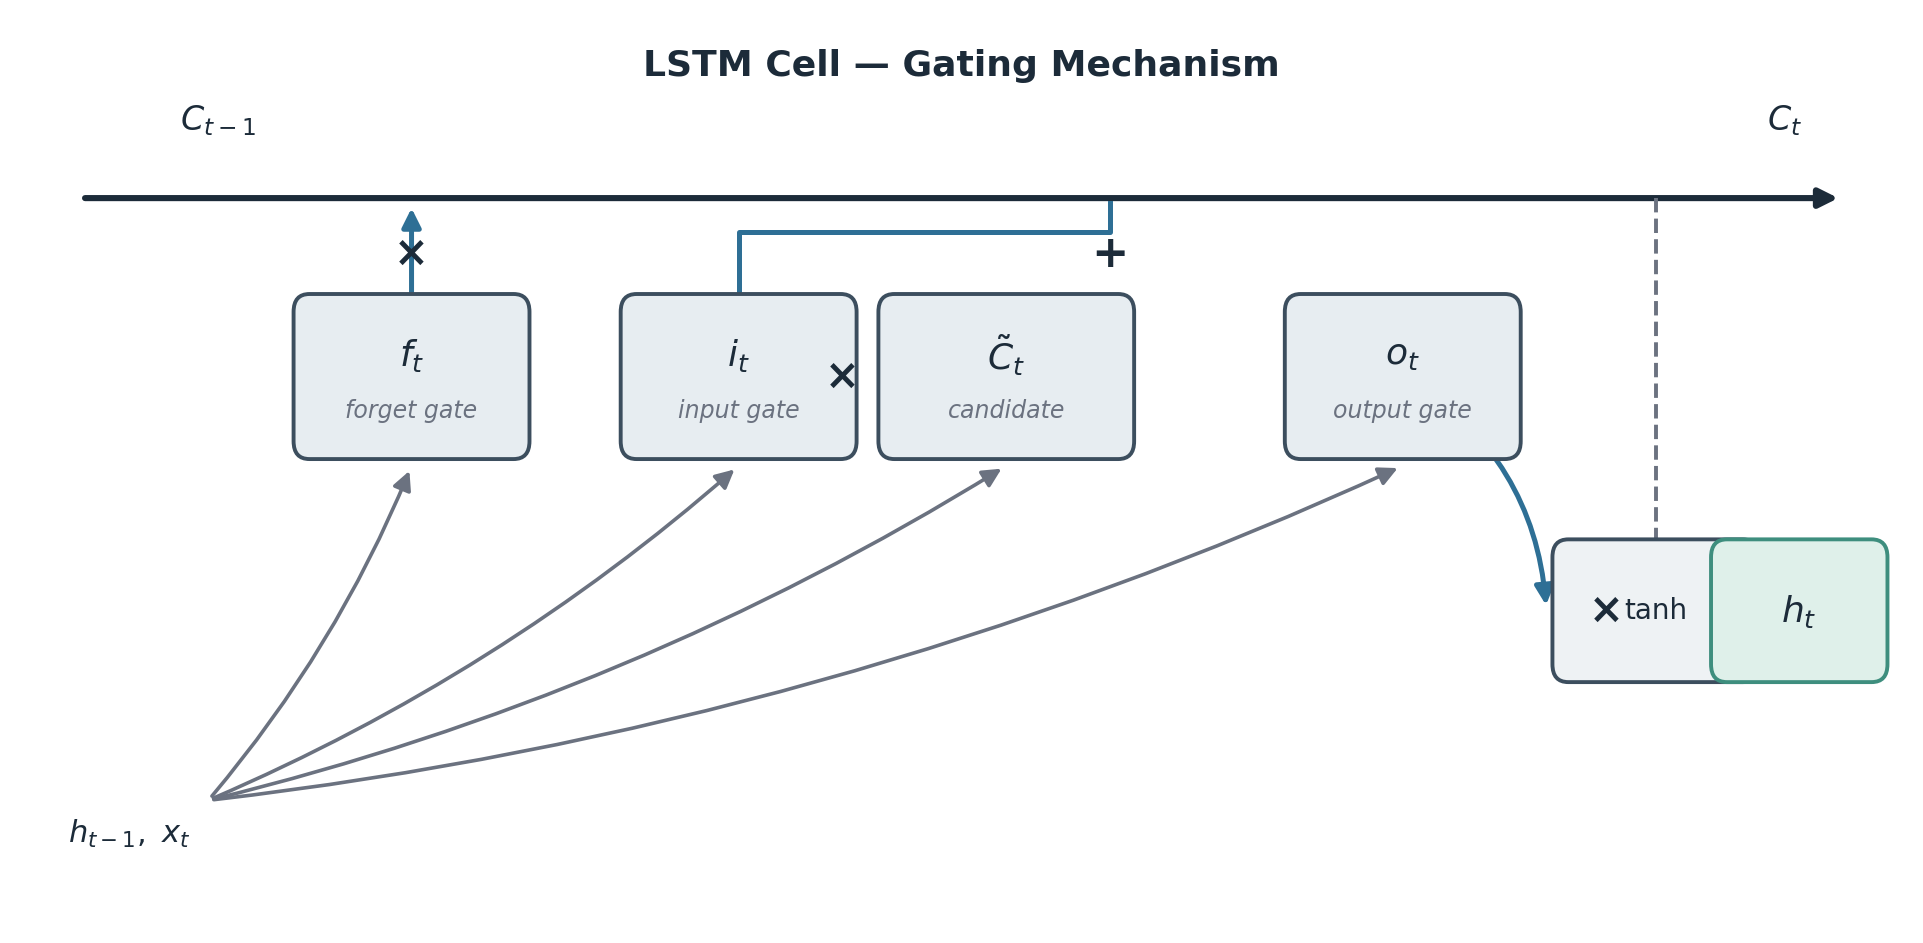

##### 3.2.2 LSTM Cell Formulation

At each timestep, the cell takes the input $x_t$ (the 2D displacement $(\Delta x_t, \Delta y_t)$), the previous hidden state $h_{t-1}$ and the previous cell state $C_{t-1}$, where $[h_{t-1}, x_t]$ denotes their concatenation:

$$
\begin{aligned}
f_t &= \sigma(W_f [h_{t-1}, x_t] + b_f), & i_t &= \sigma(W_i [h_{t-1}, x_t] + b_i), & o_t &= \sigma(W_o [h_{t-1}, x_t] + b_o) \\
\tilde{C}_t &= \tanh(W_c [h_{t-1}, x_t] + b_c), & C_t &= f_t \odot C_{t-1} + i_t \odot \tilde{C}_t, & h_t &= o_t \odot \tanh(C_t)
\end{aligned}
$$

The forget gate $f_t$ discards old memory, the input gate $i_t$ controls how much of the candidate memory $\tilde{C}_t$ is written, and the output gate $o_t$ filters the cell state into the new hidden state $h_t$. $\sigma$ is the sigmoid, $\odot$ the element-wise product, and $W_*$, $b_*$ are learned weights and biases.

##### 3.2.3 Data Preprocessing

The focal agent's trajectory is extracted from the `.parquet` files and stored as `.npy` arrays:

1. **Focal agent:** selected by its `focal` label, or as a fallback, the track with the most observed frames.
2. **Coordinates:** $(x, y)$ positions of the first 75 frames, i.e. a 1.5 s observation window (15 frames) followed by the 6.0 s prediction window (60 frames). This baseline uses 1.5 s of history; all later models use 5 s.
3. **Padding:** tracks shorter than 75 frames repeat their last position.
4. **Serialization:** each split is saved as a single NumPy array to reduce I/O during training.

The cell below runs in demonstration mode on 100 scenarios per split. The full-scale call that produced `Baseline_LSTM_preprocessing_output/` is kept as a comment.

**Baseline LSTM preprocessing (demo mode):** Locates the raw scenario folders `Datasets/train`, `Datasets/val` and `Datasets/test` automatically in the parent directory tree, extracts the focal-agent trajectory (15 + 60 frames) from each scenario, and saves one array per split as `sample_server_{train,val,test}_full_real_coords.npy` (shape `(100, 75, 2)`) in the working directory, printing a confirmation for each split.

In [6]:
# Extraction script that parses raw Argoverse scenario directories into
# consolidated NumPy arrays following the four steps described above.
# Save this as: preprocess_server.py
import os
import glob
import pandas as pd
import numpy as np

def preprocess_av2_folders(source_dir, output_prefix, history_steps=15, future_steps=60, max_files=100):
    print(f" Starting extraction for: {source_dir}")
    scenario_folders = glob.glob(os.path.join(source_dir, "*"))
    scenario_folders = [f for f in scenario_folders if os.path.isdir(f)]
    
    all_trajectories = []
    processed_count = 0
    target_len = history_steps + future_steps

    for folder in scenario_folders:
        parquet_files = glob.glob(os.path.join(folder, "*.parquet"))
        if not parquet_files:
            continue
            
        try:
            df = pd.read_parquet(parquet_files[0])
            
            # --- FLEXIBLE COLUMN CHECKING ---
            category_col = None
            for col in ['category', 'object_type', 'track_category']:
                if col in df.columns:
                    category_col = col
                    break
            
            focal_df = pd.DataFrame()
            if category_col is not None:
                focal_df = df[df[category_col].astype(str).str.contains('focal_agent|focal', case=False, na=False)]
            
            # Fallback strategy
            if len(focal_df) == 0 and 'track_id' in df.columns:
                most_frequent_track = df['track_id'].value_counts().idxmax()
                focal_df = df[df['track_id'] == most_frequent_track]
            
            if len(focal_df) == 0:
                continue
                
            time_col = 'timestep' if 'timestep' in df.columns else 'timestamp'
            focal_df = focal_df.sort_values(by=time_col).reset_index(drop=True)
            
            coords = focal_df[['position_x', 'position_y']].values
            
            # Handle sequence length constraints
            if len(coords) < target_len:
                pad_amt = target_len - len(coords)
                coords = np.vstack([coords, np.tile(coords[-1], (pad_amt, 1))])
            else:
                coords = coords[:target_len]
                
            all_trajectories.append(coords)
            processed_count += 1
            
            # Stop once the sample limit is reached (max_files=None processes everything)
            if max_files is not None and processed_count >= max_files:
                break
            
            # Clean progress tracker every 5,000 files so the terminal stays neat
            if processed_count % 5000 == 0:
                print(f"  -> Extracted {processed_count} scenarios successfully...")
                
        except Exception as e:
            continue

    if all_trajectories:
        final_array = np.stack(all_trajectories, axis=0)
        output_filename = f"{output_prefix}_real_coords.npy"
        np.save(output_filename, final_array)
        print(f"Finished! Saved {processed_count} trajectories (Shape: {final_array.shape}) to {output_filename}\n")
    else:
        print(f"Error: No valid trajectories could be extracted from {source_dir}\n")

# ==================== LOCAL REPOSITORY PATHS ====================

# Using the dynamic self-healing function to find your repository root
def find_local_datasets():
    current_dir = os.getcwd()
    while current_dir != os.path.dirname(current_dir):
        potential_datasets = os.path.join(current_dir, "Datasets")
        if os.path.exists(potential_datasets):
            return potential_datasets
        current_dir = os.path.dirname(current_dir)
    return None

datasets_root = find_local_datasets()

if datasets_root is None:
    print(" Fatal Error: Could not locate your local 'Datasets' folder in the directory tree.")
else:
    print(f" Localizing data stream root at: {datasets_root}")
    
    train_folder = os.path.join(datasets_root, "train")
    val_folder   = os.path.join(datasets_root, "val")
    test_folder  = os.path.join(datasets_root, "test")

    # 1. Train Split Processing
    if os.path.exists(train_folder):
        # preprocess_av2_folders(source_dir=train_folder, output_prefix="server_train_full", max_files=None)  # Full-scale run (all train scenarios) was executed on the server; kept here for reference
        preprocess_av2_folders(source_dir=train_folder, output_prefix="sample_server_train_full", max_files=100)  # Demo run: extracts only 100 scenarios so the workflow runs end-to-end
    else:
        print(f" Missing local directory: {train_folder}")

    # 2. Validation Split Processing
    if os.path.exists(val_folder):
        # preprocess_av2_folders(source_dir=val_folder, output_prefix="server_val_full", max_files=None)  # Full-scale run (all val scenarios) was executed on the server; kept here for reference
        preprocess_av2_folders(source_dir=val_folder, output_prefix="sample_server_val_full", max_files=100)  # Demo run: extracts only 100 scenarios so the workflow runs end-to-end
    else:
        print(f" Missing local directory: {val_folder}")

    # 3. Test Split Processing
    if os.path.exists(test_folder):
        # preprocess_av2_folders(source_dir=test_folder, output_prefix="server_test_full", max_files=None)  # Full-scale run (all test scenarios) was executed on the server; kept here for reference
        preprocess_av2_folders(source_dir=test_folder, output_prefix="sample_server_test_full", max_files=100)  # Demo run: extracts only 100 scenarios so the workflow runs end-to-end
    else:
        print(f" Missing local directory: {test_folder}")

 Localizing data stream root at: /home/jovyan/acdc/topics/16-Motion-Forecasting/report_2/Datasets
 Starting extraction for: /home/jovyan/acdc/topics/16-Motion-Forecasting/report_2/Datasets/train
Finished! Saved 100 trajectories (Shape: (100, 75, 2)) to sample_server_train_full_real_coords.npy

 Starting extraction for: /home/jovyan/acdc/topics/16-Motion-Forecasting/report_2/Datasets/val
Finished! Saved 100 trajectories (Shape: (100, 75, 2)) to sample_server_val_full_real_coords.npy

 Starting extraction for: /home/jovyan/acdc/topics/16-Motion-Forecasting/report_2/Datasets/test
Finished! Saved 100 trajectories (Shape: (100, 75, 2)) to sample_server_test_full_real_coords.npy



##### 3.2.4 Compute Environment

Training ran on an NVIDIA A40 GPU (47.7 GB VRAM). Available GPU memory is checked before model instantiation to confirm headroom for the chosen batch size.

**GPU diagnostics:** Selects the compute device (`device`, used by all later PyTorch cells), prints the GPU name with total and free memory, and warns if it falls back to CPU.

In [8]:
# Environment Verification & Advanced GPU Diagnostics
import sys
import torch
import numpy as np

if torch.cuda.is_available():
    device = torch.device("cuda")
    
    # Extract structural memory stats from the hardware properties
    gpu_properties = torch.cuda.get_device_properties(0)
    total_memory_gb = gpu_properties.total_memory / 1e9
    
    # Query runtime allocated memory via PyTorch cache manager
    allocated_memory_gb = torch.cuda.memory_allocated(0) / 1e9
    cached_memory_gb = torch.cuda.memory_reserved(0) / 1e9
    
    # Calculate actual physical overhead available right now
    free_memory_gb = total_memory_gb - allocated_memory_gb
    
    print(f" System successfully mapped to GPU Acceleration pipeline!")
    print(f"   ------------------------------------------------")
    print(f"   Device Name           : {gpu_properties.name}")
    print(f"   Total Compute VRAM    : {total_memory_gb:.2f} GB")
    print(f"   Currently Allocated   : {allocated_memory_gb:.2f} GB")
    print(f"   Currently Free VRAM   : {free_memory_gb:.2f} GB")
    print(f"   ------------------------------------------------")
    
    # Smart threshold safety warning system
    # A Vanilla Seq2Seq LSTM batch size of 128 needs roughly 2 to 4 GB of free overhead
    if free_memory_gb > 4.0:
        print(f"Ample VRAM available for progressive scaling (50k+).")
    elif free_memory_gb > 1.5:
        print(f"VRAM is tight. Consider keeping batch_size at 64 or 128 max.")
    else:
        print(f"Very little VRAM left. Clear your notebook kernel memory cache.")
else:
    device = torch.device("cpu")
    print(f" WARNING: No GPU detected. System fell back to stable CPU pipeline.")

 System successfully mapped to GPU Acceleration pipeline!
   ------------------------------------------------
   Device Name           : NVIDIA A40
   Total Compute VRAM    : 47.73 GB
   Currently Allocated   : 0.00 GB
   Currently Free VRAM   : 47.73 GB
   ------------------------------------------------
Ample VRAM available for progressive scaling (50k+).


##### 3.2.5 Network Architecture

The baseline is an **encoder–decoder** that operates on displacements $(\Delta x, \Delta y)$ rather than absolute coordinates. This removes the dependence on the map frame and stabilizes optimization.

1. **Encoder:** an `nn.LSTM` condenses the observed displacements into a final hidden state $h_{enc}$ and cell state $c_{enc}$.
2. **Decoder:** an autoregressive `nn.LSTMCell` predicts the 60 future steps. It starts from the last observed displacement and then feeds back its own previous output.
3. **Regularization:** dropout ($p = 0.2$) on the decoder hidden state.
4. **Regression head:** an `nn.Linear` layer maps the 128-dimensional hidden state to $(\Delta x_t, \Delta y_t)$.

The diagram below shows this architecture.

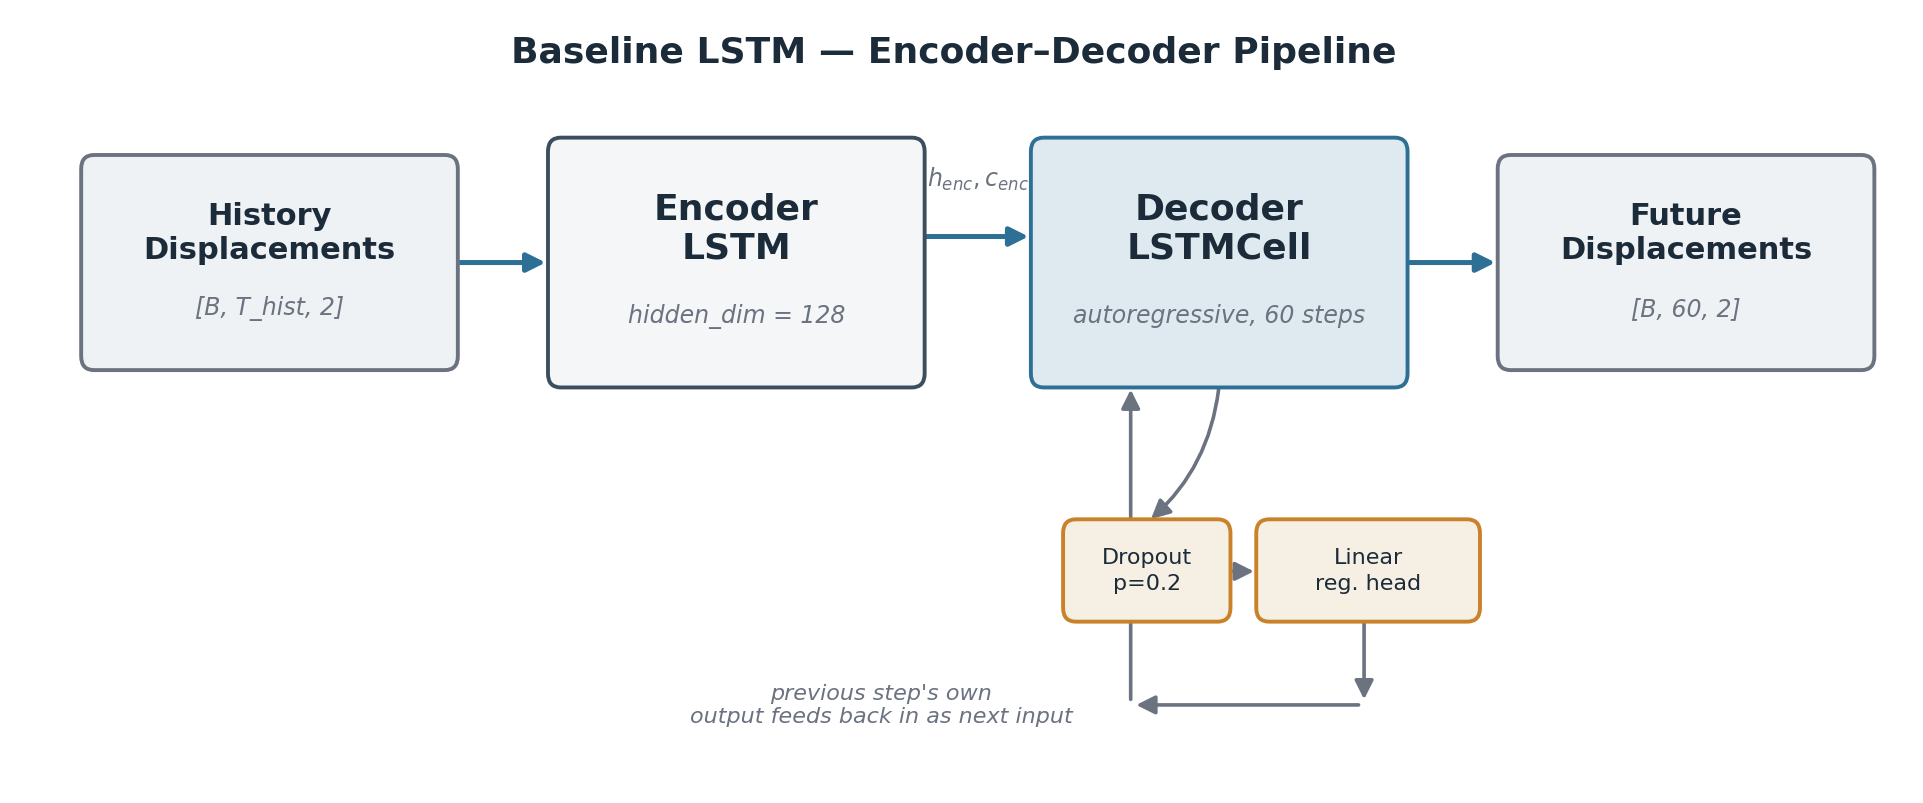

**Baseline LSTM model definition:** Defines the `VanillaSeq2SeqLSTM` encoder–decoder described above. Its forward pass takes history displacements of shape `(B, T_hist, 2)` and returns predicted displacements of shape `(B, 60, 2)`, with no printed output.

In [9]:
# Optimized Matching Model Architecture (LSTMCell with Regularization)
import torch
import torch.nn as nn

class VanillaSeq2SeqLSTM(nn.Module):
    def __init__(self, input_dim=2, hidden_dim=128, output_dim=2, horizon=60):
        super(VanillaSeq2SeqLSTM, self).__init__()
        self.hidden_dim = hidden_dim
        self.horizon = horizon
        
        # 1. Encoder LSTM: Processes historical timesteps
        self.encoder = nn.LSTM(
            input_size=input_dim, 
            hidden_size=hidden_dim, 
            batch_first=True
        )
        
        # 2. Decoder LSTM Cell: Steps through the future timesteps autoregressively
        self.decoder_cell = nn.LSTMCell(
            input_size=input_dim, 
            hidden_size=hidden_dim
        )
        
        # REGULARIZATION LAYER: Prevents memorization during the 200k data scaling sprint
        self.dropout = nn.Dropout(p=0.2)
        
        # 3. Output Regression Head: Maps features back to 2D spatial displacements
        self.regression_head = nn.Linear(hidden_dim, output_dim)

    def forward(self, history_displacements):
        """
        Args:
            history_displacements (Tensor): Shape (Batch_Size, T_hist, 2) -> (dx, dy)
        Returns:
            predicted_displacements (Tensor): Shape (Batch_Size, 60, 2) -> Predicted (dx, dy)
        """
        batch_size = history_displacements.size(0)
        
        # --- ENCODER STEP ---
        _, (h, c) = self.encoder(history_displacements)
        
        # Squeeze out the layer dimension safely (dim 0)
        h_t = h.squeeze(0)
        c_t = c.squeeze(0)
        
        # --- DECODER STEP ---
        # Seed the autoregressive loop with the very last observed displacement step
        decoder_input = history_displacements[:, -1, :] 
        
        predicted_displacements = []
        
        # Loop exactly through the future horizon
        for t in range(self.horizon):
            # Feed current 2D input and previous hidden states into the LSTM Cell
            h_t, c_t = self.decoder_cell(decoder_input, (h_t, c_t))
            
            # APPLY DROPOUT: Active during training, automatically bypassed in model.eval()
            h_t_regularized = self.dropout(h_t)
            
            # Map regularized hidden representation to spatial delta (dx, dy)
            delta_pred = self.regression_head(h_t_regularized)
            predicted_displacements.append(delta_pred)
            
            # Autoregressive feedback tracking
            decoder_input = delta_pred
            
        # Stack individual steps into a single continuous tensor: (Batch_Size, 60, 2)
        predicted_displacements = torch.stack(predicted_displacements, dim=1)
        return predicted_displacements

##### 3.2.6 Training Utilities

A custom PyTorch `Dataset` converts the stored coordinates into displacement sequences on the fly. Batches of 128 scenarios are loaded with pinned memory and four worker processes for faster GPU transfer.

**Training routines and setup:** Defines `train_one_epoch` and `validate_one_epoch`, which rebuilds positions by cumulative summation and reports validation ADE/FDE. It also instantiates `VanillaSeq2SeqLSTM` on `device` with the Adam optimizer ($\eta = 10^{-3}$) and Smooth L1 loss. It prints a confirmation only; no training runs here.

In [10]:
# Optimization Configuration & Production Training Setup with ADE/FDE Tracking
import torch
import torch.optim as optim
import numpy as np
import time

def train_one_epoch(model, dataloader, optimizer, loss_criterion, device, epoch=1):
    """
    Trains the model for a single epoch over the training dataset.
    Optimized for high-speed GPU execution using asynchronous memory transfers.
    """
    model.train()  # Put the model in training mode
    running_loss = 0.0
    print(f"\n [Epoch {epoch}] Starting training on {len(dataloader.dataset)} tracks...")
    start_time = time.time()
    
    for batch_idx, batch in enumerate(dataloader):
        # 1. Asynchronous data transfer to GPU
        history_displacements = batch['history_displacements'].to(device, non_blocking=True)
        ground_truth_future = batch['future_displacements'].to(device, non_blocking=True)
        
        # 2. Optimization pass steps
        optimizer.zero_grad()
        pred_displacements = model(history_displacements)
        loss = loss_criterion(pred_displacements, ground_truth_future)
        
        # 3. Backward Pass & weight updates
        loss.backward()
        optimizer.step()
        
        running_loss += loss.item()
        
        # Real-time progress tracking
        if batch_idx % 20 == 0 or (batch_idx + 1) == len(dataloader):
            print(f"        Step {batch_idx+1:04d}/{len(dataloader)} processed | Mini-Batch Loss: {loss.item():.5f}", end="\r")
            
    epoch_loss = running_loss / len(dataloader)
    elapsed = time.time() - start_time
    print(f"\n [Epoch {epoch}] Training complete. Average Train Loss: {epoch_loss:.5f} | Time: {elapsed:.1f}s")
    return epoch_loss

def validate_one_epoch(model, dataloader, loss_criterion, device, epoch=1):
    """
    Evaluates model displacement loss and computes Global Average ADE and FDE metrics 
    across the hold-out validation slice.
    """
    model.eval()  # Put the model in evaluation mode
    running_loss = 0.0
    
    # Lists to store spatial error metrics for every single track in the batch
    all_ades = []
    all_fdes = []
    
    print(f" [Epoch {epoch}] Moving to Validation Split ({len(dataloader.dataset)} tracks)...")
    
    with torch.no_grad():
        for batch_idx, batch in enumerate(dataloader):
            history_displacements = batch['history_displacements'].to(device, non_blocking=True)
            ground_truth_future = batch['future_displacements'].to(device, non_blocking=True)
            
            # 1. Compute validation loss
            pred_displacements = model(history_displacements)
            loss = loss_criterion(pred_displacements, ground_truth_future)
            running_loss += loss.item()
            
            # 2. Reconstruct trajectory positions by cumulatively summing displacement vectors
            # Assuming origin (0,0) at the final step of history
            pred_traj = torch.cumsum(pred_displacements, dim=1)
            gt_traj   = torch.cumsum(ground_truth_future, dim=1)
            
            # 3. Compute absolute L2 Euclidean distances: sqrt((x_p - x_g)^2 + (y_p - y_g)^2)
            spatial_errors = torch.norm(pred_traj - gt_traj, p=2, dim=2)  # Shape: (batch_size, 60)
            
            # Average Displacement Error (ADE): mean over the 60 timesteps horizon
            batch_ade = torch.mean(spatial_errors, dim=1).cpu().numpy()
            # Final Displacement Error (FDE): displacement at the final timestep index (59)
            batch_fde = spatial_errors[:, -1].cpu().numpy()
            
            all_ades.extend(batch_ade)
            all_fdes.extend(batch_fde)
            
            if batch_idx % 20 == 0 or (batch_idx + 1) == len(dataloader):
                print(f"         Val Step {batch_idx+1:04d}/{len(dataloader)} evaluated...", end="\r")
            
    val_loss = running_loss / len(dataloader)
    avg_ade = np.mean(all_ades)
    avg_fde = np.mean(all_fdes)
    
    #  THE MENTOR LIVE MONITORING PANEL
    print(f"\n================================================================")
    print(f" PERFORMANCE DASHBOARD - END OF EPOCH {epoch}")
    print(f"----------------------------------------------------------------")
    print(f" Average Validation Loss : {val_loss:.5f}")
    print(f" Global Average ADE      : {avg_ade:.3f} meters")
    print(f" Global Average FDE      : {avg_fde:.3f} meters")
    print(f"================================================================")
    
    return val_loss, avg_ade, avg_fde

# --- CORE HARDWARE & ARCHITECTURE INITIALIZATION ---
# Instantiating the clean model onto our newly verified GPU pipeline
model = VanillaSeq2SeqLSTM(
    input_dim=2, 
    hidden_dim=128, 
    output_dim=2, 
    horizon=60
).to(device)

# Adam optimizer configuration
optimizer = optim.Adam(model.parameters(), lr=0.001)

# Smooth L1 (Huber Loss) criterion for spatial stability
loss_criterion = torch.nn.SmoothL1Loss()

print(f" Training pipeline successfully configured on device: {device}")

# ======================================================================


 Training pipeline successfully configured on device: cuda


**Dataset class and DataLoaders:** Defines `AV2RealBinaryDataset` (15-frame history, 60-frame target, converted to displacements) and builds `lstm_train_loader` and `lstm_val_loader` from `Baseline_LSTM_preprocessing_output/server_{train,val}_full_real_coords.npy`. It prints the number of scenarios and batches per split.

In [11]:
# Progressive Scale Dataset Configuration & High-Speed Loader Setup
import torch
from torch.utils.data import Dataset, DataLoader, Subset
import numpy as np

class AV2RealBinaryDataset(Dataset):
    def __init__(self, npy_file, history_steps=15, future_steps=60):
        print(f" Loading real-world trajectory arrays from: {npy_file}")
        self.coords = np.load(npy_file)
        self.history_steps = history_steps
        self.future_steps = future_steps

    def __len__(self):
        return self.coords.shape[0]
    
    def __getitem__(self, idx):
        coords = self.coords[idx]
        
        # Slice raw trajectories into history and future frames
        history_coords = coords[:self.history_steps]
        future_coords = coords[self.history_steps:]
        
        # Calculate localized step-by-step displacement vectors (dx, dy)
        hist_disp = np.zeros_like(history_coords)
        hist_disp[1:] = history_coords[1:] - history_coords[:-1]
        hist_disp[0] = hist_disp[1] # Handle boundary edge case
        
        fut_disp = np.zeros_like(future_coords)
        fut_disp[0] = future_coords[0] - history_coords[-1]
        fut_disp[1:] = future_coords[1:] - future_coords[:-1]
        
        return {
            'history_displacements': torch.tensor(hist_disp, dtype=torch.float32),
            'future_displacements': torch.tensor(fut_disp, dtype=torch.float32),
            'history_positions': torch.tensor(history_coords, dtype=torch.float32),
            'future_positions': torch.tensor(future_coords, dtype=torch.float32)
        }

# 1. Load the underlying data matrices
print(" Loading full server numpy matrices into memory...")
full_train_dataset = AV2RealBinaryDataset(npy_file="Baseline_LSTM_preprocessing_output/server_train_full_real_coords.npy")
full_val_dataset   = AV2RealBinaryDataset(npy_file="Baseline_LSTM_preprocessing_output/server_val_full_real_coords.npy")

# =========================================================
# PROGRESSIVE SCALE CONFIGURATION PANEL
# =========================================================
max_train_scenarios = 200000  

# Dynamic Safety Check: Ensure we don't request more than what actually exists in the train file
train_limit = min(max_train_scenarios, len(full_train_dataset))

# Create subsets safely
train_subset = Subset(full_train_dataset, range(train_limit))
# Grab the COMPLETE validation file automatically without hardcoding bounds
val_subset   = Subset(full_val_dataset, range(len(full_val_dataset)))

# 3. HIGH-SPEED GPU-OPTIMIZED DATALOADERS (Batch size 128)
lstm_train_loader = DataLoader(
    train_subset, 
    batch_size=128, 
    shuffle=True, 
    num_workers=4, 
    pin_memory=True
)

lstm_val_loader = DataLoader(
    val_subset, 
    batch_size=128, 
    shuffle=False, 
    num_workers=4, 
    pin_memory=True
)

print(f"\n Progressive Training Scale Locked In!")
print(f"  Training Split   : {len(train_subset)} tracks ({len(lstm_train_loader)} batches)")
print(f"  Validation Split : {len(val_subset)} tracks ({len(lstm_val_loader)} batches) [COMPLETE FILE LOADED]")

 Loading full server numpy matrices into memory...
 Loading real-world trajectory arrays from: Baseline_LSTM_preprocessing_output/server_train_full_real_coords.npy
 Loading real-world trajectory arrays from: Baseline_LSTM_preprocessing_output/server_val_full_real_coords.npy

 Progressive Training Scale Locked In!
  Training Split   : 199908 tracks (1562 batches)
  Validation Split : 24988 tracks (196 batches) [COMPLETE FILE LOADED]


##### 3.2.7 Dimensionality Verification

Before training, input and output tensor shapes are verified end-to-end: the historical input tensor of shape $(B, T_{hist}, 2)$ must propagate through the encoder–decoder loop to a predicted displacement tensor matching the target shape $(B, 60, 2)$.

**Shape and device sanity check:** Passes one batch from `lstm_val_loader` through the untrained `model` on `device` and prints the input, output and target shapes and devices, followed by a success or mismatch message.

In [12]:
# Pipeline Shape & Device Sanity Check
model.eval()  # Put model in evaluation mode

# Grab exactly one batch from your static validation loader to ensure absolute test consistency
sample_batch = next(iter(lstm_val_loader))

# Extract displacements and send them asynchronously to the active compute hardware core
hist_disp = sample_batch['history_displacements'].to(device, non_blocking=True)
true_fut_disp = sample_batch['future_displacements'].to(device, non_blocking=True)

print("--- HARDWARE TARGET CHECK ---")
print(f"Model Execution Device             : {next(model.parameters()).device}")
print(f"Tensor Compute Memory Allocation   : {hist_disp.device}")

print("\n--- INPUT DATA SHAPES ---")
print(f"History Displacements Shape (Input) : {hist_disp.shape}  -> Expected: (Batch_Size, 15, 2)")
print(f"Future Displacements Shape (Target) : {true_fut_disp.shape}  -> Expected: (Batch_Size, 60, 2)")

# Pass through the Encoder-Decoder network without tracking gradients
with torch.no_grad():
    pred_disp = model(hist_disp)

print("\n--- OUTPUT DATA SHAPE ---")
print(f"Predicted Displacements Shape       : {pred_disp.shape}  -> Expected: (Batch_Size, 60, 2)")

if pred_disp.shape == true_fut_disp.shape:
    print("\n Success! The model output matches the target evaluation horizon perfectly.")
else:
    print("\n Dimension mismatch! Check the decoder loop horizon configuration.")

--- HARDWARE TARGET CHECK ---
Model Execution Device             : cuda:0
Tensor Compute Memory Allocation   : cuda:0

--- INPUT DATA SHAPES ---
History Displacements Shape (Input) : torch.Size([128, 15, 2])  -> Expected: (Batch_Size, 15, 2)
Future Displacements Shape (Target) : torch.Size([128, 60, 2])  -> Expected: (Batch_Size, 60, 2)

--- OUTPUT DATA SHAPE ---
Predicted Displacements Shape       : torch.Size([128, 60, 2])  -> Expected: (Batch_Size, 60, 2)

 Success! The model output matches the target evaluation horizon perfectly.


##### 3.2.8 Training Procedure

The model is trained with the **Huber (Smooth L1) loss** on displacements, which is less sensitive to outliers than L2 loss:

- **Optimizer:** Adam, $\eta = 10^{-3}$.
- **Scheduler:** `ReduceLROnPlateau` on validation ADE, halving the learning rate after 2 epochs without improvement.
- **Checkpointing:** 35 epochs without early stopping; the checkpoint with the lowest validation ADE is kept. That was epoch 34, at 2.305 m.

**ADE/FDE helper:** Defines `calculate_ade_fde`, which takes predicted and ground-truth displacements of shape `(B, 60, 2)`, reconstructs positions by cumulative summation and returns the batch-mean ADE and FDE. It is reused in Section 5.1.2.

In [13]:
# Performance Evaluation Metrics (ADE / FDE)
import torch

def calculate_ade_fde(pred_displacements, future_displacements):
    """
    Computes Average Displacement Error (ADE) and Final Displacement Error (FDE)
    by reconstructing paths from consecutive coordinate offsets.
    
    Args:
        pred_displacements (Tensor): Model spatial step outputs. Shape: (Batch_Size, 60, 2)
        future_displacements (Tensor): Ground truth spatial steps. Shape: (Batch_Size, 60, 2)
    Returns:
        ade (float): Global Average Displacement Error over the 6.0s horizon.
        fde (float): Final Displacement Error at the 6.0s mark.
    """
    # 1. Reconstruct trajectories by tracking cumulative distance covered from origin (0,0)
    # This cancels out any absolute world coordinate coordinate bias (e.g., UTM grid offsets)
    pred_positions = torch.cumsum(pred_displacements, dim=1)
    true_positions = torch.cumsum(future_displacements, dim=1)
    
    # 2. Compute the absolute L2 Euclidean distance vector at every single timestep
    # Shape: (Batch_Size, 60)
    displacement_errors = torch.norm(pred_positions - true_positions, p=2, dim=2)
    
    # 3. ADE: Mean across both the temporal dimension (60 steps) and the batch dimension
    ade = torch.mean(displacement_errors).item()
    
    # 4. FDE: Euclidean distance isolated at the very final timestep (index -1 or 59)
    fde = torch.mean(displacement_errors[:, -1]).item()
    
    return ade, fde

print(" Mathematically validated ADE and FDE tracking functions compiled.")

 Mathematically validated ADE and FDE tracking functions compiled.


**Demonstration mode:** By default (`DEMO_MODE = True`), the cell below trains for 2 epochs on 100 training and 100 validation scenarios and saves `lstm_best_weights_demo.pt`. `DEMO_MODE = False` runs the full training of Section 3.2.8 and saves `lstm_best_weights_200k_tuned.pt` in the working directory.

**Baseline LSTM training loop:** Trains `VanillaSeq2SeqLSTM` using `train_one_epoch` and `validate_one_epoch`, with learning-rate scheduling and best-checkpoint saving (Section 3.2.8). In demonstration mode it uses small DataLoaders built from the datasets of Section 3.2.6; in full mode it uses `lstm_train_loader` and `lstm_val_loader`. It prints the mode, the training loss, validation loss, ADE and FDE per epoch, and the path of the saved weights.

In [16]:
# Multi-Epoch Training Loop with Learning Rate Scheduling
import time
import torch
from torch.utils.data import DataLoader, Subset

# =========================================================
# EXECUTION MODE
#   DEMO_MODE = True  -> quick check: 100 train / 100 val samples, 2 epochs
#   DEMO_MODE = False -> full training: all loaded tracks, 35 epochs
# =========================================================
DEMO_MODE = True

DEMO_TRAIN_SAMPLES = 100
DEMO_VAL_SAMPLES = 100
DEMO_EPOCHS = 2

if DEMO_MODE:
    CURRENT_SCALE = "demo"
    NUM_EPOCHS = DEMO_EPOCHS
    # Small subsets drawn from the datasets loaded above. Separate loader
    # names keep lstm_train_loader / lstm_val_loader intact for later cells.
    train_loader_run = DataLoader(
        Subset(full_train_dataset, range(min(DEMO_TRAIN_SAMPLES, len(full_train_dataset)))),
        batch_size=32, shuffle=True, num_workers=0,
    )
    val_loader_run = DataLoader(
        Subset(full_val_dataset, range(min(DEMO_VAL_SAMPLES, len(full_val_dataset)))),
        batch_size=32, shuffle=False, num_workers=0,
    )
else:
    CURRENT_SCALE = "200k_tuned"
    NUM_EPOCHS = 35
    train_loader_run = lstm_train_loader
    val_loader_run = lstm_val_loader

# Save directly in the working directory (Report/) to avoid subfolder permission errors.
# The demo run writes to its own file, so the fully trained weights are never overwritten.
model_save_path = f"lstm_best_weights_{CURRENT_SCALE}.pt"

# RE-INITIALIZE OPTIMIZATION PIPELINE WITH SCHEDULER
model = VanillaSeq2SeqLSTM().to(device)
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)

scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer,
    mode='min',
    factor=0.5,
    patience=2,
)

print(f" Mode                : {'DEMO' if DEMO_MODE else 'FULL'} "
      f"({len(train_loader_run.dataset)} train / {len(val_loader_run.dataset)} val tracks, {NUM_EPOCHS} epochs)")
print(f" Launching training loop on device: {device}")
print(f" Optimal Weight Path : {model_save_path}\n")
print("=" * 80)

best_val_ade = float('inf')

for epoch in range(1, NUM_EPOCHS + 1):
    start_time = time.time()

    epoch_train_loss = train_one_epoch(model, train_loader_run, optimizer, loss_criterion, device, epoch=epoch)
    epoch_val_loss, epoch_avg_ade, epoch_avg_fde = validate_one_epoch(model, val_loader_run, loss_criterion, device, epoch=epoch)

    scheduler.step(epoch_avg_ade)
    epoch_time = time.time() - start_time

    if epoch_avg_ade < best_val_ade:
        best_val_ade = epoch_avg_ade
        torch.save({
            'scale_tag': CURRENT_SCALE,
            'epoch': epoch,
            'model_state_dict': model.state_dict(),
            'optimizer_state_dict': optimizer.state_dict(),
            'val_loss': epoch_val_loss,
            'avg_ade': epoch_avg_ade,
            'avg_fde': epoch_avg_fde,
        }, model_save_path, _use_new_zipfile_serialization=False)
        print(f"     New lowest Average ADE achieved! Checkpoint saved to: {model_save_path}")

    print(f" Epoch [{epoch:02d}/{NUM_EPOCHS:02d}] Runtime Overhead: {epoch_time:.1f} seconds")
    print("-" * 80)

print(f"\n Training cycle for {CURRENT_SCALE} complete! Weights are locked in.")

 Mode                : DEMO (100 train / 100 val tracks, 2 epochs)
 Launching training loop on device: cuda
 Optimal Weight Path : lstm_best_weights_demo.pt


 [Epoch 1] Starting training on 100 tracks...
        Step 0004/4 processed | Mini-Batch Loss: 0.31922
 [Epoch 1] Training complete. Average Train Loss: 0.17643 | Time: 0.1s
 [Epoch 1] Moving to Validation Split (100 tracks)...
         Val Step 0004/4 evaluated...
 PERFORMANCE DASHBOARD - END OF EPOCH 1
----------------------------------------------------------------
 Average Validation Loss : 0.16951
 Global Average ADE      : 18.286 meters
 Global Average FDE      : 36.544 meters
     New lowest Average ADE achieved! Checkpoint saved to: lstm_best_weights_demo.pt
 Epoch [01/02] Runtime Overhead: 0.2 seconds
--------------------------------------------------------------------------------

 [Epoch 2] Starting training on 100 tracks...
        Step 0004/4 processed | Mini-Batch Loss: 0.17794
 [Epoch 2] Training complete. Average 

The Vanilla LSTM outperforms both kinematic baselines (Section 5.1.2) but ignores neighboring agents and road topology. The next section adds agent interaction through a socially-aware multimodal architecture.

#### 3.3 Social Interaction-Aware Multimodal Forecasting

This stage drops the single-agent assumption. A **Social Multi-Head Attention (MHA) encoder** models interaction with neighboring agents, and an autoregressive **multimodal recurrent decoder** outputs $K = 6$ candidate trajectories per scenario, each with a confidence score.

##### 3.3.1 Multi-Agent Scene Preprocessing

- **Scenario structure:** each scenario is a tensor of shape $(11, 110, 2)$: the focal agent (index 0) and up to 10 background actors over $T_{hist} = 50$ steps (5 s at 10 Hz) plus $T_{fut} = 60$ steps (6 s).
- **Actor extraction:** the first 10 background actors in the file with at least 5 observations are kept. Each is padded to 110 steps by repeating its last position; unused slots stay zero.
- **Focal-centric frame:** at load time, all coordinates are shifted relative to the focal agent's position at the observation boundary (frame 49):

$$\mathbf{p}_{i,t}^{\text{local}} = \mathbf{p}_{i,t} - \mathbf{p}_{\text{focal},49}$$

- **Neighbor selection:** the 5 actors closest to the focal agent at frame 49 are retained. Missing entries are zero-padded and flagged by a boolean mask $\mathbf{M} \in \{0,1\}^{B \times 5}$.
- **Input encoding:** the focal agent's trajectory is converted to displacements $(\Delta x_t, \Delta y_t)$ as in Section 3.2.5, with the first element holding the focal-centric start position. Neighbor histories are passed as focal-centric positions.

The extraction cell below builds these arrays from the same `Datasets/` folders as Section 3.2.3, in demonstration mode on 100 scenarios per split. The full-scale call that produced `Social_LSTM_output/` is kept as a comment. The `ArgoverseSocialDataset` class in the next cell wraps the arrays for loading.

**Multi-agent preprocessing (demo mode):** Extracts the focal agent and up to 10 background actors (110 frames each) from the raw scenario folders `Datasets/{train,val,test}` and saves one array per split as `sample_server_{train,val,test}_11s_multi_agent_coords.npy` (shape `(100, 11, 110, 2)`) in the working directory.

In [17]:
# Preprocessing for Social pooling LSTM
import os
import glob
import pandas as pd
import numpy as np

def preprocess_av2_social_folders(source_dir, output_prefix, max_actors_per_scene=11, history_steps=50, future_steps=60, max_files=100):
    """
    Upgraded preprocessing script to extract the Focal Agent AND surrounding actors.
    Saves a 4D array of shape: (Num_Scenarios, Max_Actors_Per_Scene, 110, 2)
    """
    print(f" Starting multi-agent extraction for: {source_dir}")
    scenario_folders = glob.glob(os.path.join(source_dir, "*"))
    scenario_folders = [f for f in scenario_folders if os.path.isdir(f)]
    
    all_scenes = []
    processed_count = 0
    target_len = history_steps + future_steps  # 110 timesteps (5s history + 6s future @ 10Hz)

    for folder in scenario_folders:
        parquet_files = glob.glob(os.path.join(folder, "*.parquet"))
        if not parquet_files:
            continue
            
        try:
            df = pd.read_parquet(parquet_files[0])
            
            # 1. Identify category column flexibly
            category_col = None
            for col in ['category', 'object_type', 'track_category']:
                if col in df.columns:
                    category_col = col
                    break
            
            # 2. Extract the Focal Agent track
            focal_df = pd.DataFrame()
            if category_col is not None:
                focal_df = df[df[category_col].astype(str).str.contains('focal_agent|focal', case=False, na=False)]
            
            if len(focal_df) == 0 and 'track_id' in df.columns:
                most_frequent_track = df['track_id'].value_counts().idxmax()
                focal_df = df[df['track_id'] == most_frequent_track]
            
            if len(focal_df) == 0:
                continue
                
            time_col = 'timestep' if 'timestep' in df.columns else 'timestamp'
            focal_df = focal_df.sort_values(by=time_col).reset_index(drop=True)
            focal_id = focal_df['track_id'].iloc[0] if 'track_id' in focal_df.columns else None
            
            # Multi-agent matrix placeholder for this scene: Shape (11, 110, 2)
            scene_matrix = np.zeros((max_actors_per_scene, target_len, 2), dtype=np.float32)
            
            # Assign Focal Agent to INDEX 0
            focal_coords = focal_df[['position_x', 'position_y']].values
            if len(focal_coords) < target_len:
                pad_amt = target_len - len(focal_coords)
                focal_coords = np.vstack([focal_coords, np.tile(focal_coords[-1], (pad_amt, 1))])
            else:
                focal_coords = focal_coords[:target_len]
            scene_matrix[0] = focal_coords
            
            # 3. Extract Surrounding Actors (Exclude focal agent)
            if 'track_id' in df.columns and focal_id is not None:
                neighbor_dfs = df[df['track_id'] != focal_id]
                unique_neighbors = neighbor_dfs['track_id'].unique()
                
                actor_idx = 1
                for n_id in unique_neighbors:
                    if actor_idx >= max_actors_per_scene:
                        break  # Reached the storage ceiling for this scene
                        
                    n_df = neighbor_dfs[neighbor_dfs['track_id'] == n_id].sort_values(by=time_col)
                    n_coords = n_df[['position_x', 'position_y']].values
                    
                    if len(n_coords) < 5:  # Filter out transient tracking noise
                        continue
                        
                    # Pad or truncate neighbor tracks uniformly to 110 timesteps
                    if len(n_coords) < target_len:
                        pad_amt = target_len - len(n_coords)
                        n_coords = np.vstack([n_coords, np.tile(n_coords[-1], (pad_amt, 1))])
                    else:
                        n_coords = n_coords[:target_len]
                        
                    scene_matrix[actor_idx] = n_coords
                    actor_idx += 1
            
            all_scenes.append(scene_matrix)
            processed_count += 1
            
            # Stop once the sample limit is reached (max_files=None processes everything)
            if max_files is not None and processed_count >= max_files:
                break
            
            if processed_count % 5000 == 0:
                print(f"  -> Extracted {processed_count} scenarios successfully...")
                
        except Exception as e:
            continue

    if all_scenes:
        final_array = np.stack(all_scenes, axis=0)
        output_filename = f"{output_prefix}_multi_agent_coords.npy"
        np.save(output_filename, final_array)
        print(f" Finished! Saved {processed_count} scenarios (Shape: {final_array.shape}) to {output_filename}\n")
    else:
        print(f" Error: No valid trajectories could be extracted from {source_dir}\n")


# ==================== RUN COMPILATION PIPELINE ====================

def find_local_datasets():
    current_dir = os.getcwd()
    while current_dir != os.path.dirname(current_dir):
        potential_datasets = os.path.join(current_dir, "Datasets")
        if os.path.exists(potential_datasets):
            return potential_datasets
        current_dir = os.path.dirname(current_dir)
    return None

datasets_root = find_local_datasets()

if datasets_root is None:
    print(" Fatal Error: Could not locate your local 'Datasets' folder in the directory tree.")
else:
    print(f" Localizing data stream root at: {datasets_root}")
    
    train_folder = os.path.join(datasets_root, "train")
    val_folder   = os.path.join(datasets_root, "val")
    test_folder  = os.path.join(datasets_root, "test")

    # Outputs: server_train_11s_multi_agent_coords.npy
    if os.path.exists(train_folder):
        # preprocess_av2_social_folders(source_dir=train_folder, output_prefix="server_train_11s", max_files=None)  # Full-scale run (all train scenarios) was executed on the server; kept here for reference
        preprocess_av2_social_folders(source_dir=train_folder, output_prefix="sample_server_train_11s", max_files=100)  # Demo run: extracts only 100 scenarios so the workflow runs end-to-end
    else:
        print(f" Missing local directory: {train_folder}")

    # Outputs: server_val_11s_multi_agent_coords.npy
    if os.path.exists(val_folder):
        # preprocess_av2_social_folders(source_dir=val_folder, output_prefix="server_val_11s", max_files=None)  # Full-scale run (all val scenarios) was executed on the server; kept here for reference
        preprocess_av2_social_folders(source_dir=val_folder, output_prefix="sample_server_val_11s", max_files=100)  # Demo run: extracts only 100 scenarios so the workflow runs end-to-end
    else:
        print(f" Missing local directory: {val_folder}")

    # Outputs: server_test_11s_multi_agent_coords.npy
    if os.path.exists(test_folder):
        # preprocess_av2_social_folders(source_dir=test_folder, output_prefix="server_test_11s", max_files=None)  # Full-scale run (all test scenarios) was executed on the server; kept here for reference
        preprocess_av2_social_folders(source_dir=test_folder, output_prefix="sample_server_test_11s", max_files=100)  # Demo run: extracts only 100 scenarios so the workflow runs end-to-end
    else:
        print(f" Missing local directory: {test_folder}")

 Localizing data stream root at: /home/jovyan/acdc/topics/16-Motion-Forecasting/report_2/Datasets
 Starting multi-agent extraction for: /home/jovyan/acdc/topics/16-Motion-Forecasting/report_2/Datasets/train
 Finished! Saved 100 scenarios (Shape: (100, 11, 110, 2)) to sample_server_train_11s_multi_agent_coords.npy

 Starting multi-agent extraction for: /home/jovyan/acdc/topics/16-Motion-Forecasting/report_2/Datasets/val
 Finished! Saved 100 scenarios (Shape: (100, 11, 110, 2)) to sample_server_val_11s_multi_agent_coords.npy

 Starting multi-agent extraction for: /home/jovyan/acdc/topics/16-Motion-Forecasting/report_2/Datasets/test
 Finished! Saved 100 scenarios (Shape: (100, 11, 110, 2)) to sample_server_test_11s_multi_agent_coords.npy



**Social dataset class:** Defines `ArgoverseSocialDataset`, which loads a multi-agent `.npy` file, re-centers each scene on the focal agent, selects the 5 closest neighbors with a validity mask and converts the focal trajectory to displacements. Each sample is a dictionary with `focal_history` `(50, 2)`, `focal_future` `(60, 2)`, `neighbor_history` `(5, 50, 2)` and `neighbor_mask` `(5,)`.

In [18]:
# =====================================================================
# DATASET STORAGE ENGINE (Updated for 5s History / 50 Steps)
# =====================================================================
import numpy as np
import torch
from torch.utils.data import Dataset


class ArgoverseSocialDataset(Dataset):
    """Advanced Multi-Agent Social Data Pipeline for Argoverse Trajectory Prediction.

    Transforms raw geographic coordinates into a Focal-Centric Spatial
    Universe.
    """

    def __init__(self, npy_file: str, max_neighbors: int = 5):
        print(
            f" Streaming multi-agent trajectory matrices from disk: {npy_file}"
        )
        self.raw_data = np.load(npy_file, allow_pickle=True)
        self.num_scenarios = self.raw_data.shape[0]
        self.max_neighbors = max_neighbors

        print(
            f" Social Matrix Loaded! Total Scenarios: {self.num_scenarios}"
        )
        print(
            f" Layout Geometry Dimensions: {self.raw_data.shape} -> (Scenarios, Actors, Timesteps, XY)"
        )

    def __len__(self) -> int:
        return self.num_scenarios

    def __getitem__(self, idx: int) -> dict:
        scenario_matrix = self.raw_data[idx].copy()

        # Index 0 is strictly our Focal Agent target track
        focal_track = scenario_matrix[0]

        # Establish the Focal-Centric Spatial Origin (0,0) at t = 50 (index 49)
        origin_anchor = focal_track[49, :]

        # Translate the entire scene matrix into Focal-Centric local coordinate space
        local_scene = scenario_matrix - origin_anchor[np.newaxis, np.newaxis, :]

        focal_local = local_scene[0]
        focal_hist_local = focal_local[:50, :]
        focal_fut_local = focal_local[50:, :]

        # Background actors live from index 1 onwards
        background_actors = local_scene[1:]

        # Screen active/valid tracks across history frame indices (0 to 50)
        valid_actor_flags = np.any(background_actors[:, :50, :], axis=(1, 2))

        valid_neighbors = []
        distances = []

        for i, actor in enumerate(background_actors):
            if not valid_actor_flags[i]:
                continue

            # Distance evaluated at the split horizon (t=50, index 49)
            pos_at_t50 = actor[49, :]
            distance_to_focal = np.linalg.norm(pos_at_t50)

            valid_neighbors.append(actor[:50, :])
            distances.append(distance_to_focal)

        # Sort background traffic based on Euclidean proximity values
        valid_neighbors = np.array(valid_neighbors)
        distances = np.array(distances)

        if len(distances) > 0:
            sort_indices = np.argsort(distances)
            sorted_neighbors = valid_neighbors[sort_indices]
        else:
            sorted_neighbors = np.empty((0, 50, 2))

        # Allocate tracking matrices using our max_neighbors cap (e.g., N=5)
        neighbor_history = np.zeros(
            (self.max_neighbors, 50, 2), dtype=np.float32
        )
        neighbor_mask = np.zeros((self.max_neighbors,), dtype=np.bool_)

        num_to_copy = min(self.max_neighbors, len(sorted_neighbors))
        if num_to_copy > 0:
            neighbor_history[:num_to_copy, :, :] = sorted_neighbors[
                :num_to_copy, :, :
            ]
            neighbor_mask[:num_to_copy] = True

        # Convert Focal Agent tracks into relative coordinate displacements (dx, dy)
        focal_hist_disp = np.zeros_like(focal_hist_local)
        focal_hist_disp[1:, :] = np.diff(focal_hist_local, axis=0)
        focal_hist_disp[0, :] = focal_hist_local[0, :]

        focal_fut_disp = np.zeros_like(focal_fut_local)
        focal_fut_disp[1:, :] = np.diff(focal_fut_local, axis=0)
        focal_fut_disp[0, :] = focal_fut_local[0, :] - focal_hist_local[-1, :]

        return {
            "focal_history": torch.tensor(focal_hist_disp, dtype=torch.float32),
            "focal_future": torch.tensor(focal_fut_disp, dtype=torch.float32),
            "neighbor_history": torch.tensor(
                neighbor_history, dtype=torch.float32
            ),
            "neighbor_mask": torch.tensor(neighbor_mask, dtype=torch.bool),
        }

##### 3.3.2 Social Encoder with Multi-Head Cross-Attention

The focal agent and neighbors are encoded by separate LSTMs, with one weight-shared encoder for all neighbors. Multi-head cross-attention then aggregates the social context: the focal encoding is the query, the neighbor encodings are the keys and values, and the mask $\mathbf{M}$ excludes padded slots. The focal encoding and attention output are concatenated and fused (linear layer, ReLU, dropout $p = 0.2$) into a 128-dimensional scene context vector $\mathbf{z}_{\text{scene}}$.

The diagram below shows this architecture.

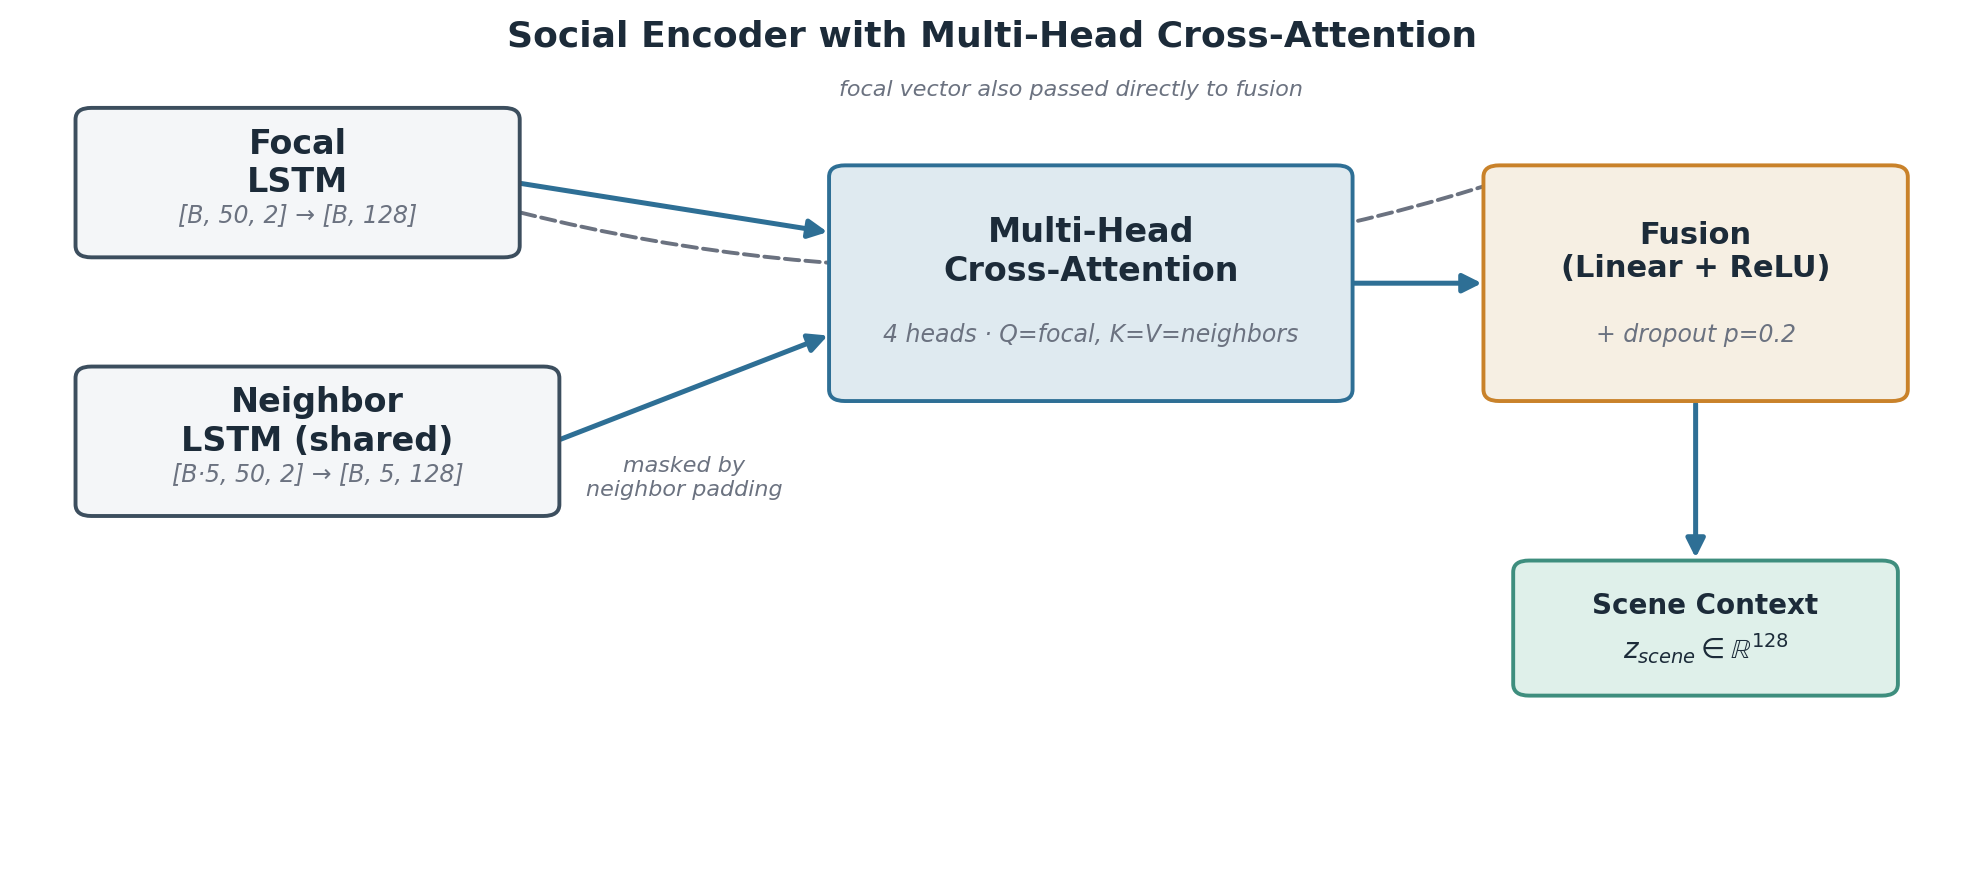

**Social encoder definition:** Defines `SocialEncoderMHA` (focal LSTM, shared neighbor LSTM, 4-head cross-attention and fusion layer). Its forward pass takes the focal history `(B, 50, 2)`, neighbor history `(B, 5, 50, 2)` and mask `(B, 5)`, and returns the scene context `(B, 128)`.

In [19]:
# =====================================================================
# SOCIAL INTERACTION POOLING ENCODER
# =====================================================================
class SocialEncoderMHA(nn.Module):
    """
    Social Encoding & Multi-Head Interaction Pooling Layer.
    Processes focal agents and variable surrounding neighbors using 
    batch folding and scaled dot-product cross-attention.
    """
    def __init__(self, input_dim: int = 2, hidden_dim: int = 128, num_heads: int = 4):
        super(SocialEncoderMHA, self).__init__()
        self.hidden_dim = hidden_dim
        
        # Dedicated Encoder for the Focal Agent
        self.focal_encoder = nn.LSTM(
            input_size=input_dim, hidden_size=hidden_dim, num_layers=1, batch_first=True
        )
        
        # Shared Weight Encoder for Neighboring Vehicles
        self.neighbor_encoder = nn.LSTM(
            input_size=input_dim, hidden_size=hidden_dim, num_layers=1, batch_first=True
        )
        
        # Multi-Head Cross-Attention Pooler
        self.cross_attention = nn.MultiheadAttention(
            embed_dim=hidden_dim, num_heads=num_heads, batch_first=True
        )
        
        # Final Scene Fusion Layer
        self.fusion_layer = nn.Sequential(
            nn.Linear(hidden_dim * 2, hidden_dim),
            nn.ReLU(),
            nn.Dropout(p=0.2)
        )

    def forward(self, focal_hist, neighbor_hist, neighbor_mask):
        batch_size = focal_hist.size(0)
        max_neighbors = neighbor_hist.size(1)
        
        # 1. Encode Focal Agent -> Output Shape: [B, hidden_dim]
        _, (h_focal, _) = self.focal_encoder(focal_hist)
        h_focal = h_focal.squeeze(0)
        
        # 2. Parallel Neighbor Encoding via Batch Folding -> Output Shape: [B, 5, hidden_dim]
        folded_neighbors = neighbor_hist.view(batch_size * max_neighbors, 50, 2)
        _, (h_nb_folded, _) = self.neighbor_encoder(folded_neighbors)
        h_neighbors = h_nb_folded.squeeze(0).view(batch_size, max_neighbors, self.hidden_dim)
        
        # 3. Cross-Attention Multi-Head Fusion Block
        # Invert dataset mask: PyTorch expects TRUE for elements that should be IGNORED.
        key_padding_mask = ~neighbor_mask 
        
        query = h_focal.unsqueeze(1) # Query: Focal Agent track -> [B, 1, hidden_dim]
        attn_output, _ = self.cross_attention(
            query=query, key=h_neighbors, value=h_neighbors, key_padding_mask=key_padding_mask
        )
        attn_output = attn_output.squeeze(1) # Output Shape: [B, hidden_dim]
        
        # 4. Context Synthesis -> Output Shape: [B, hidden_dim]
        combined = torch.cat([h_focal, attn_output], dim=-1)
        fused_context = self.fusion_layer(combined)
        
        return fused_context

**Dataset and encoder integrity check:** Before the decoder is added, this cell draws one batch of 128 scenarios from `Social_LSTM_output/server_train_11s_multi_agent_coords.npy` and passes it through an untrained `SocialEncoderMHA` on `device`. It confirms the expected `(128, 128)` context shape and prints a success message. The variables `loader` and `batch` are reused in Section 3.3.5.

In [20]:
# =====================================================================
# CONSOLIDATED PIPELINE INTEGRITY CHECK
# =====================================================================
if __name__ == "__main__":
    target_file = "Social_LSTM_output/server_train_11s_multi_agent_coords.npy"
    
    print("Executing pipeline integrity validation routine...")
    dataset = ArgoverseSocialDataset(npy_file=target_file, max_neighbors=5)
    loader = DataLoader(dataset, batch_size=128, shuffle=True, num_workers=2, pin_memory=True)
    
    # Extract structural verification batch sample
    batch = next(iter(loader))
    
    # Push test samples to active compute target
    f_hist = batch['focal_history'].to(device)
    n_hist = batch['neighbor_history'].to(device)
    n_mask = batch['neighbor_mask'].to(device)
    
    # Initialize encoder block instance
    encoder = SocialEncoderMHA(input_dim=2, hidden_dim=128, num_heads=4).to(device)
    encoder.eval()
    
    with torch.no_grad():
        context_tensors = encoder(f_hist, n_hist, n_mask)
        
    print("\n" + "="*50)
    print("   CONSOLIDATED PIPELINE VERIFICATION REPORT   ")
    print("="*50)
    print(f"Data Loader Focal Track Shape   : {list(batch['focal_history'].shape)}")
    print(f"Data Loader Neighbor Track Shape: {list(batch['neighbor_history'].shape)}")
    print(f"Social Encoder Context Output   : {list(context_tensors.shape)} -> Target: [128, 128]")
    print("="*50)
    
    assert context_tensors.shape == (128, 128), " Architecture pipeline shape mismatch!"
    print("Components are successfully verified and integrated.")

Executing pipeline integrity validation routine...
 Streaming multi-agent trajectory matrices from disk: Social_LSTM_output/server_train_11s_multi_agent_coords.npy
 Social Matrix Loaded! Total Scenarios: 199908
 Layout Geometry Dimensions: (199908, 11, 110, 2) -> (Scenarios, Actors, Timesteps, XY)

   CONSOLIDATED PIPELINE VERIFICATION REPORT   
Data Loader Focal Track Shape   : [128, 50, 2]
Data Loader Neighbor Track Shape: [128, 5, 50, 2]
Social Encoder Context Output   : [128, 128] -> Target: [128, 128]
Components are successfully verified and integrated.


##### 3.3.3 Multimodal Autoregressive Decoder

To capture multiple intents, such as lane keeping, lane changes or turns, $\mathbf{z}_{\text{scene}}$ is expanded across $K = 6$ modes. For each mode, the decoder `LSTMCell` is initialized with $\mathbf{z}_{\text{scene}}$ and seeded with the last observed focal displacement. A learnable 128-dimensional mode embedding is concatenated to the input at every step so the modes diverge into distinct trajectories. A shared linear head predicts per-step displacements, and a separate two-layer confidence head outputs one logit per mode from $\mathbf{z}_{\text{scene}}$.

The diagram below shows this decoding process.

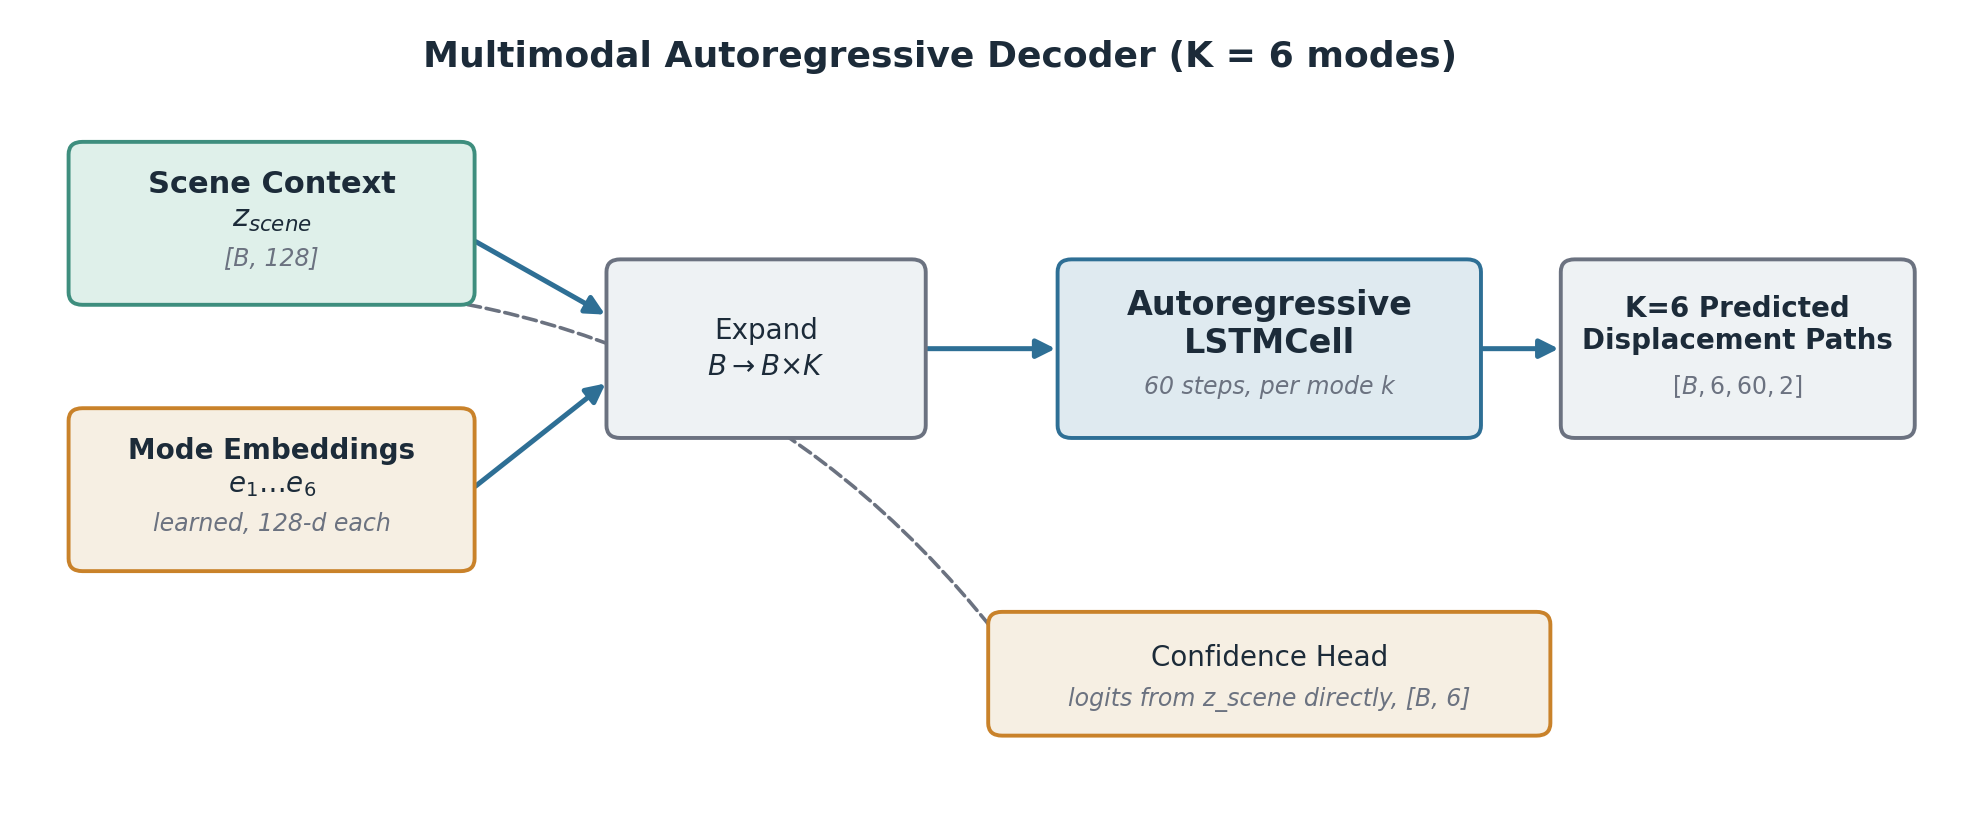

**Complete Social model definition:** Defines `SocialMultimodalTrajectoryPredictor`, which combines the social encoder, the mode-conditioned autoregressive decoder and the confidence head. Its forward pass takes the same three inputs as the social encoder and returns displacement trajectories `(B, 6, 60, 2)` and confidence logits `(B, 6)`.

In [21]:
# =====================================================================
# MULTIMODAL DECODER & COMPLETE MODEL
# =====================================================================
class SocialMultimodalTrajectoryPredictor(nn.Module):
    """
    Sprint 3: Complete Multimodal Social Trajectory Forecasting Model.
    Combines the Social MHA Encoder with a multi-mode autoregressive LSTMCell 
    decoder loop to output K independent future path options.
    """
    def __init__(self, input_dim: int = 2, hidden_dim: int = 128, num_heads: int = 4, num_modes: int = 6, prediction_steps: int = 60):
        super(SocialMultimodalTrajectoryPredictor, self).__init__()
        self.hidden_dim = hidden_dim
        self.num_modes = num_modes
        self.prediction_steps = prediction_steps
        
        # 1. Bring in the Sprint 2 Social Encoder Matrix
        self.encoder = SocialEncoderMHA(input_dim=input_dim, hidden_dim=hidden_dim, num_heads=num_heads)
        
        # 2. Mode Identifier Embedding layer (Ensures diverse path options)
        self.mode_embedding = nn.Embedding(num_modes, hidden_dim)
        
        # 3. Step-by-Step Autoregressive Recurrent Core
        # Input: previous step displacement (2) + Mode Specific Identity Context (128)
        self.decoder_cell = nn.LSTMCell(
            input_size=input_dim + hidden_dim,
            hidden_size=hidden_dim
        )
        
        # 4. Trajectory Regression Head (Outputs time step displacement dx, dy)
        self.regression_head = nn.Linear(hidden_dim, input_dim)
        
        # 5. Scene Confidence Classification Head
        self.confidence_head = nn.Sequential(
            nn.Linear(hidden_dim, hidden_dim),
            nn.ReLU(),
            nn.Linear(hidden_dim, num_modes)
        )
        
        self.dropout = nn.Dropout(p=0.2)

    def forward(self, focal_hist, neighbor_hist, neighbor_mask):
        """
        Returns:
            pred_trajectories: [B, K, 60, 2] -> Relative coordinate displacements (dx, dy)
            confidence_scores: [B, K]       -> Raw unnormalized logits for the 6 modes
        """
        batch_size = focal_hist.size(0)
        
        # ---- Step 1: Extract Fused Scene Context Vector ----
        # scene_context shape: [B, hidden_dim]
        scene_context = self.encoder(focal_hist, neighbor_hist, neighbor_mask)
        
        # ---- Step 2: Compute Mode Selection Confidences ----
        # confidence_scores shape: [B, K]
        confidence_scores = self.confidence_head(scene_context)
        
        # ---- Step 3: Expand Hidden States across all K Modes ----
        # Duplicate scene vectors to process all K choices in a single flat batch pass
        # [B, hidden_dim] -> [B, 1, hidden_dim] -> [B, K, hidden_dim] -> [B * K, hidden_dim]
        h_dec = scene_context.unsqueeze(1).repeat(1, self.num_modes, 1).view(batch_size * self.num_modes, self.hidden_dim)
        c_dec = torch.zeros_like(h_dec) # Initialize cell state to zero matrix
        
        # Generate and apply mode identity embedding vectors
        mode_ids = torch.arange(self.num_modes, device=focal_hist.device).repeat(batch_size) # [B * K]
        mode_embs = self.mode_embedding(mode_ids) # [B * K, hidden_dim]
        
        # ---- Step 4: Autoregressive Decode Cycle Loop ----
        # Initialize initial step displacement input with the final historical step position
        # shape: [B * K, 2]
        current_input = focal_hist[:, -1, :].unsqueeze(1).repeat(1, self.num_modes, 1).view(batch_size * self.num_modes, 2)
        
        predictions = []
        
        for t in range(self.prediction_steps):
            # Apply dropout directly inside the active hidden loop state
            h_dec_reg = self.dropout(h_dec)
            
            # Combine current step coordinate with mode structural identity context
            cell_input = torch.cat([current_input, mode_embs], dim=-1) # [B * K, 2 + hidden_dim]
            
            # Step the LSTM tracking node forward
            h_dec, c_dec = self.decoder_cell(cell_input, (h_dec_reg, c_dec))
            
            # Extrapolate spatial position step vector displacement
            delta_pos = self.regression_head(h_dec) # [B * K, 2]
            predictions.append(delta_pos)
            
            # Feed current prediction directly back into the next recurrence loop step
            current_input = delta_pos
            
        # Stacks timesteps to clear tracking outputs: [60, B * K, 2] -> [B * K, 60, 2]
        predictions = torch.stack(predictions, dim=0).permute(1, 0, 2)
        
        # Unfold the dimensions to isolate individual mode vectors cleanly
        # [B * K, 60, 2] -> [B, K, 60, 2]
        pred_trajectories = predictions.view(batch_size, self.num_modes, self.prediction_steps, 2)
        
        return pred_trajectories, confidence_scores

##### 3.3.4 Winner-Take-All Variety Loss

Averaging the regression loss over all modes makes them collapse onto one averaged trajectory (*mode collapse*). Following the best-of-K variety loss of Social GAN [[13]](https://openaccess.thecvf.com/content_cvpr_2018/html/Gupta_Social_GAN_Socially_CVPR_2018_paper.html), training instead uses a **Winner-Take-All (WTA) loss**:

$$\mathcal{L}_{\text{total}} = \mathcal{L}_{\text{reg}}^{(k^{*})} + \beta \cdot \mathcal{L}_{\text{cls}}, \qquad \beta = 1.0$$

The winning mode $k^{*}$ is the one with the lowest time-averaged Smooth L1 displacement error. $\mathcal{L}_{\text{reg}}^{(k^{*})}$ is that mode's error, so regression gradients flow only through $k^{*}$. $\mathcal{L}_{\text{cls}}$ is the cross-entropy between the confidence logits and $k^{*}$.

The diagram below shows this loss computation.

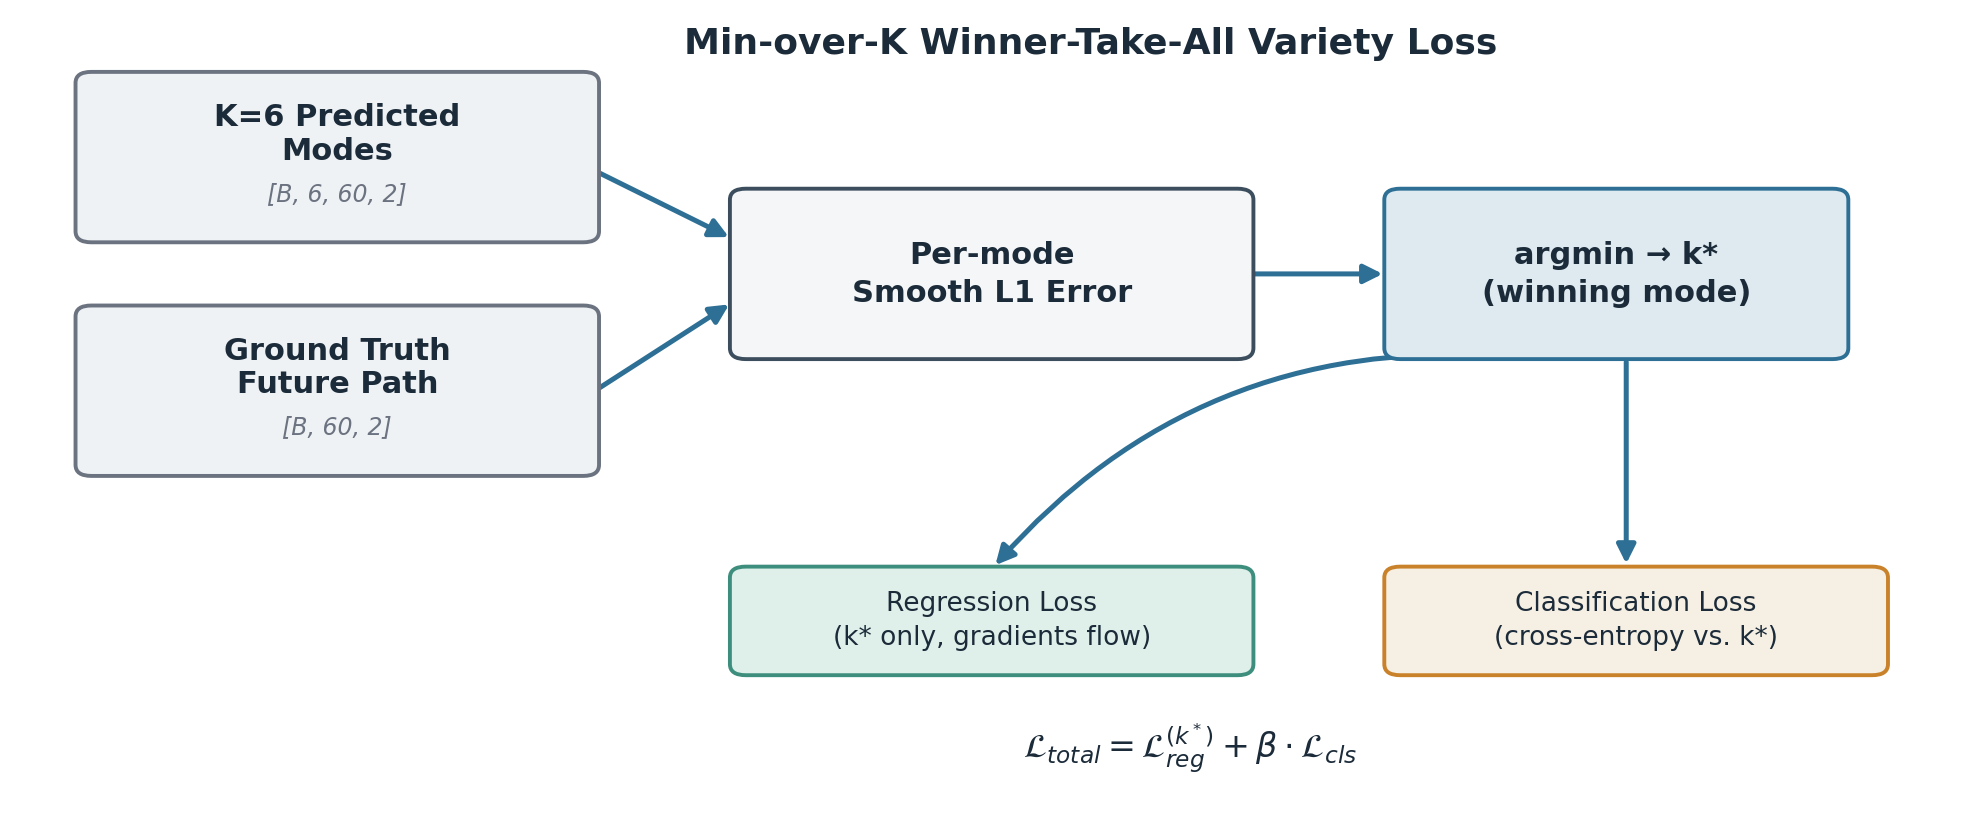

**Variety loss definition:** Defines `VarietyLoss`, which takes predicted trajectories `(B, 6, 60, 2)`, logits `(B, 6)` and ground truth `(B, 60, 2)`, and returns the total, winner-take-all regression and confidence cross-entropy losses.

In [22]:
# =====================================================================
# MULTIMODAL VARIETY LOSS ENGINE (WINNER-TAKE-ALL)
# =====================================================================
class VarietyLoss(nn.Module):
    """
    Min-over-K Winner-Take-All (WTA) Loss implementation.
    Backpropagates coordinate regression loss exclusively through the single 
    best-performing path option, while optimizing confidence selections.
    """
    def __init__(self, beta: float = 1.0):
        super(VarietyLoss, self).__init__()
        # Using SmoothL1 (Huber Loss) to match baseline regression parameters safely
        self.huber_loss = nn.SmoothL1Loss(reduction='none')
        self.cross_entropy = nn.CrossEntropyLoss()
        self.beta = beta # Weight balance coefficient for confidence optimization

    def forward(self, pred_trajectories, confidence_scores, true_trajectory):
        """
        Args:
            pred_trajectories: [B, K, 60, 2]
            confidence_scores: [B, K]
            true_trajectory:   [B, 60, 2]
        """
        batch_size = true_trajectory.size(0)
        num_modes = pred_trajectories.size(1)
        
        # Expand ground truth trajectory dimensions to align shapes for comparative evaluation
        # [B, 60, 2] -> [B, 1, 60, 2] -> [B, K, 60, 2]
        target_expanded = true_trajectory.unsqueeze(1).repeat(1, num_modes, 1, 1)
        
        # 1. Compute total spatial error metrics across all available path alternatives
        # huber_errors shape: [B, K, 60, 2] -> collapsed over steps/coords: [B, K]
        huber_errors = self.huber_loss(pred_trajectories, target_expanded)
        mean_errors_per_mode = huber_errors.mean(dim=(2, 3)) 
        
        # 2. Isolate the single closest prediction profile path index (The Winner)
        # winner_indices shape: [B]
        best_mode_errors, winner_indices = torch.min(mean_errors_per_mode, dim=1)
        
        # 3. Extract the clean regression loss exclusively from the winning indices
        regression_loss = best_mode_errors.mean()
        
        # 4. Calculate Cross Entropy optimization scores for classification matching
        classification_loss = self.cross_entropy(confidence_scores, winner_indices)
        
        # 5. Synthesize total loss using our weight balancing coefficient
        total_loss = regression_loss + self.beta * classification_loss
        
        return total_loss, regression_loss, classification_loss

##### 3.3.5 Training Procedure

- **Optimizer:** Adam, $\eta = 10^{-3}$, weight decay $10^{-4}$, batch size 128.
- **Gradient clipping:** global norm 5.0.
- **Scheduler:** `ReduceLROnPlateau` on validation loss (factor 0.5, patience 2).
- **Checkpointing:** up to 35 epochs. The checkpoint with the lowest validation regression loss is kept, with early stopping after 5 epochs without improvement. The best checkpoint was at epoch 30 (loss 0.0044).

The following cells check the forward and loss pass, then define and run training.

**Full model and loss integrity check:** Before full training, this cell passes `batch` from the encoder check through an untrained `SocialMultimodalTrajectoryPredictor` on `device` and evaluates `VarietyLoss`. It confirms output shapes `(128, 6, 60, 2)` and `(128, 6)`, prints the three loss values and checks that they are finite.

In [23]:
# =====================================================================
# FULL ARCHITECTURE INTEGRITY AND FUSION CHECK
# =====================================================================
if __name__ == "__main__":
    print("Initializing complete Multimodal Architecture validation routine...")
    
    # 1. Setup complete neural model instance on active device
    model = SocialMultimodalTrajectoryPredictor(
        input_dim=2, hidden_dim=128, num_heads=4, num_modes=6, prediction_steps=60
    ).to(device)
    
    # 2. Setup Variety Loss core
    criterion = VarietyLoss(beta=1.0)
    
    # 3. Pull verification tensors from the active dataset batch instance
    f_hist = batch['focal_history'].to(device)   # [128, 50, 2]
    n_hist = batch['neighbor_history'].to(device) # [128, 5, 50, 2]
    n_mask = batch['neighbor_mask'].to(device)    # [128, 5]
    f_fut  = batch['focal_future'].to(device)     # [128, 60, 2]
    
    model.eval()
    with torch.no_grad():
        # Execute absolute forward pass
        trajectories, confidences = model(f_hist, n_hist, n_mask)
        
        # Execute absolute loss parsing pass
        total_loss, reg_loss, cls_loss = criterion(trajectories, confidences, f_fut)
        
    print("\n" + "="*55)
    print("      FINAL MULTIMODAL PIPELINE VERIFICATION REPORT      ")
    print("="*55)
    print(f"Predicted Trajectories Matrix Shape: {list(trajectories.shape)} -> Target: [128, 6, 60, 2]")
    print(f"Confidence Evaluation Score Shape  : {list(confidences.shape)} -> Target: [128, 6]")
    print(f"Parsed Total Combined Batch Loss   : {total_loss.item():.4f}")
    print(f"Parsed Pure Path Regression Loss   : {reg_loss.item():.4f}")
    print(f"Parsed Pure Path Classification Loss: {cls_loss.item():.4f}")
    print("="*55)
    
    assert trajectories.shape == (128, 6, 60, 2), " Multimodal generation dimensions broken!"
    assert confidences.shape == (128, 6), " Classification prediction head shape mismatch!"
    print("Complete model is structurally verified and ready for deployment.")

Initializing complete Multimodal Architecture validation routine...

      FINAL MULTIMODAL PIPELINE VERIFICATION REPORT      
Predicted Trajectories Matrix Shape: [128, 6, 60, 2] -> Target: [128, 6, 60, 2]
Confidence Evaluation Score Shape  : [128, 6] -> Target: [128, 6]
Parsed Total Combined Batch Loss   : 1.8878
Parsed Pure Path Regression Loss   : 0.0976
Parsed Pure Path Classification Loss: 1.7903
Complete model is structurally verified and ready for deployment.


**Social training and validation routines:** Defines `train_one_epoch` (with gradient clipping) and `validate_epoch` for the three-input Social model.

In [24]:
# =====================================================================
# MULTIMODAL SOCIAL TRAINING LOOP IMPLEMENTATION
# =====================================================================
import time

def train_one_epoch(model, dataloader, optimizer, criterion, device, clip_value=5.0):
    model.train()
    total_epoch_loss = 0.0
    total_reg_loss = 0.0
    total_cls_loss = 0.0
    
    for batch_idx, batch in enumerate(dataloader):
        # 1. Move multi-agent structural tensors to active server GPU
        f_hist = batch['focal_history'].to(device)   # [B, 50, 2]
        n_hist = batch['neighbor_history'].to(device) # [B, 5, 50, 2]
        n_mask = batch['neighbor_mask'].to(device)    # [B, 5]
        f_fut  = batch['focal_future'].to(device)     # [B, 60, 2]
        
        optimizer.zero_grad()
        
        # 2. Forward execution pass -> Outputs K paths and raw logit scores
        pred_paths, conf_scores = model(f_hist, n_hist, n_mask)
        
        # 3. Calculate Winner-Take-All (WTA) variety metrics
        loss, reg_loss, cls_loss = criterion(pred_paths, conf_scores, f_fut)
        
        # 4. Backward propagation and gradient clipping safeguard
        loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=clip_value)
        optimizer.step()
        
        # 5. Accumulate telemetry metrics
        total_epoch_loss += loss.item()
        total_reg_loss += reg_loss.item()
        total_cls_loss += cls_loss.item()
        
    num_batches = len(dataloader)
    return total_epoch_loss / num_batches, total_reg_loss / num_batches, total_cls_loss / num_batches


def validate_epoch(model, dataloader, criterion, device):
    model.eval()
    total_epoch_loss = 0.0
    total_reg_loss = 0.0
    total_cls_loss = 0.0
    
    with torch.no_grad():
        for batch in dataloader:
            f_hist = batch['focal_history'].to(device)
            n_hist = batch['neighbor_history'].to(device)
            n_mask = batch['neighbor_mask'].to(device)
            f_fut  = batch['focal_future'].to(device)
            
            pred_paths, conf_scores = model(f_hist, n_hist, n_mask)
            loss, reg_loss, cls_loss = criterion(pred_paths, conf_scores, f_fut)
            
            total_epoch_loss += loss.item()
            total_reg_loss += reg_loss.item()
            total_cls_loss += cls_loss.item()
            
    num_batches = len(dataloader)
    return total_epoch_loss / num_batches, total_reg_loss / num_batches, total_cls_loss / num_batches

**Demonstration mode:** By default (`DEMO_MODE = True`), the cell below trains for 2 epochs on the sample files from Section 3.3.1 and saves `multimodal_social_lstm_demo.pt`. `DEMO_MODE = False` runs the full training of Section 3.3.5 and saves `multimodal_social_lstm_V2.pt` in the working directory.

**Social MHA training run:** Builds the training and validation DataLoaders for the selected mode and trains `SocialMultimodalTrajectoryPredictor` with `VarietyLoss`, learning-rate scheduling and early stopping. It prints a per-epoch loss table and saves the best checkpoint in the working directory.

In [27]:
# =====================================================================
# PIPELINE EXECUTION CORE & HYPERPARAMETER TUNING (WITH EARLY STOPPING)
# =====================================================================
if __name__ == "__main__":
    # --- 0. Execution Mode ---
    #   DEMO_MODE = True  -> quick check on the 100-scenario sample files, 2 epochs
    #   DEMO_MODE = False -> full training on the complete server files, 35 epochs
    DEMO_MODE = True

    # --- 1. Hyperparameters Allocation ---
    BATCH_SIZE = 32 if DEMO_MODE else 128
    EPOCHS = 2 if DEMO_MODE else 35
    LEARNING_RATE = 1e-3   # Smoother convergence
    NUM_MODES = 6
    MAX_NEIGHBORS = 5
    BETA_WEIGHT = 1        # Rebalanced loss weight
    PATIENCE = 5           # Early-stopping patience (epochs without v_reg improvement)
    NUM_WORKERS = 0 if DEMO_MODE else 4

    if DEMO_MODE:
        # 100-scenario samples written by the social preprocessing cell above
        TRAIN_FILE = "sample_server_train_11s_multi_agent_coords.npy"
        VAL_FILE   = "sample_server_val_11s_multi_agent_coords.npy"
        SAVE_PATH  = "multimodal_social_lstm_demo.pt"   # never overwrites the trained weights
    else:
        TRAIN_FILE = "Social_LSTM_output/server_train_11s_multi_agent_coords.npy"
        VAL_FILE   = "Social_LSTM_output/server_val_11s_multi_agent_coords.npy"
        SAVE_PATH  = "multimodal_social_lstm_V2.pt"

    # --- 2. Dataloader Initializations ---
    print(f"Mode: {'DEMO' if DEMO_MODE else 'FULL'} | Initializing Multi-Agent Social Datasets...")
    train_dataset = ArgoverseSocialDataset(TRAIN_FILE, max_neighbors=MAX_NEIGHBORS)
    val_dataset   = ArgoverseSocialDataset(VAL_FILE, max_neighbors=MAX_NEIGHBORS)

    social_train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True,
                                     num_workers=NUM_WORKERS, pin_memory=True)
    social_val_loader   = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False,
                                     num_workers=NUM_WORKERS, pin_memory=True)

    # --- 3. Model & Optimization Setup ---
    model = SocialMultimodalTrajectoryPredictor(
        input_dim=2, hidden_dim=128, num_heads=4, num_modes=NUM_MODES, prediction_steps=60
    ).to(device)

    optimizer = torch.optim.Adam(model.parameters(), lr=LEARNING_RATE, weight_decay=1e-4)
    criterion = VarietyLoss(beta=BETA_WEIGHT)

    # Scheduler tracking validation loss
    scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
        optimizer, mode='min', factor=0.5, patience=2
    )

    best_val_loss = float('inf')
    patience_counter = 0  # Counter for Early Stopping

    # --- 4. Main Training Orchestration Loop ---
    device_name = torch.cuda.get_device_name(0) if torch.cuda.is_available() else "CPU"
    print(f"\n Launching Multimodal Social Training Core on {device} ({device_name})...")
    print(f" {len(train_dataset)} train / {len(val_dataset)} val scenarios, up to {EPOCHS} epochs")
    print("="*90)
    print(f"{'Epoch':<6} | {'Train Loss':<10} | {'Train Reg':<10} | {'Train Cls':<10} | {'Val Loss':<10} | {'Val Reg':<10} | {'Time (s)':<8}")
    print("="*90)

    for epoch in range(1, EPOCHS + 1):
        start_time = time.time()

        # Run training & validation passes
        t_loss, t_reg, t_cls = train_one_epoch(model, social_train_loader, optimizer, criterion, device)
        v_loss, v_reg, v_cls = validate_epoch(model, social_val_loader, criterion, device)

        # Step LR scheduler
        scheduler.step(v_loss)

        epoch_time = time.time() - start_time
        print(f"{epoch:<6} | {t_loss:<10.4f} | {t_reg:<10.4f} | {t_cls:<10.4f} | {v_loss:<10.4f} | {v_reg:<10.4f} | {epoch_time:<8.1f}")

        # --- 5. Checkpoint & Early Stopping Logic ---
        # Track Validation Regression Loss (v_reg) instead of Total Val Loss (v_loss)
        if v_reg < best_val_loss:
            best_val_loss = v_reg
            patience_counter = 0  # Reset counter when spatial accuracy improves

            checkpoint = {
                'epoch': epoch,
                'model_state_dict': model.state_dict(),
                'optimizer_state_dict': optimizer.state_dict(),
                'best_val_loss': best_val_loss
            }
            torch.save(checkpoint, SAVE_PATH)
            print(f"   --->  Checkpoint saved at Epoch {epoch} (Val Reg: {v_reg:.4f})")
        else:
            patience_counter += 1
            print(f"   ---> No spatial improvement for {patience_counter}/{PATIENCE} epochs.")

            if patience_counter >= PATIENCE:
                print("\n" + "="*90)
                print(f" EARLY STOPPING TRIGGERED AT EPOCH {epoch}!")
                print(f"Optimal model preserved with Best Val Reg: {best_val_loss:.4f}")
                print("="*90)
                break

    print(f"\n TRAINING CONCLUDED, Model saved as '{SAVE_PATH}'")

Mode: DEMO | Initializing Multi-Agent Social Datasets...
 Streaming multi-agent trajectory matrices from disk: sample_server_train_11s_multi_agent_coords.npy
 Social Matrix Loaded! Total Scenarios: 100
 Layout Geometry Dimensions: (100, 11, 110, 2) -> (Scenarios, Actors, Timesteps, XY)
 Streaming multi-agent trajectory matrices from disk: sample_server_val_11s_multi_agent_coords.npy
 Social Matrix Loaded! Total Scenarios: 100
 Layout Geometry Dimensions: (100, 11, 110, 2) -> (Scenarios, Actors, Timesteps, XY)

 Launching Multimodal Social Training Core on cuda (NVIDIA A40)...
 100 train / 100 val scenarios, up to 2 epochs
Epoch  | Train Loss | Train Reg  | Train Cls  | Val Loss   | Val Reg    | Time (s)
1      | 1.8595     | 0.0672     | 1.7923     | 1.8377     | 0.0513     | 0.2     
   --->  Checkpoint saved at Epoch 1 (Val Reg: 0.0513)
2      | 1.8067     | 0.0456     | 1.7611     | 1.8157     | 0.0504     | 0.2     
   --->  Checkpoint saved at Epoch 2 (Val Reg: 0.0504)

 TRAINING 

##### 3.3.6 Evaluation Protocol II: Multimodal Metrics

Since the model outputs K trajectories, the metrics of Section 3.1.3 are replaced by their best-of-K versions from the Argoverse 2 benchmark [[1]](https://arxiv.org/abs/2301.00493): minADE, minFDE and MR are computed on the mode closest to the ground truth.

Results are in Section 5.1.3. Social attention with multimodal output substantially reduces error over the single-agent baseline, but the model still ignores road geometry. The next section adds map awareness.

#### 3.4 Map-Aware Social Multimodal Forecasting

This stage adds a vectorized HD map, in the form of lane centerline polylines, to the Social MHA model of Section 3.3. Fusing road topology with the multi-agent context steers predictions toward the drivable lane structure. The model again outputs K = 6 trajectories with confidence scores. This also allows a single confidence-ranked prediction to be evaluated for deployment (Section 3.4.5).

##### 3.4.1 Vector Map Representation and Scene Preprocessing

Each scenario is converted into three focal-centric inputs: the focal agent, its neighbors and the lane geometry.

- **Coordinate frame:** all coordinates are expressed relative to the focal agent's position at frame 49 (t = 5 s). Unlike Section 3.3.1, this is done once during preprocessing.
- **Lane sampling:** lane centerlines from the map file are ranked by their minimum distance to three points on the focal track (frames 0, 49 and 109). The $L_{max} = 16$ nearest lanes are kept and resampled to $P = 10$ points each. Empty slots are zero-padded and flagged by a mask $M_{\text{lane}} \in \{0,1\}^{B \times 16}$.
- **Neighbor selection:** up to 10 background actors with at least 5 observations are aligned to the scenario's timestep grid, with gaps filled by the nearest observed position. They are ranked by mean distance to the focal agent over the 50-step history, and the reported model uses all 10. Missing actors are zero-padded and flagged by a mask $M_{\text{neighbor}}$.
- **Input encoding:** as in Section 3.3.1, the focal trajectory is encoded as displacements, while neighbor histories and lane points stay as focal-centric positions.

**Map-aware preprocessing (parallel, demo mode):** Using a pool of worker processes, extracts the focal agent, up to 10 time-aligned neighbors and the 16 nearest lane centerlines from `Datasets/{train,val,test}`, where each scenario folder holds a `.parquet` file and a map `.json` file. It saves `sample_av2_{train,val,test}_map_aware.npy` (100 scenarios each), where each entry is a dictionary with `scenario_id`, `trajectory_matrix` `(11, 110, 2)`, `lane_tensor` `(16, 10, 2)` and `lane_mask` `(16,)`. The full-scale call that produced `Map_aware_output/` is kept as a comment.

In [28]:
import os
import glob
import json
import time
import numpy as np
import pandas as pd
from concurrent.futures import ProcessPoolExecutor, as_completed

# ==============================================================================
# 1. MAP EXTRACTION HELPER (LOCAL COORDINATES)
# ==============================================================================
def extract_trajectory_centric_lanes(map_json_path, trajectory, origin_anchor, max_lanes=16, points_per_lane=10):
    lane_tensor = np.zeros((max_lanes, points_per_lane, 2), dtype=np.float32)
    lane_mask = np.zeros((max_lanes,), dtype=np.bool_)
    
    if not os.path.exists(map_json_path):
        return lane_tensor, lane_mask

    try:
        with open(map_json_path, 'r') as f:
            map_data = json.load(f)
            
        raw_lanes = []
        lane_segments = map_data.get('lane_segments', {})
        
        for lane_id, lane_info in lane_segments.items():
            pts_list = lane_info.get('centerline', [])
            if len(pts_list) >= 2:
                coords = [[pt['x'], pt['y']] if isinstance(pt, dict) else pt[:2] for pt in pts_list]
                if len(coords) >= 2:
                    raw_lanes.append(np.array(coords, dtype=np.float32))

        if not raw_lanes:
            return lane_tensor, lane_mask

        query_points = [trajectory[0], trajectory[min(49, len(trajectory)-1)], trajectory[-1]]
        lane_distances = []
        
        for idx, lane in enumerate(raw_lanes):
            min_dist = min(np.min(np.linalg.norm(lane - q, axis=1)) for q in query_points)
            lane_distances.append((idx, min_dist))
            
        lane_distances.sort(key=lambda x: x[1])
        selected_lane_indices = [idx for idx, _ in lane_distances[:max_lanes]]
        
        for i, idx in enumerate(selected_lane_indices):
            lane_coords = raw_lanes[idx]
            
            if len(lane_coords) != points_per_lane:
                alphas = np.linspace(0, 1, points_per_lane)
                orig_alphas = np.linspace(0, 1, len(lane_coords))
                ix = np.interp(alphas, orig_alphas, lane_coords[:, 0])
                iy = np.interp(alphas, orig_alphas, lane_coords[:, 1])
                lane_coords = np.stack([ix, iy], axis=1)
            
            lane_tensor[i] = lane_coords - origin_anchor
            lane_mask[i] = True
            
    except Exception:
        pass
        
    return lane_tensor, lane_mask


# ==============================================================================
# 2. SINGLE SCENARIO WORKER (EXECUTED IN PARALLEL)
# ==============================================================================
def process_single_scenario(folder, max_actors_per_scene=11, history_steps=50, future_steps=60):
    target_len = history_steps + future_steps
    parquet_files = glob.glob(os.path.join(folder, "*.parquet"))
    map_files = glob.glob(os.path.join(folder, "*.json"))
    
    if not parquet_files:
        return None

    try:
        df = pd.read_parquet(parquet_files[0])
        category_col = next((c for c in ['category', 'object_type', 'track_category'] if c in df.columns), None)
        
        focal_df = pd.DataFrame()
        if category_col is not None:
            focal_df = df[df[category_col].astype(str).str.contains('focal_agent|focal', case=False, na=False)]
        
        if len(focal_df) == 0 and 'track_id' in df.columns:
            focal_df = df[df['track_id'] == df['track_id'].value_counts().idxmax()]
        
        if len(focal_df) == 0:
            return None
            
        time_col = 'timestep' if 'timestep' in df.columns else 'timestamp'
        focal_df = focal_df.sort_values(by=time_col).reset_index(drop=True)
        focal_id = focal_df['track_id'].iloc[0] if 'track_id' in focal_df.columns else None
        
        focal_coords = focal_df[['position_x', 'position_y']].values
        
        if len(focal_coords) < target_len:
            focal_coords = np.vstack([focal_coords, np.tile(focal_coords[-1], (target_len - len(focal_coords), 1))])
        else:
            focal_coords = focal_coords[:target_len]
            
        anchor_idx = min(49, len(focal_coords) - 1)
        origin_anchor = focal_coords[anchor_idx, :].copy() 

        map_json_path = map_files[0] if map_files else ""
        lane_tensor, lane_mask = extract_trajectory_centric_lanes(
            map_json_path, 
            trajectory=focal_coords, 
            origin_anchor=origin_anchor, 
            max_lanes=16, 
            points_per_lane=10
        )

        scene_matrix = np.zeros((max_actors_per_scene, target_len, 2), dtype=np.float32)
        scene_matrix[0] = focal_coords - origin_anchor
        
        if 'track_id' in df.columns and focal_id is not None:
            neighbor_dfs = df[df['track_id'] != focal_id]
            unique_neighbors = neighbor_dfs['track_id'].unique()
            
            neighbor_candidates = []
            focal_history = focal_coords[:history_steps]
            
            for n_id in unique_neighbors:
                n_df = neighbor_dfs[neighbor_dfs['track_id'] == n_id].sort_values(by=time_col)
                n_coords = n_df[['position_x', 'position_y']].values
                
                if len(n_coords) < 5: 
                    continue
                
                if time_col in n_df.columns:
                    t_indices = n_df[time_col].values.astype(int)
                    if t_indices[0] > 0 and np.max(t_indices) >= target_len:
                        t_indices = t_indices - t_indices[0]
                else:
                    t_indices = np.arange(len(n_coords))
                    
                full_n_coords = np.zeros((target_len, 2), dtype=np.float32)
                valid_t = t_indices[t_indices < target_len]
                valid_c = n_coords[:len(valid_t)]
                
                if len(valid_t) > 0:
                    full_n_coords[valid_t] = valid_c
                    
                    min_t = np.min(valid_t)
                    if min_t > 0:
                        full_n_coords[:min_t] = valid_c[0]
                        
                    max_t = np.max(valid_t)
                    if max_t < target_len - 1:
                        full_n_coords[max_t + 1:] = valid_c[-1]
                else:
                    continue

                neighbor_history = full_n_coords[:history_steps]
                avg_past_dist = np.mean(np.linalg.norm(neighbor_history - focal_history, axis=1))

                neighbor_candidates.append((avg_past_dist, full_n_coords))
            
            neighbor_candidates.sort(key=lambda x: x[0])
            
            for actor_idx in range(1, max_actors_per_scene):
                cand_idx = actor_idx - 1
                if cand_idx < len(neighbor_candidates):
                    dist, n_coords = neighbor_candidates[cand_idx]
                    scene_matrix[actor_idx] = n_coords - origin_anchor
                else:
                    scene_matrix[actor_idx] = 0.0
        
        scenario_id = os.path.basename(folder)
        
        return {
            "scenario_id": scenario_id,
            "trajectory_matrix": scene_matrix,
            "lane_tensor": lane_tensor,
            "lane_mask": lane_mask
        }
    except Exception:
        return None


# ==============================================================================
# 3. PARALLEL PIPELINE EXECUTOR
# ==============================================================================
def preprocess_av2_parallel(source_dir, output_filename, log_step=5000, num_workers=None, max_files=100):
    start_time = time.time()
    print(f"\n Starting PARALLEL extraction for: {source_dir}")
    
    scenario_folders = glob.glob(os.path.join(source_dir, "*"))
    scenario_folders = [f for f in scenario_folders if os.path.isdir(f)]
    
    # Limit to a sample of scenarios (max_files=None processes everything)
    if max_files is not None:
        scenario_folders = scenario_folders[:max_files]
    
    total_folders = len(scenario_folders)
    
    if num_workers is None:
        num_workers = min(os.cpu_count() or 4, 16)
        
    print(f" Total scenarios: {total_folders} |  Using {num_workers} CPU workers")

    all_scenes_data = []
    processed_count = 0
    valid_map_count = 0

    # Dispatch tasks across available CPU cores
    with ProcessPoolExecutor(max_workers=num_workers) as executor:
        futures = {executor.submit(process_single_scenario, folder): folder for folder in scenario_folders}
        
        for future in as_completed(futures):
            res = future.result()
            processed_count += 1
            
            if res is not None:
                all_scenes_data.append(res)
                if np.any(res["lane_mask"]):
                    valid_map_count += 1
                    
            if processed_count % log_step == 0 or processed_count == total_folders:
                elapsed = time.time() - start_time
                scenarios_per_sec = processed_count / elapsed if elapsed > 0 else 0
                print(f"  [Progress] {processed_count}/{total_folders} processed ({valid_map_count} valid maps) [{elapsed:.1f}s | {scenarios_per_sec:.1f} scn/s]")

    if all_scenes_data:
        np.save(output_filename, np.array(all_scenes_data, dtype=object))
        elapsed = time.time() - start_time
        print(f"Saved {len(all_scenes_data)} scenarios to '{output_filename}' in {elapsed/60:.2f} mins.\n")
    else:
        print(f"Error: No valid data extracted from {source_dir}\n")


# ==============================================================================
# 4. EXECUTION
# ==============================================================================
def find_local_datasets():
    current_dir = os.getcwd()
    while current_dir != os.path.dirname(current_dir):
        potential_datasets = os.path.join(current_dir, "Datasets")
        if os.path.exists(potential_datasets):
            return potential_datasets
        current_dir = os.path.dirname(current_dir)
    return None

datasets_root = find_local_datasets()

if datasets_root is not None:
    splits = [
        ("train", "sample_av2_train_map_aware.npy"),
        ("val", "sample_av2_val_map_aware.npy"),
        ("test", "sample_av2_test_map_aware.npy")
    ]
    
    for folder_name, out_filename in splits:
        split_path = os.path.join(datasets_root, folder_name)
        if os.path.exists(split_path):
            # Automatically detects your CPU count
            # preprocess_av2_parallel(source_dir=split_path, output_filename=out_filename, log_step=5000, max_files=None)  # Full-scale run (all scenarios per split) was executed on the server; kept here for reference
            preprocess_av2_parallel(source_dir=split_path, output_filename=out_filename, log_step=5000, max_files=100)  # Demo run: extracts only 100 scenarios per split so the workflow runs end-to-end
        else:
            print(f"Split directory '{folder_name}' not found at: {split_path}")
else:
    print(" Could not locate the 'Datasets' root folder.")

# ======================================================================


 Starting PARALLEL extraction for: /home/jovyan/acdc/topics/16-Motion-Forecasting/report_2/Datasets/train
 Total scenarios: 100 |  Using 16 CPU workers
  [Progress] 100/100 processed (100 valid maps) [2.5s | 39.6 scn/s]
Saved 100 scenarios to 'sample_av2_train_map_aware.npy' in 0.04 mins.


 Starting PARALLEL extraction for: /home/jovyan/acdc/topics/16-Motion-Forecasting/report_2/Datasets/val
 Total scenarios: 100 |  Using 16 CPU workers
  [Progress] 100/100 processed (100 valid maps) [1.1s | 89.5 scn/s]
Saved 100 scenarios to 'sample_av2_val_map_aware.npy' in 0.02 mins.


 Starting PARALLEL extraction for: /home/jovyan/acdc/topics/16-Motion-Forecasting/report_2/Datasets/test
 Total scenarios: 100 |  Using 16 CPU workers
  [Progress] 100/100 processed (100 valid maps) [1.1s | 90.3 scn/s]
Saved 100 scenarios to 'sample_av2_test_map_aware.npy' in 0.02 mins.



**Map-aware dataset class:** Defines `MapAwareArgoverseSocialDataset`, which loads a map-aware `.npy` file with up to `max_neighbors` (≤ 10) neighbors, converts the focal trajectory to displacements and returns the neighbor and lane tensors with their masks. In addition to the Social inputs, each sample contains `map_lanes` `(16, 10, 2)`, `map_masks` `(16,)` and `scenario_id`. On instantiation it prints the dataset size and sample shapes.

In [29]:
# =====================================================================
# DATASET STORAGE ENGINE (Updated for Map-Aware Dicts)
# =====================================================================
import numpy as np
import torch
from torch.utils.data import Dataset


class MapAwareArgoverseSocialDataset(Dataset):
    """Advanced Multi-Agent & HD Map Data Pipeline for Argoverse Trajectory Prediction.

    Consumes pre-centered local trajectory matrices and pre-extracted HD map centerline features.
    """

    def __init__(self, npy_file: str, max_neighbors: int = 5):
        print(f" Streaming map-aware scenario dictionaries from disk: {npy_file}")
        # MUST use allow_pickle=True for dict containers
        self.raw_data = np.load(npy_file, allow_pickle=True)
        self.num_scenarios = len(self.raw_data)
        self.max_neighbors = min(max_neighbors, 10)  # Capped by extracted 10 neighbors

        print(f" Social & Map Matrix Loaded! Total Scenarios: {self.num_scenarios:,}")
        
        # Sample inspection check
        sample_traj = self.raw_data[0]["trajectory_matrix"]
        sample_lanes = self.raw_data[0]["lane_tensor"]
        print(f"Trajectory Matrix Shape: {sample_traj.shape} -> (Actors, Timesteps, XY)")
        print(f"HD Map Tensor Shape:     {sample_lanes.shape} -> (Lanes, Points, XY)")

    def __len__(self) -> int:
        return self.num_scenarios

    def __getitem__(self, idx: int) -> dict:
        item = self.raw_data[idx]

        # Extract pre-centered components
        # Index 0 = Focal Agent, Indices 1-10 = Pre-sorted Neighbors
        scene_matrix = item["trajectory_matrix"]  # Shape: (11, 110, 2)
        lane_tensor  = item["lane_tensor"]        # Shape: (16, 10, 2)
        lane_mask    = item["lane_mask"]          # Shape: (16,)

        # -------------------------------------------------------------
        # 1. Focal Agent Tracks (Local centered coordinates)
        # -------------------------------------------------------------
        focal_local = scene_matrix[0]
        focal_hist_local = focal_local[:50, :]
        focal_fut_local = focal_local[50:, :]

        # Calculate relative coordinate displacements (dx, dy)
        focal_hist_disp = np.zeros_like(focal_hist_local)
        focal_hist_disp[1:, :] = np.diff(focal_hist_local, axis=0)
        focal_hist_disp[0, :] = focal_hist_local[0, :]

        focal_fut_disp = np.zeros_like(focal_fut_local)
        focal_fut_disp[1:, :] = np.diff(focal_fut_local, axis=0)
        focal_fut_disp[0, :] = focal_fut_local[0, :] - focal_hist_local[-1, :]

        # -------------------------------------------------------------
        # 2. Background Actors (Pre-sorted by proximity in preprocessing)
        # -------------------------------------------------------------
        # Neighbors live at indices 1 to 10. Slice up to max_neighbors requested.
        neighbor_tracks = scene_matrix[1 : 1 + self.max_neighbors, :50, :] # Shape: (max_neighbors, 50, 2)

        # Neighbor Mask: check if track has non-zero movement/presence in history frame
        neighbor_mask = np.any(neighbor_tracks != 0.0, axis=(1, 2))  # Shape: (max_neighbors,)

        # -------------------------------------------------------------
        # 3. Return Tensor Payload
        # -------------------------------------------------------------
        return {
            "focal_history": torch.tensor(focal_hist_disp, dtype=torch.float32),
            "focal_future": torch.tensor(focal_fut_disp, dtype=torch.float32),
            "neighbor_history": torch.tensor(neighbor_tracks, dtype=torch.float32),
            "neighbor_mask": torch.tensor(neighbor_mask, dtype=torch.bool),
            # NEW HD Map Feature Tensors
            "map_lanes": torch.tensor(lane_tensor, dtype=torch.float32),   # Shape: (16, 10, 2)
            "map_masks": torch.tensor(lane_mask, dtype=torch.bool),        # Shape: (16,)
            "scenario_id": item["scenario_id"]
        }

##### 3.4.2 Hierarchical Map-Social Encoder

Separate pathways encode agent motion, social interaction and road geometry, which are then fused into one scene representation.

- **Focal and social encoding:** as in Section 3.3.2, focal and neighbor LSTMs are combined by cross-attention (masked by $M_{\text{neighbor}}$) into the social context $z_{\text{social}} \in \mathbb{R}^{B \times 128}$. The focal encoding $h_{\text{focal}}$ is also reused below.
- **Map encoder (`MapEncoder`):** a shared PointNet-style stack (two `Conv1d` + `BatchNorm1d` + `ReLU` blocks) with max-pooling over points compresses each 10-point lane into a 128-dimensional embedding, giving $H_{\text{lanes}} \in \mathbb{R}^{B \times 16 \times 128}$.
- **Map cross-attention:** a second attention block uses $h_{\text{focal}}$ as the query over $H_{\text{lanes}}$, masked by $M_{\text{lane}}$. It weights lanes by their relevance to the focal agent's motion and produces the map context $z_{\text{map}} \in \mathbb{R}^{B \times 128}$.
- **Scene fusion:** $z_{\text{social}}$ and $z_{\text{map}}$ are concatenated and projected (linear layer, ReLU, dropout $p = 0.2$) into $z_{\text{scene}} \in \mathbb{R}^{B \times 128}$, which combines focal dynamics, social context and map context.

The diagram below shows this architecture.

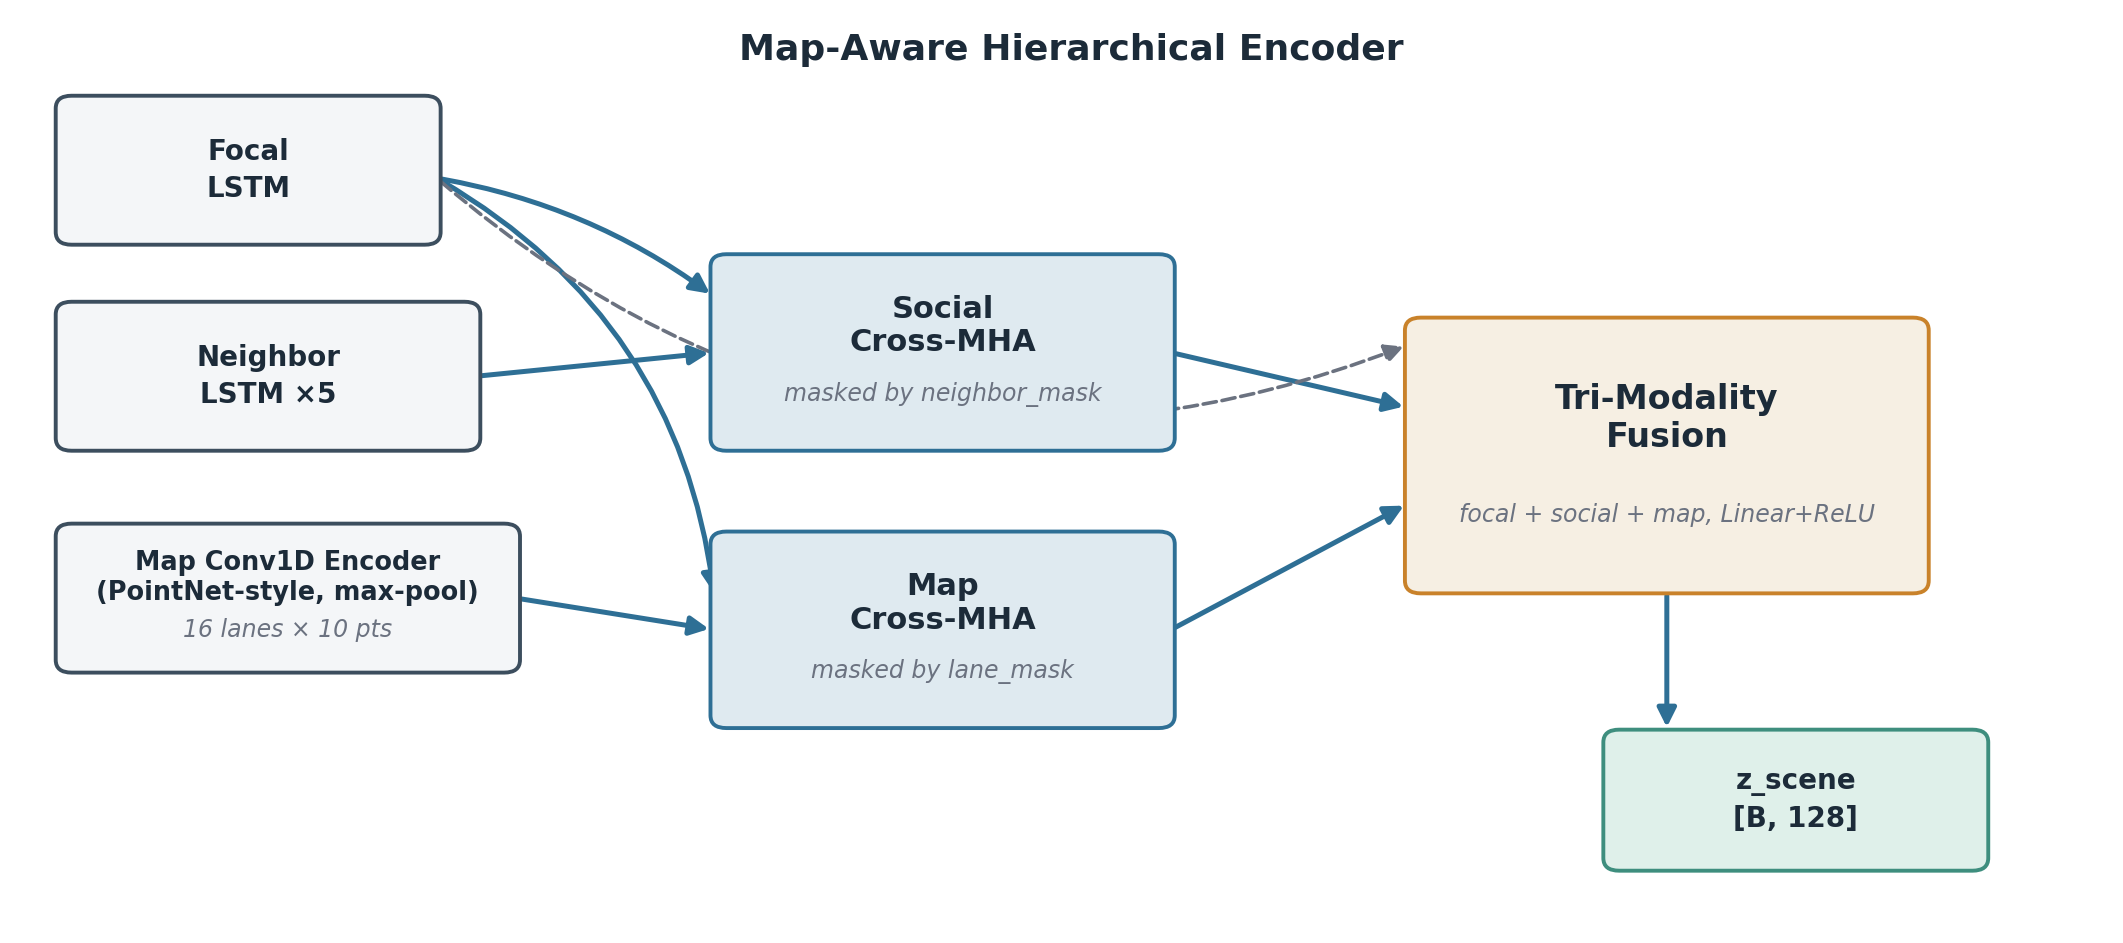

**Map encoder and map-aware social encoder definitions:** Defines `MapEncoder` (PointNet-style lane encoder with focal-to-lane cross-attention) and `MapAwareSocialEncoderMHA`, a social encoder that also returns $h_{\text{focal}}$ as the query for the map branch. Both return `(B, 128)` context vectors.

In [30]:
# =====================================================================
# SOCIAL & HD MAP INTERACTION POOLING ENCODER
# =====================================================================
import torch
import torch.nn as nn


class MapEncoder(nn.Module):
    """Encodes HD map centerline segments into spatial context embeddings using

    PointNet-style 1D Convolutions and Cross-Attention pooling.
    """

    def __init__(self, point_dim: int = 2, hidden_dim: int = 128, num_heads: int = 4):
        super(MapEncoder, self).__init__()
        self.hidden_dim = hidden_dim

        # 1. Sub-Graph Encoder for Lane Polyline Geometry (10 points per lane)
        # Input shape per point: [B * N_lanes, 2, 10] -> Output: [B * N_lanes, hidden_dim, 1]
        self.lane_conv = nn.Sequential(
            nn.Conv1d(
                in_channels=point_dim, out_channels=64, kernel_size=3, padding=1
            ),
            nn.BatchNorm1d(64),
            nn.ReLU(),
            nn.Conv1d(
                in_channels=64, out_channels=hidden_dim, kernel_size=3, padding=1
            ),
            nn.BatchNorm1d(hidden_dim),
            nn.ReLU(),
            nn.AdaptiveMaxPool1d(1),
        )

        # 2. Map-to-Focal Cross-Attention Pooling
        self.map_attention = nn.MultiheadAttention(
            embed_dim=hidden_dim, num_heads=num_heads, batch_first=True
        )

    def forward(self, focal_embedding, map_lanes, map_masks):
        """Args:

        focal_embedding: [B, hidden_dim] - Pre-encoded focal agent representation
        map_lanes:       [B, 16, 10, 2] - Lane centerline points
        map_masks:       [B, 16]        - Valid lane mask (True=valid,
        False=padding)
        """
        batch_size = map_lanes.size(0)
        num_lanes = map_lanes.size(1)

        # 1. Reshape & Fold Batch to process all polyline segments simultaneously
        # [B, 16, 10, 2] -> [B * 16, 2, 10]
        folded_lanes = (
            map_lanes.view(batch_size * num_lanes, 10, 2)
            .transpose(1, 2)
            .contiguous()
        )

        # 2. Process Lane Geometries -> [B * 16, hidden_dim]
        lane_feats = self.lane_conv(folded_lanes).squeeze(-1)
        lane_embeddings = lane_feats.view(batch_size, num_lanes, self.hidden_dim)

        # 3. Cross-Attention: Focal Agent queries Map features
        # PyTorch MultiheadAttention expects key_padding_mask=True for IGNORED slots
        key_padding_mask = ~map_masks

        query = focal_embedding.unsqueeze(1)  # [B, 1, hidden_dim]
        map_context, _ = self.map_attention(
            query=query,
            key=lane_embeddings,
            value=lane_embeddings,
            key_padding_mask=key_padding_mask,
        )
        map_context = map_context.squeeze(1)  # [B, hidden_dim]

        return map_context


class MapAwareSocialEncoderMHA(nn.Module):
    """Social Encoding & Multi-Head Interaction Pooling Layer.

    Processes focal agents and variable surrounding neighbors using batch folding
    and scaled dot-product cross-attention.
    """

    def __init__(
        self, input_dim: int = 2, hidden_dim: int = 128, num_heads: int = 4
    ):
        super(MapAwareSocialEncoderMHA, self).__init__()
        self.hidden_dim = hidden_dim

        # Dedicated Encoder for the Focal Agent
        self.focal_encoder = nn.LSTM(
            input_size=input_dim,
            hidden_size=hidden_dim,
            num_layers=1,
            batch_first=True,
        )

        # Shared Weight Encoder for Neighboring Vehicles
        self.neighbor_encoder = nn.LSTM(
            input_size=input_dim,
            hidden_size=hidden_dim,
            num_layers=1,
            batch_first=True,
        )

        # Multi-Head Cross-Attention Pooler
        self.cross_attention = nn.MultiheadAttention(
            embed_dim=hidden_dim, num_heads=num_heads, batch_first=True
        )

        # Final Scene Fusion Layer
        self.fusion_layer = nn.Sequential(
            nn.Linear(hidden_dim * 2, hidden_dim),
            nn.ReLU(),
            nn.Dropout(p=0.2),
        )

    def forward(self, focal_hist, neighbor_hist, neighbor_mask):
        batch_size = focal_hist.size(0)
        max_neighbors = neighbor_hist.size(1)

        # 1. Encode Focal Agent -> Output Shape: [B, hidden_dim]
        _, (h_focal, _) = self.focal_encoder(focal_hist)
        h_focal = h_focal.squeeze(0)

        # 2. Parallel Neighbor Encoding via Batch Folding -> Output Shape: [B, max_neighbors, hidden_dim]
        folded_neighbors = neighbor_hist.view(
            batch_size * max_neighbors, 50, 2
        )
        _, (h_nb_folded, _) = self.neighbor_encoder(folded_neighbors)
        h_neighbors = h_nb_folded.squeeze(0).view(
            batch_size, max_neighbors, self.hidden_dim
        )

        # 3. Cross-Attention Multi-Head Fusion Block
        # Invert dataset mask: PyTorch expects TRUE for elements that should be IGNORED.
        key_padding_mask = ~neighbor_mask

        query = h_focal.unsqueeze(
            1
        )  # Query: Focal Agent track -> [B, 1, hidden_dim]
        attn_output, _ = self.cross_attention(
            query=query,
            key=h_neighbors,
            value=h_neighbors,
            key_padding_mask=key_padding_mask,
        )
        attn_output = attn_output.squeeze(1)  # Output Shape: [B, hidden_dim]

        # 4. Context Synthesis -> Output Shape: [B, hidden_dim]
        combined = torch.cat([h_focal, attn_output], dim=-1)
        fused_context = self.fusion_layer(combined)

        return fused_context, h_focal

**Dataset and encoder integrity check (map and social):** Draws one batch from `Map_aware_output/av2_train_map_aware.npy` and passes it through untrained social and map encoders. It confirms that both produce the expected `(128, 128)` context shape and prints a success message. The variables `loader`, `batch`, `social_encoder` and `map_encoder` are reused in the next two cells.

In [31]:
# =====================================================================
# CONSOLIDATED PIPELINE INTEGRITY CHECK (Map & Social)
# =====================================================================
import torch
from torch.utils.data import DataLoader

if __name__ == "__main__":
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    target_file = "Map_aware_output/av2_train_map_aware.npy"

    print("Executing pipeline integrity validation routine...")
    dataset = MapAwareArgoverseSocialDataset(npy_file=target_file, max_neighbors=5)
    loader = DataLoader(
        dataset, batch_size=128, shuffle=True, num_workers=4, pin_memory=True
    )

    # Extract structural verification batch sample
    batch = next(iter(loader))

    # Push test samples to active compute target
    f_hist = batch["focal_history"].to(device)
    n_hist = batch["neighbor_history"].to(device)
    n_mask = batch["neighbor_mask"].to(device)
    m_lanes = batch["map_lanes"].to(device)
    m_masks = batch["map_masks"].to(device)

    # Initialize encoder block instances
    social_encoder = MapAwareSocialEncoderMHA(input_dim=2, hidden_dim=128, num_heads=4).to(
        device
    )
    map_encoder = MapEncoder(point_dim=2, hidden_dim=128, num_heads=4).to(device)

    social_encoder.eval()
    map_encoder.eval()

    with torch.no_grad():
        social_context, h_focal = social_encoder(f_hist, n_hist, n_mask)
        map_context = map_encoder(h_focal, m_lanes, m_masks)

    print("\n" + "=" * 60)
    print("      CONSOLIDATED PIPELINE VERIFICATION REPORT      ")
    print("=" * 60)
    print(
        f"Data Loader Focal Track Shape   : {list(batch['focal_history'].shape)}"
    )
    print(
        f"Data Loader Neighbor Track Shape: {list(batch['neighbor_history'].shape)}"
    )
    print(f"Data Loader Map Lanes Shape     : {list(batch['map_lanes'].shape)}")
    print(
        f"Social Encoder Context Output   : {list(social_context.shape)} -> Target: [128, 128]"
    )
    print(
        f"Map Encoder Context Output      : {list(map_context.shape)} -> Target: [128, 128]"
    )
    print("=" * 60)

    assert social_context.shape == (
        128,
        128,
    ), " Social Architecture shape mismatch!"
    assert map_context.shape == (
        128,
        128,
    ), " Map Architecture shape mismatch!"
    print(
        " Social and Map pipeline components are fully verified and integrated."
    )

Executing pipeline integrity validation routine...
 Streaming map-aware scenario dictionaries from disk: Map_aware_output/av2_train_map_aware.npy
 Social & Map Matrix Loaded! Total Scenarios: 199,908
Trajectory Matrix Shape: (11, 110, 2) -> (Actors, Timesteps, XY)
HD Map Tensor Shape:     (16, 10, 2) -> (Lanes, Points, XY)

      CONSOLIDATED PIPELINE VERIFICATION REPORT      
Data Loader Focal Track Shape   : [128, 50, 2]
Data Loader Neighbor Track Shape: [128, 5, 50, 2]
Data Loader Map Lanes Shape     : [128, 16, 10, 2]
Social Encoder Context Output   : [128, 128] -> Target: [128, 128]
Map Encoder Context Output      : [128, 128] -> Target: [128, 128]
 Social and Map pipeline components are fully verified and integrated.


**Map data sanity check:** Using `loader`, `social_encoder` and `map_encoder` from the previous cell, checks on a fresh batch that the lane tensors are populated rather than all-zero padding. It prints the share of non-zero lane coordinates and the value range of the encoded map context.

In [32]:
# Quick Map Sanity Check using Cell 4 variables
batch = next(iter(loader))

# 1. Raw map inputs from the dataloader
m_lanes = batch["map_lanes"]
m_masks = batch["map_masks"]

# 2. Encoded map context tensor
with torch.no_grad():
    f_hist = batch["focal_history"].to(device)
    n_hist = batch["neighbor_history"].to(device)
    n_mask = batch["neighbor_mask"].to(device)
    _, h_focal = social_encoder(f_hist, n_hist, n_mask)
    map_context = map_encoder(h_focal, m_lanes.to(device), m_masks.to(device))

print("--- MAP DATA SANITY CHECK ---")
print(f"Raw Map Lanes Shape : {m_lanes.shape}")
print(f"Raw Map Non-Zero %  : {(m_lanes != 0).float().mean().item() * 100:.2f}%")
print("-" * 35)
print(f"Encoded Map Context Shape : {map_context.shape}")
print(f"Encoded Map Min Value     : {map_context.min().item():.4f}")
print(f"Encoded Map Max Value     : {map_context.max().item():.4f}")
print(f"Encoded Map Non-Zero %    : {(map_context != 0).float().mean().item() * 100:.2f}%")

--- MAP DATA SANITY CHECK ---
Raw Map Lanes Shape : torch.Size([128, 16, 10, 2])
Raw Map Non-Zero %  : 100.00%
-----------------------------------
Encoded Map Context Shape : torch.Size([128, 128])
Encoded Map Min Value     : -14.5753
Encoded Map Max Value     : 13.7720
Encoded Map Non-Zero %    : 100.00%


##### 3.4.3 Multimodal Trajectory Decoder

The decoder is the same as in Section 3.3.3 (displacement seeding, mode embeddings $e_k$, shared regression head and two-layer confidence head producing $c \in \mathbb{R}^{B \times K}$), but it takes the fused social–map vector $z_{\text{scene}}$ as input. The predicted displacements are integrated into local positions by cumulative summation:

$$\hat{p}_t^{k} = \sum_{\tau=1}^{t} \Delta\hat{p}_{\tau}^{k}$$

The diagram below shows this decoding process.

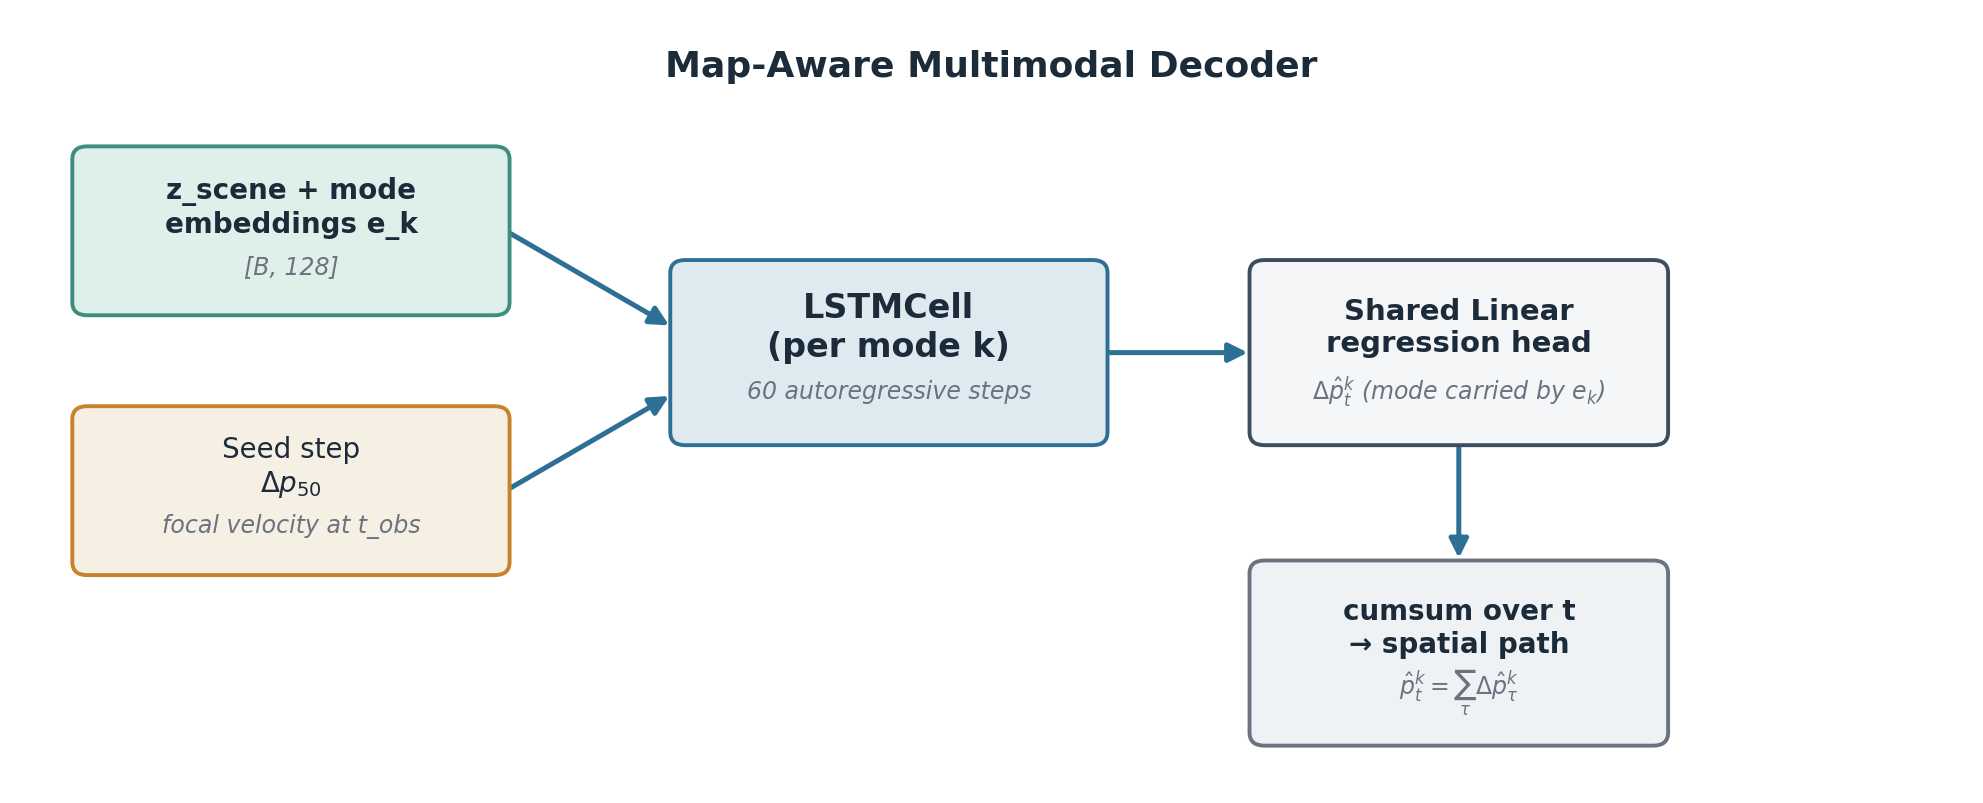

**Complete map-aware model definition:** Defines `MapAwareMultimodalTrajectoryPredictor`, which combines both encoders, scene fusion, the mode-conditioned decoder and the confidence head. Its forward pass takes the focal history, neighbor history and mask, and the lane tensor and mask. It returns displacement trajectories `(B, 6, 60, 2)` and confidence logits `(B, 6)`.

In [33]:
# =====================================================================
# MULTIMODAL DECODER & COMPLETE MODEL (Map + Social)
# =====================================================================
import torch
import torch.nn as nn


class MapAwareMultimodalTrajectoryPredictor(nn.Module):
    """Sprint 3: Complete Multimodal Social & Map Trajectory Forecasting Model.

    Combines the Social MHA Encoder and HD Map Encoder with a multi-mode
    autoregressive LSTMCell decoder loop to output K independent future path
    options.
    """

    def __init__(
        self,
        input_dim: int = 2,
        hidden_dim: int = 128,
        num_heads: int = 4,
        num_modes: int = 6,
        prediction_steps: int = 60,
    ):
        super(MapAwareMultimodalTrajectoryPredictor, self).__init__()
        self.hidden_dim = hidden_dim
        self.num_modes = num_modes
        self.prediction_steps = prediction_steps

        # 1. Encoders (Sprint 2 Social + Map Integration)
        self.social_encoder = MapAwareSocialEncoderMHA(
            input_dim=input_dim, hidden_dim=hidden_dim, num_heads=num_heads
        )
        self.map_encoder = MapEncoder(
            point_dim=input_dim, hidden_dim=hidden_dim, num_heads=num_heads
        )

        # 2. Scene Context Fusion Layer (Combines 128-dim Social + 128-dim Map -> 128-dim Scene)
        self.scene_fusion = nn.Sequential(
            nn.Linear(hidden_dim * 2, hidden_dim), nn.ReLU(), nn.Dropout(p=0.2)
        )

        # 3. Mode Identifier Embedding layer (Ensures diverse path options)
        self.mode_embedding = nn.Embedding(num_modes, hidden_dim)

        # 4. Step-by-Step Autoregressive Recurrent Core
        # Input: previous step displacement (2) + Mode Specific Identity Context (128)
        self.decoder_cell = nn.LSTMCell(
            input_size=input_dim + hidden_dim, hidden_size=hidden_dim
        )

        # 5. Trajectory Regression Head (Outputs time step displacement dx, dy)
        self.regression_head = nn.Linear(hidden_dim, input_dim)

        # 6. Scene Confidence Classification Head
        self.confidence_head = nn.Sequential(
            nn.Linear(hidden_dim, hidden_dim),
            nn.ReLU(),
            nn.Linear(hidden_dim, num_modes),
        )

        self.dropout = nn.Dropout(p=0.2)

    def forward(
        self, focal_hist, neighbor_hist, neighbor_mask, map_lanes, map_masks
    ):
        """Returns:

        pred_trajectories: [B, K, 60, 2] -> Relative coordinate displacements
        (dx, dy) confidence_scores: [B, K]       -> Raw unnormalized logits for
        the 6 modes
        """
        batch_size = focal_hist.size(0)

        # ---- Step 1: Extract & Fuse Social + Map Context Vectors ----
        social_context, h_focal = self.social_encoder(
            focal_hist, neighbor_hist, neighbor_mask
        )
        map_context = self.map_encoder(h_focal, map_lanes, map_masks)

        # Fuse both representations -> [B, hidden_dim]
        fused_raw = torch.cat([social_context, map_context], dim=-1)
        scene_context = self.scene_fusion(fused_raw)

        # ---- Step 2: Compute Mode Selection Confidences ----
        confidence_scores = self.confidence_head(scene_context)  # [B, K]

        # ---- Step 3: Expand Hidden States across all K Modes ----
        # [B, hidden_dim] -> [B, 1, hidden_dim] -> [B, K, hidden_dim] -> [B * K, hidden_dim]
        h_dec = (
            scene_context.unsqueeze(1)
            .repeat(1, self.num_modes, 1)
            .view(batch_size * self.num_modes, self.hidden_dim)
        )
        c_dec = torch.zeros_like(h_dec)

        # Generate mode identity embedding vectors
        mode_ids = torch.arange(
            self.num_modes, device=focal_hist.device
        ).repeat(batch_size)
        mode_embs = self.mode_embedding(mode_ids)  # [B * K, hidden_dim]

        # ---- Step 4: Autoregressive Decode Cycle Loop ----
        # Initial displacement input from final historical step: [B * K, 2]
        current_input = (
            focal_hist[:, -1, :]
            .unsqueeze(1)
            .repeat(1, self.num_modes, 1)
            .view(batch_size * self.num_modes, 2)
        )

        predictions = []

        for t in range(self.prediction_steps):
            h_dec_reg = self.dropout(h_dec)

            # Combine current step coordinate with mode identity context
            cell_input = torch.cat(
                [current_input, mode_embs], dim=-1
            )  # [B * K, 2 + hidden_dim]

            # Recurrent step
            h_dec, c_dec = self.decoder_cell(cell_input, (h_dec_reg, c_dec))

            # Extrapolate delta position
            delta_pos = self.regression_head(h_dec)  # [B * K, 2]
            predictions.append(delta_pos)

            current_input = delta_pos

        # Stack timesteps: [60, B * K, 2] -> [B * K, 60, 2]
        predictions = torch.stack(predictions, dim=0).permute(1, 0, 2)

        # Reshape to isolate modes cleanly -> [B, K, 60, 2]
        pred_trajectories = predictions.view(
            batch_size, self.num_modes, self.prediction_steps, 2
        )

        return pred_trajectories, confidence_scores

##### 3.4.4 Training Objective and Staged Training

**Staged training.** The model was trained in successive refinement stages. The first stage starts from random weights, and each later stage continues from the previous stage's checkpoint. The training cell falls back to random initialization if no checkpoint exists. The checkpoint reported throughout is `multimodal_social_map_aware_V4.pt`.

**Objective.** The loss of Section 3.3.4 is extended by a diversity term:

$$\mathcal{L}_{\text{total}} = \mathcal{L}_{\text{reg}}^{(k^{*})} + \beta \cdot \mathcal{L}_{\text{cls}} + \lambda \cdot \mathcal{L}_{\text{div}}$$

- **Regression:** the winner $k^{*}$ is the mode with the smallest mean Euclidean distance to the ground truth in position space, the same criterion as minADE. Section 3.3.4 used displacement space instead. Its distance forms $\mathcal{L}_{\text{reg}}^{(k^{*})}$.
- **Classification:** cross-entropy between the confidence logits and $k^{*}$.
- **Bounded diversity:** $\mathcal{L}_{\text{div}} = -\frac{1}{K^2}\sum_{k,k'} \min(\|\hat{p}^{k}_{T} - \hat{p}^{k'}_{T}\|_2,\, d_{cap})$ spreads mode endpoints apart up to $d_{cap}$. This counters mode collapse without rewarding arbitrarily distant modes.

**Configuration of the reported checkpoint (V4):**

| Parameter | Value |
| --- | --- |
| Optimizer | Adam, $\eta = 10^{-4}$, weight decay $10^{-4}$ |
| Batch size / neighbors | 128 / 10 |
| Loss weights | $\beta = 1.0$, $\lambda = 0.1$, $d_{cap} = 25$ m |
| Scheduler | `ReduceLROnPlateau` on val. regression loss (factor 0.5, patience 2) |
| Epochs | up to 35, early stopping (patience 5) on val. regression loss |
| Checkpoint selection | lowest val. regression loss |

The cells below check the forward and loss pass, define the training routines for the five-input model and run the stage-wise training.

**Full model and loss integrity check (map and social):** Passes `batch` from the previous cells through an untrained `MapAwareMultimodalTrajectoryPredictor` on `device`, using all three input streams (focal, social, map), and evaluates the `VarietyLoss` of Section 3.3.4. It confirms output shapes `(128, 6, 60, 2)` and `(128, 6)`, prints the three loss values and checks that they are finite.

In [34]:
# =====================================================================
# FULL ARCHITECTURE INTEGRITY AND FUSION CHECK (Map + Social)
# =====================================================================
if __name__ == "__main__":
    print(
        "Initializing complete Multimodal Architecture validation routine..."
    )

    # 1. Setup complete neural model instance on active device
    model = MapAwareMultimodalTrajectoryPredictor(
        input_dim=2,
        hidden_dim=128,
        num_heads=4,
        num_modes=6,
        prediction_steps=60,
    ).to(device)

    # 2. Setup Variety Loss core
    criterion = VarietyLoss(beta=1.0)

    # 3. Pull verification tensors from the active dataset batch instance
    f_hist = batch["focal_history"].to(device)  # [128, 50, 2]
    n_hist = batch["neighbor_history"].to(device)  # [128, 5, 50, 2]
    n_mask = batch["neighbor_mask"].to(device)  # [128, 5]
    m_lanes = batch["map_lanes"].to(device)  # [128, L, P, 2]
    m_masks = batch["map_masks"].to(device)  # [128, L]
    f_fut = batch["focal_future"].to(device)  # [128, 60, 2]

    model.eval()
    with torch.no_grad():
        # Execute absolute forward pass with map stream integration
        trajectories, confidences = model(
            f_hist, n_hist, n_mask, m_lanes, m_masks
        )

        # Execute absolute loss parsing pass
        total_loss, reg_loss, cls_loss = criterion(
            trajectories, confidences, f_fut
        )

    print("\n" + "=" * 55)
    print("      FINAL MULTIMODAL PIPELINE VERIFICATION REPORT      ")
    print("=" * 55)
    print(
        f"Predicted Trajectories Matrix Shape: {list(trajectories.shape)} ->"
        " Target: [128, 6, 60, 2]"
    )
    print(
        f"Confidence Evaluation Score Shape  : {list(confidences.shape)} ->"
        " Target: [128, 6]"
    )
    print(f"Parsed Total Combined Batch Loss   : {total_loss.item():.4f}")
    print(f"Parsed Pure Path Regression Loss   : {reg_loss.item():.4f}")
    print(f"Parsed Pure Path Classification Loss: {cls_loss.item():.4f}")
    print("=" * 55)

    assert trajectories.shape == (
        128,
        6,
        60,
        2,
    ), "Multimodal generation dimensions broken!"
    assert confidences.shape == (
        128,
        6,
    ), "Classification prediction head shape mismatch!"
    print(
        " MISSION STATUS: ABSOLUTE SUCCESS! Complete model is structurally"
        " verified and ready for deployment."
    )

Initializing complete Multimodal Architecture validation routine...

      FINAL MULTIMODAL PIPELINE VERIFICATION REPORT      
Predicted Trajectories Matrix Shape: [128, 6, 60, 2] -> Target: [128, 6, 60, 2]
Confidence Evaluation Score Shape  : [128, 6] -> Target: [128, 6]
Parsed Total Combined Batch Loss   : 1.9344
Parsed Pure Path Regression Loss   : 0.1112
Parsed Pure Path Classification Loss: 1.8232
 MISSION STATUS: ABSOLUTE SUCCESS! Complete model is structurally verified and ready for deployment.


**Map-aware training and validation routines:** Defines `train_one_epoch_map` (with gradient clipping) and `validate_epoch_map` for the five-input map-aware model.

In [35]:
# =====================================================================
# MULTIMODAL SOCIAL & MAP TRAINING LOOP IMPLEMENTATION
# =====================================================================
import time
import torch


def train_one_epoch_map(
    model, dataloader, optimizer, criterion, device, clip_value=5.0
):
    model.train()
    total_epoch_loss = 0.0
    total_reg_loss = 0.0
    total_cls_loss = 0.0

    for batch_idx, batch in enumerate(dataloader):
        # 1. Move multi-agent & map structural tensors to active device
        f_hist = batch["focal_history"].to(device)  # [B, 50, 2]
        n_hist = batch["neighbor_history"].to(device)  # [B, 5, 50, 2]
        n_mask = batch["neighbor_mask"].to(device)  # [B, 5]
        m_lanes = batch["map_lanes"].to(device)  # [B, L, P, 2]
        m_masks = batch["map_masks"].to(device)  # [B, L]
        f_fut = batch["focal_future"].to(device)  # [B, 60, 2]

        optimizer.zero_grad()

        # 2. Forward execution pass -> Outputs K paths and raw logit scores
        pred_paths, conf_scores = model(
            f_hist, n_hist, n_mask, m_lanes, m_masks
        )

        # 3. Calculate Winner-Take-All (WTA) variety metrics
        loss, reg_loss, cls_loss = criterion(pred_paths, conf_scores, f_fut)

        # 4. Backward propagation and gradient clipping safeguard
        loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=clip_value)
        optimizer.step()

        # 5. Accumulate telemetry metrics
        total_epoch_loss += loss.item()
        total_reg_loss += reg_loss.item()
        total_cls_loss += cls_loss.item()

    num_batches = len(dataloader)
    return (
        total_epoch_loss / num_batches,
        total_reg_loss / num_batches,
        total_cls_loss / num_batches,
    )


def validate_epoch_map(model, dataloader, criterion, device):
    model.eval()
    total_epoch_loss = 0.0
    total_reg_loss = 0.0
    total_cls_loss = 0.0

    with torch.no_grad():
        for batch in dataloader:
            f_hist = batch["focal_history"].to(device)
            n_hist = batch["neighbor_history"].to(device)
            n_mask = batch["neighbor_mask"].to(device)
            m_lanes = batch["map_lanes"].to(device)
            m_masks = batch["map_masks"].to(device)
            f_fut = batch["focal_future"].to(device)

            pred_paths, conf_scores = model(
                f_hist, n_hist, n_mask, m_lanes, m_masks
            )
            loss, reg_loss, cls_loss = criterion(
                pred_paths, conf_scores, f_fut
            )

            total_epoch_loss += loss.item()
            total_reg_loss += reg_loss.item()
            total_cls_loss += cls_loss.item()

    num_batches = len(dataloader)
    return (
        total_epoch_loss / num_batches,
        total_reg_loss / num_batches,
        total_cls_loss / num_batches,
    )

**Demonstration mode:** By default (`DEMO_MODE = True`), the cell below trains for 2 epochs on the sample files from Section 3.4.1 and saves `multimodal_social_map_aware_demo.pt`. `DEMO_MODE = False` runs the latest refinement stage on the full data (up to 20 epochs, patience 4), which loads `Map_aware_output/multimodal_social_map_aware_V5.pt` and saves `multimodal_social_map_aware_V6.pt`. This stage ran after the reported checkpoint; all results in Section 5 use `V4`.

**Map-aware stage-wise training:** Builds the training and validation DataLoaders (10 neighbors) for the selected mode, loads the previous-stage checkpoint if available (otherwise it starts from random weights), defines `BoundedWTA_DiversityLoss` and continues training with learning-rate scheduling and early stopping. It prints a per-epoch loss table and saves the best checkpoint in the working directory.

In [38]:
# =====================================================================
# PIPELINE EXECUTION CORE
# =====================================================================
import os
import time
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader

if __name__ == "__main__":
  # --- 0. Execution Mode ---
  #   DEMO_MODE = True  -> quick check on the 100-scenario sample files, 2 epochs
  #   DEMO_MODE = False -> full fine-tuning on the complete server files, 20 epochs
  DEMO_MODE = True

  # --- 1. Hyperparameters Allocation ---
  BATCH_SIZE = 32 if DEMO_MODE else 128
  EPOCHS = 2 if DEMO_MODE else 20  # 5-8 epochs is ideal for bounded fine-tuning
  LEARNING_RATE = 1e-4  # Stable LR for fine-tuning
  NUM_MODES = 6
  MAX_NEIGHBORS = 10
  BETA_WEIGHT = 1.0
  LAMBDA_DIVERSITY = 0.1  # Weight for bounded diversity
  MAX_DIST_CAP = 25.0  # Cap diversity reward at 25 meters max mode spread
  PATIENCE = 4

  PREV_CHECKPOINT_PATH = "Map_aware_output/multimodal_social_map_aware_V5.pt"

  if DEMO_MODE:
    # 100-scenario samples written by the map-aware preprocessing cell above
    TRAIN_FILE = "sample_av2_train_map_aware.npy"
    VAL_FILE = "sample_av2_val_map_aware.npy"
    NEW_CHECKPOINT_PATH = "multimodal_social_map_aware_demo.pt"  # never overwrites trained weights
  else:
    TRAIN_FILE = "Map_aware_output/av2_train_map_aware.npy"
    VAL_FILE = "Map_aware_output/av2_val_map_aware.npy"
    NEW_CHECKPOINT_PATH = "multimodal_social_map_aware_V6.pt"

  # --- 2. Dataloader Initializations ---
  print(f"Mode: {'DEMO' if DEMO_MODE else 'FULL'} | Initializing Multi-Agent Social & Map Datasets...")
  train_dataset = MapAwareArgoverseSocialDataset(TRAIN_FILE, max_neighbors=MAX_NEIGHBORS)
  val_dataset = MapAwareArgoverseSocialDataset(VAL_FILE, max_neighbors=MAX_NEIGHBORS)

  map_train_loader = DataLoader(
      train_dataset,
      batch_size=BATCH_SIZE,
      shuffle=True,
      num_workers=0,
      pin_memory=True,
  )
  map_val_loader = DataLoader(
      val_dataset,
      batch_size=BATCH_SIZE,
      shuffle=False,
      num_workers=0,
      pin_memory=True,
  )

  # --- 3. Model & Optimization Setup ---
  device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
  model = MapAwareMultimodalTrajectoryPredictor(
      input_dim=2,
      hidden_dim=128,
      num_heads=4,
      num_modes=NUM_MODES,
      prediction_steps=60,
  ).to(device)

  # Reload previous checkpoint as the fine-tuning starting point
  if os.path.exists(PREV_CHECKPOINT_PATH):
    print(f" Loading weights from '{PREV_CHECKPOINT_PATH}' for fine-tuning...")
    ckpt = torch.load(PREV_CHECKPOINT_PATH, map_location=device, weights_only=False)
    state_dict = (
        ckpt["model_state_dict"]
        if isinstance(ckpt, dict) and "model_state_dict" in ckpt
        else ckpt
    )
    model.load_state_dict(state_dict, strict=False)
    print(" Previous weights successfully reloaded!")
  else:
    print(
        f"Warning: '{PREV_CHECKPOINT_PATH}' not found. Training from scratch."
    )

  optimizer = torch.optim.Adam(
      model.parameters(), lr=LEARNING_RATE, weight_decay=1e-4
  )


  # Bounded Diversity Loss Definition
  class BoundedWTA_DiversityLoss(nn.Module):

    def __init__(self, beta=1.0, lambda_div=0.05, max_dist_cap=15.0):
      super().__init__()
      self.beta = beta
      self.lambda_div = lambda_div
      self.max_dist_cap = max_dist_cap

    def forward(self, pred_disps, pred_probs, gt_disps):
      # Convert displacements to trajectory coordinates via cumulative sum
      pred_paths = torch.cumsum(pred_disps, dim=2)  # [B, K, 60, 2]
      gt_path = torch.cumsum(gt_disps, dim=1)  # [B, 60, 2]

      B, K, T, _ = pred_paths.shape

      # 1. Winner-Takes-All Spatial Loss (Best matching mode)
      gt_expanded = gt_path.unsqueeze(1)  # [B, 1, 60, 2]
      dist = torch.norm(pred_paths - gt_expanded, dim=-1).mean(
          dim=-1
      )  # [B, K]
      best_mode_idx = torch.argmin(dist, dim=1)  # [B]

      reg_loss = dist[torch.arange(B), best_mode_idx].mean()

      # 2. Classification Loss
      cls_loss = F.cross_entropy(pred_probs, best_mode_idx)

      # 3. BOUNDED Endpoint Diversity Loss
      endpoints = pred_paths[:, :, -1, :]  # [B, K, 2]
      pdist = torch.cdist(endpoints, endpoints, p=2)  # [B, K, K]

      # Clamp diversity rewards at max_dist_cap to keep trajectories on-road
      bounded_pdist = torch.clamp(pdist, max=self.max_dist_cap)
      diversity_loss = -bounded_pdist.mean()

      total_loss = (
          reg_loss + (self.beta * cls_loss) + (self.lambda_div * diversity_loss)
      )
      return total_loss, reg_loss, cls_loss


  criterion = BoundedWTA_DiversityLoss(
      beta=BETA_WEIGHT, lambda_div=LAMBDA_DIVERSITY, max_dist_cap=MAX_DIST_CAP
  )

  scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
      optimizer, mode="min", factor=0.5, patience=2
  )

  best_val_loss = float("inf")
  patience_counter = 0

  # --- 4. Main Training Orchestration Loop ---
  print(
      f"\n Launching Bounded Diversity Fine-Tuning Run on {device}"
      f" ({torch.cuda.get_device_name(0) if torch.cuda.is_available() else 'CPU'})..."
  )
  print(f" {len(train_dataset)} train / {len(val_dataset)} val scenarios, up to {EPOCHS} epochs")
  print("=" * 90)
  print(
      f"{'Epoch':<6} | {'Train Loss':<10} | {'Train Reg':<10} |"
      f" {'Train Cls':<10} | {'Val Loss':<10} | {'Val Reg':<10} |"
      f" {'Time (s)':<8}"
  )
  print("=" * 90)

  for epoch in range(1, EPOCHS + 1):
    start_time = time.time()

    # --- Training Pass ---
    model.train()
    t_loss, t_reg, t_cls = 0.0, 0.0, 0.0
    for batch in map_train_loader:
      optimizer.zero_grad()

      f_hist = batch["focal_history"].to(device)
      n_hist = batch["neighbor_history"].to(device)
      n_mask = batch["neighbor_mask"].to(device)
      m_lanes = batch["map_lanes"].to(device)
      m_masks = batch["map_masks"].to(device)
      gt_disps = batch["focal_future"].to(device)

      paths, probs = model(f_hist, n_hist, n_mask, m_lanes, m_masks)
      loss, reg, cls_val = criterion(paths, probs, gt_disps)

      loss.backward()
      optimizer.step()

      t_loss += loss.item()
      t_reg += reg.item()
      t_cls += cls_val.item()

    t_loss /= len(map_train_loader)
    t_reg /= len(map_train_loader)
    t_cls /= len(map_train_loader)

    # --- Validation Pass ---
    model.eval()
    v_loss, v_reg, v_cls = 0.0, 0.0, 0.0
    with torch.no_grad():
      for batch in map_val_loader:
        f_hist = batch["focal_history"].to(device)
        n_hist = batch["neighbor_history"].to(device)
        n_mask = batch["neighbor_mask"].to(device)
        m_lanes = batch["map_lanes"].to(device)
        m_masks = batch["map_masks"].to(device)
        gt_disps = batch["focal_future"].to(device)

        paths, probs = model(f_hist, n_hist, n_mask, m_lanes, m_masks)
        loss, reg, cls_val = criterion(paths, probs, gt_disps)

        v_loss += loss.item()
        v_reg += reg.item()
        v_cls += cls_val.item()

    v_loss /= len(map_val_loader)
    v_reg /= len(map_val_loader)
    v_cls /= len(map_val_loader)

    scheduler.step(v_reg)
    epoch_time = time.time() - start_time

    print(
        f"{epoch:<6} | {t_loss:<10.4f} | {t_reg:<10.4f} | {t_cls:<10.4f} |"
        f" {v_loss:<10.4f} | {v_reg:<10.4f} | {epoch_time:<8.1f}"
    )

    # --- 5. Checkpoint & Early Stopping Logic ---
    if v_reg < best_val_loss:
      best_val_loss = v_reg
      patience_counter = 0

      checkpoint = {
          "epoch": epoch,
          "model_state_dict": model.state_dict(),
          "optimizer_state_dict": optimizer.state_dict(),
          "best_val_loss": best_val_loss,
      }
      torch.save(checkpoint, NEW_CHECKPOINT_PATH)
      print(
          f"   --->  Checkpoint saved at Epoch {epoch} (Val Reg:"
          f" {v_reg:.4f})"
      )
    else:
      patience_counter += 1
      print(
          f"   --->  No spatial improvement for {patience_counter}/{PATIENCE}"
          " epochs."
      )

      if patience_counter >= PATIENCE:
        print("\n" + "=" * 90)
        print(f" EARLY STOPPING TRIGGERED AT EPOCH {epoch}!")
        print("=" * 90)
        break

  print(
      f"\n FINE-TUNING CONCLUDED! Model saved as"
      f" '{NEW_CHECKPOINT_PATH}'"
  )

Mode: DEMO | Initializing Multi-Agent Social & Map Datasets...
 Streaming map-aware scenario dictionaries from disk: sample_av2_train_map_aware.npy
 Social & Map Matrix Loaded! Total Scenarios: 100
Trajectory Matrix Shape: (11, 110, 2) -> (Actors, Timesteps, XY)
HD Map Tensor Shape:     (16, 10, 2) -> (Lanes, Points, XY)
 Streaming map-aware scenario dictionaries from disk: sample_av2_val_map_aware.npy
 Social & Map Matrix Loaded! Total Scenarios: 100
Trajectory Matrix Shape: (11, 110, 2) -> (Actors, Timesteps, XY)
HD Map Tensor Shape:     (16, 10, 2) -> (Lanes, Points, XY)
 Loading weights from 'Map_aware_output/multimodal_social_map_aware_V5.pt' for fine-tuning...
 Previous weights successfully reloaded!

 Launching Bounded Diversity Fine-Tuning Run on cuda (NVIDIA A40)...
 100 train / 100 val scenarios, up to 2 epochs
Epoch  | Train Loss | Train Reg  | Train Cls  | Val Loss   | Val Reg    | Time (s)
1      | -0.2827    | 0.9119     | 0.7659     | -0.4946    | 0.8343     | 0.2     
 

##### 3.4.5 Evaluation Protocol III: Oracle vs. Top-1 Evaluation

A multimodal model can be judged by whether it *represents* the correct future offline, or by how accurate it is at deployment. These are different questions.

**Oracle evaluation ($\text{minADE}_6$ / $\text{minFDE}_6$).** With the ground truth known, the metric selects the closest of the K = 6 modes:

$$k^{*} = \arg\min_{k} \frac{1}{T} \sum_{t=1}^{T} \| p_t^k - p_t^{gt} \|_2$$

This checks whether the ground truth is captured *somewhere* among the modes. It implicitly assumes that a planner could compare all modes against the unknown future, which is not possible in practice.

**Top-1 evaluation ($\text{ADE}_1$ / $\text{FDE}_1$).** At deployment, the planner must rely on the confidence logits $c$ and pick the most confident mode, $\hat{k} = \arg\max_k c_k$. The metrics are computed for $\hat{k}$ only, so this tests both trajectory quality and whether the confidence head ranks the best mode first. The evaluation also reports how often $\hat{k} = k^{*}$. The gap between the two protocols is quantified in Section 5.1.4 and analyzed in Section 5.2.4.

#### 3.5 Pedestrian-Specific Forecasting: Map-Aware Social-LSTM

The preceding models target vehicles, whose motion follows lanes and kinematic limits. Pedestrians are not bound to lanes: they turn, stop and change direction abruptly and interact closely with nearby pedestrians. The **pedestrian-specific Map-Aware Social-LSTM** is therefore a separate, deterministic multi-agent model operating on a 40-step window ($2.0\,\text{s}$ history and $2.0\,\text{s}$ future at $10\,\text{Hz}$).

The first cell imports the dependencies and defines the configuration shared by all pedestrian cells.

**Pedestrian configuration:** Imports the dependencies and defines the pedestrian pipeline configuration (20-frame history and future, 4 × 4 social grid, 5.0 m pooling radius, map feature dimensions) and the `CachedDataset` wrapper.

In [39]:
import os
import json
from pathlib import Path
import numpy as np
import pandas as pd
import torch
from torch import nn
from torch.utils.data import Dataset, DataLoader
import matplotlib.pyplot as plt
from tqdm import tqdm
import random
import time

# --- Configuration ---
HIST_LEN = 20
FUT_LEN = 20
GRID_SIZE = 4
RADIUS = 5.0   
HIDDEN_DIM = 128
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

LANE_TYPE_VOCAB = ["VEHICLE", "BIKE", "BUS", "PEDESTRIAN", "MIXED", "SHOULDER", "UNKNOWN", "OTHER"]
LANE_MARK_VOCAB = ["NONE", "DASHED", "SOLID", "DOUBLE_SOLID", "DASH_SOLID", "SOLID_DASH_SOLID", "UNKNOWN", "OTHER"]

LANE_FEAT_DIM = 6 + len(LANE_TYPE_VOCAB) + 2 * len(LANE_MARK_VOCAB)
CROSSING_FEAT_DIM = 9   
DRIVABLE_FEAT_DIM = 7   
MAP_CTX_DIM = LANE_FEAT_DIM + CROSSING_FEAT_DIM + DRIVABLE_FEAT_DIM

class CachedDataset(Dataset):
    def __init__(self, samples):
        self.samples = samples

    def __len__(self):
        return len(self.samples)

    def __getitem__(self, idx):
        return self.samples[idx]

##### 3.5.1 Motivation and Theoretical Foundation

The design combines two works on human trajectory prediction, adapted to the vector format of Argoverse 2:

1. **Social LSTM:** A standard LSTM ignores other agents. Alahi et al. [[9]](https://openaccess.thecvf.com/content_cvpr_2016/html/Alahi_Social_LSTM_Human_CVPR_2016_paper.html) connect the LSTMs of nearby pedestrians through a social pooling layer that shares their hidden states. This is used here to model collision avoidance and group walking.

2. **SS-LSTM (Social-Scene LSTM):** Social LSTM ignores the scene layout. Xue et al. [[11]](https://ieeexplore.ieee.org/document/8354239) add person, social and scene scales, where the scene scale applies a convolutional neural network (CNN) to raw video frames. Since Argoverse 2 provides vector maps in JSON format rather than images, the CNN is replaced here by a geometric feature engine that builds the scene context.

##### 3.5.2 HD Map Context Engine (Custom Scene Scale)

A `MapContextEngine` replaces the image-based CNN of SS-LSTM and parses the Argoverse 2 JSON map geometries directly. Pedestrian behavior depends strongly on boundaries, in particular whether a pedestrian is inside a crosswalk or a drivable area.

For a batch of $A$ agents, the engine computes a 46-dimensional map context vector from three feature subsets:

| Drivable Areas (7 dims) | Lane Segments (30 dims) | Pedestrian Crossings (9 dims) |
| :--- | :--- | :--- |
| Perpendicular distance to nearest edge | Distance to nearest centerline edge | Centroid |
| Direction of normal to nearest edge | Direction to nearest centerline edge | Orientation |
| Area of the polygon | Distance to left / right boundary | Width and length |
| Nearest point on the nearest edge | Is intersection? | Distance from adjacent edges 1 & 2 |
| Inside the drivable area? | Lane type (one-hot) | Inside the crossing? |
| | Left / right lane-mark type | |

For each of the three element types, the features of all valid map elements within a radius of $20.0\,\text{m}$ of the pedestrian (the default `map_radius` of the `MapContextEngine`) are pooled by a masked average, and the three pooled vectors are concatenated into the 46-dimensional map context.

**Map context engine:** Defines the batched geometric helpers, the `MapContextEngine` for the 46-dimensional map context, and `prepare_map_tensors`, which parses the JSON maps into padded polyline tensors.

In [40]:
def batched_polyline_distances(p, poly, eps=1e-8):
    """
    Computes shortest distance from multiple points to multiple polylines.
    p: (A, 2) - Agent positions
    poly: (N, P, 2) - Map polylines (lanes, crossings, etc.)
    Returns: 
        q_best: (A, N, 2) Nearest points on polylines
        d_best: (A, N) Distances to nearest points
    """
    A = p.shape[0]
    N, P, _ = poly.shape

    # Expand dimensions for broadcasting: (A, N, P-1, 2)
    p_ext = p.view(A, 1, 1, 2)
    a = poly[:, :-1, :].unsqueeze(0) 
    b = poly[:, 1:, :].unsqueeze(0)

    ab = b - a 
    ap = p_ext - a 

    denom = (ab * ab).sum(dim=-1) 
    denom = torch.clamp(denom, min=eps)

    t = (ap * ab).sum(dim=-1) / denom
    t = torch.clamp(t, min=0.0, max=1.0)

    q = a + t.unsqueeze(-1) * ab
    dist = torch.norm(p_ext - q, dim=-1)

    # Find the minimum distance along the segment dimension (P-1)
    d_best, min_idx = torch.min(dist, dim=2)
    
    # Gather the coordinates of the nearest point
    min_idx_expanded = min_idx.unsqueeze(-1).unsqueeze(-1).expand(A, N, 1, 2)
    q_best = q.gather(2, min_idx_expanded).squeeze(2)

    return q_best, d_best

def batched_point_in_polygon(p, poly):
    """
    Ray casting algorithm for multiple points and multiple polygons.
    p: (A, 2)
    poly: (N, P, 2)
    Returns: (A, N) boolean mask (True if point is inside polygon)
    """
    A = p.shape[0]
    
    x = p[:, 0].view(A, 1, 1)
    y = p[:, 1].view(A, 1, 1)

    xi = poly[:, :, 0].unsqueeze(0)
    yi = poly[:, :, 1].unsqueeze(0)
    xj = torch.roll(xi, shifts=1, dims=2)
    yj = torch.roll(yi, shifts=1, dims=2)

    intersect1 = (yi > y) != (yj > y)
    intersect2 = x < (xj - xi) * (y - yi) / (yj - yi + 1e-12) + xi

    intersections = (intersect1 & intersect2).sum(dim=2)
    return (intersections % 2) == 1

def canonical_unit_vector(dx, dy, eps=1e-8):
    """Batched canonical unit vector (returns vec and norm)."""
    norm = torch.sqrt(dx**2 + dy**2)
    norm_clamped = torch.clamp(norm, min=eps)
    
    vec_x = dx / norm_clamped
    vec_y = dy / norm_clamped
    
    # Flip logic for canonical orientation
    flip = (vec_x < 0) | ((torch.abs(vec_x) <= eps) & (vec_y < 0))
    
    vec_x = torch.where(flip, -vec_x, vec_x)
    vec_y = torch.where(flip, -vec_y, vec_y)
    
    return torch.stack([vec_x, vec_y], dim=-1), norm

class MapContextEngine(nn.Module):
    def __init__(self, map_radius=20.0, lane_feat_dim=LANE_FEAT_DIM, cross_feat_dim=CROSSING_FEAT_DIM, drive_feat_dim=DRIVABLE_FEAT_DIM):
        super().__init__()
        self.map_radius = map_radius
        self.lane_feat_dim = lane_feat_dim
        self.cross_feat_dim = cross_feat_dim
        self.drive_feat_dim = drive_feat_dim
        
        # Initialize empty buffers (populated by setup_map_tensors)
        self.register_buffer('lane_centerlines', torch.empty(0))
        self.register_buffer('lane_left_bounds', torch.empty(0))
        self.register_buffer('lane_right_bounds', torch.empty(0))
        self.register_buffer('lane_static_feats', torch.empty(0))
        
        self.register_buffer('cross_side1', torch.empty(0))
        self.register_buffer('cross_side2', torch.empty(0))
        self.register_buffer('cross_poly', torch.empty(0))
        self.register_buffer('cross_centroid', torch.empty(0))
        
        self.register_buffer('drive_bounds', torch.empty(0))
        self.register_buffer('drive_area', torch.empty(0))
        
    def setup_map_tensors(self, map_tensors_dict):
        """
        Safely overwrites the existing map buffers with new ones of different shapes,
        ensuring they are placed on the correct device.
        """
        # Figure out what device the engine is currently on
        device = next(self.buffers()).device
        
        for key, tensor in map_tensors_dict.items():
            # Re-registering the buffer handles shape changes perfectly
            self.register_buffer(key, tensor.to(device))

    def forward(self, p):
        """
        p: (A, 2) batch of agent coordinates
        Returns: (A, MAP_CTX_DIM) concatenated context vectors
        """
        A = p.shape[0]
        
        # FIX: Expand dimensions to (A, 1) so they broadcast correctly against (A, N) map tensors
        px = p[:, 0].unsqueeze(1)
        py = p[:, 1].unsqueeze(1)
        
        # 1. Lane Features
        lane_pool = torch.zeros(A, self.lane_feat_dim, device=p.device)
        if self.lane_centerlines.numel() > 0:
            q_c, d_c = batched_polyline_distances(p, self.lane_centerlines)
            _, d_l = batched_polyline_distances(p, self.lane_left_bounds)
            _, d_r = batched_polyline_distances(p, self.lane_right_bounds)
            
            # Use px and py to prevent the shape mismatch
            dir_c, _ = canonical_unit_vector(q_c[..., 0] - px, q_c[..., 1] - py)
            
            # Combine numeric features (A, N, 6)
            numeric_feats = torch.stack([
                d_c, dir_c[..., 0], dir_c[..., 1], d_l, d_r,
                self.lane_static_feats[:, 0].expand(A, -1) # is_intersection
            ], dim=-1)
            
            # Combine static one-hot features (A, N, static_dim-1)
            static_one_hot = self.lane_static_feats[:, 1:].unsqueeze(0).expand(A, -1, -1)
            
            lane_feats = torch.cat([numeric_feats, static_one_hot], dim=-1) # (A, N, F)
            
            # Mask based on nearest distance and mean pool
            nd = torch.min(torch.min(d_c, d_l), d_r)
            mask = nd <= self.map_radius
            
            # Weighted average pool (mean of valid lanes)
            valid_counts = mask.sum(dim=1, keepdim=True).clamp(min=1)
            lane_pool = (lane_feats * mask.unsqueeze(-1)).sum(dim=1) / valid_counts

        # 2. Crossing Features
        cross_pool = torch.zeros(A, self.cross_feat_dim, device=p.device)
        if self.cross_poly.numel() > 0:
            # We still use edge1/edge2 mathematically to get width/length/orientation
            # but we can approximate orientation from side1 instead to save buffers
            side1_vec = self.cross_side1[:, 1] - self.cross_side1[:, 0]
            ori, len1 = canonical_unit_vector(side1_vec[:, 0], side1_vec[:, 1])
            len2 = torch.norm(self.cross_side2[:, 1] - self.cross_side2[:, 0], dim=-1)
            length = 0.5 * (len1 + len2)
            
            mid1 = self.cross_side1.mean(dim=1)
            mid2 = self.cross_side2.mean(dim=1)
            width = torch.norm(mid1 - mid2, dim=-1)
            
            # MEASURE DISTANCE TO SIDE EDGES (along the road)
            _, d1 = batched_polyline_distances(p, self.cross_side1)
            _, d2 = batched_polyline_distances(p, self.cross_side2)
            inside = batched_point_in_polygon(p, self.cross_poly).float()
            
            # RELATIVE CENTROID
            cent_dx = self.cross_centroid[:, 0].unsqueeze(0) - px
            cent_dy = self.cross_centroid[:, 1].unsqueeze(0) - py
            
            cross_feats = torch.stack([
                ori[:, 0].expand(A, -1), ori[:, 1].expand(A, -1),
                width.expand(A, -1), length.expand(A, -1),
                d1, d2, inside, cent_dx, cent_dy
            ], dim=-1)
            
            nd = torch.minimum(d1, d2)
            mask = nd <= self.map_radius
            
            valid_counts = mask.sum(dim=1, keepdim=True).clamp(min=1)
            cross_pool = (cross_feats * mask.unsqueeze(-1)).sum(dim=1) / valid_counts

        # 3. Drivable Area Features
        drive_pool = torch.zeros(A, self.drive_feat_dim, device=p.device)
        if self.drive_bounds.numel() > 0:
            q, d = batched_polyline_distances(p, self.drive_bounds)
            
            dx, dy = q[..., 0] - px, q[..., 1] - py
            norm = torch.sqrt(dx**2 + dy**2).clamp(min=1e-8)
            dir_x, dir_y = dx / norm, dy / norm
            
            inside = batched_point_in_polygon(p, self.drive_bounds).float()
            
            # Add the pre-calculated area to the feature stack
            area_feat = (self.drive_area / 1000.0).unsqueeze(0).expand(A, -1)
            
            drive_feats = torch.stack([
                d, dir_x, dir_y, dx, dy, inside, area_feat
            ], dim=-1)
            
            mask = d <= self.map_radius
            valid_counts = mask.sum(dim=1, keepdim=True).clamp(min=1)
            drive_pool = (drive_feats * mask.unsqueeze(-1)).sum(dim=1) / valid_counts

        return torch.cat([lane_pool, cross_pool, drive_pool], dim=-1)
    
def _pts_to_xy(points):
    """
    Convert a list of dicts [{'x':..., 'y':..., 'z':...}, ...] to a (N,2) float32 array.
    """
    return np.array([[float(p["x"]), float(p["y"])] for p in points], dtype=np.float32)

def _one_hot(value, vocab):
    """
    One-hot encode a categorical value.
    """
    v = str(value).upper()
    if v not in vocab:
        v = "OTHER" if "OTHER" in vocab else vocab[-1]
    out = np.zeros(len(vocab), dtype=np.float32)
    out[vocab.index(v)] = 1.0
    return out

def prepare_map_tensors(map_data):
    """
    Run this ONCE to convert your JSON map_data into PyTorch tensors.
    """
    def pad_polylines(poly_list):
        # 1. Dynamically find the max length in THIS specific list
        max_pts = max((len(p) for p in poly_list), default=0)
        # 2. Ensure at least 2 points so distance calculations (segments) don't crash
        max_pts = max(max_pts, 2) 

        padded = []
        for poly in poly_list:
            poly = np.array(poly, dtype=np.float32)
            
            if len(poly) == 0:
                # Safeguard: If a boundary is missing entirely, put it far away 
                # so it doesn't trigger false interactions
                padded.append(np.full((max_pts, 2), 1e5, dtype=np.float32))
            else:
                if len(poly) < max_pts:
                    # Repeat the last point to fill the array
                    padding = np.tile(poly[-1:], (max_pts - len(poly), 1))
                    poly = np.vstack([poly, padding])
                padded.append(poly)
                
        return torch.tensor(np.stack(padded))

    tensors = {}
    
    # ----------------------------
    # 1. Lanes
    # ----------------------------
    lanes = list(map_data.get("lane_segments", {}).values())
    if lanes:
        tensors['lane_centerlines'] = pad_polylines([_pts_to_xy(l.get("centerline", [])) for l in lanes])
        tensors['lane_left_bounds'] = pad_polylines([_pts_to_xy(l.get("left_lane_boundary", [])) for l in lanes])
        tensors['lane_right_bounds'] = pad_polylines([_pts_to_xy(l.get("right_lane_boundary", [])) for l in lanes])
        
        static_feats = []
        for l in lanes:
            is_int = 1.0 if l.get("is_intersection", False) else 0.0
            l_type = _one_hot(l.get("lane_type", "OTHER"), LANE_TYPE_VOCAB)
            l_mark = _one_hot(l.get("left_lane_mark_type", "OTHER"), LANE_MARK_VOCAB)
            r_mark = _one_hot(l.get("right_lane_mark_type", "OTHER"), LANE_MARK_VOCAB)
            static_feats.append(np.concatenate([[is_int], l_type, l_mark, r_mark]))
        tensors['lane_static_feats'] = torch.tensor(np.stack(static_feats), dtype=torch.float32)

    # ----------------------------
    # 2. Pedestrian Crossings
    # ----------------------------
    crossings = list(map_data.get("pedestrian_crossings", {}).values())
    if crossings:
        cross_polys, side1_list, side2_list, centroids = [], [], [], []
        
        for c in crossings:
            e1 = _pts_to_xy(c.get("edge1", []))
            e2 = _pts_to_xy(c.get("edge2", []))
            if len(e1) > 0 and len(e2) > 0:
                poly = np.vstack([e1, e2[::-1]])
                # Extract the edges "along the road" by connecting endpoints
                side1 = np.vstack([e1[0], e2[0]])
                side2 = np.vstack([e1[-1], e2[-1]])
                # Calculate absolute centroid
                centroid = poly.mean(axis=0)
            else:
                poly = np.array([], dtype=np.float32)
                side1 = np.array([], dtype=np.float32)
                side2 = np.array([], dtype=np.float32)
                centroid = np.array([0.0, 0.0], dtype=np.float32)
                
            cross_polys.append(poly)
            side1_list.append(side1)
            side2_list.append(side2)
            centroids.append(centroid)
            
        tensors['cross_poly'] = pad_polylines(cross_polys)
        tensors['cross_side1'] = pad_polylines(side1_list)
        tensors['cross_side2'] = pad_polylines(side2_list)
        tensors['cross_centroid'] = torch.tensor(np.stack(centroids), dtype=torch.float32)

    # ----------------------------
    # 3. Drivable Areas
    # ----------------------------
    drive_areas = list(map_data.get("drivable_areas", {}).values())
    if drive_areas:
        tensors['drive_bounds'] = pad_polylines([_pts_to_xy(d.get("area_boundary", [])) for d in drive_areas])
        
        # Calculate polygon area using Shoelace formula
        areas = []
        for d in drive_areas:
            p = _pts_to_xy(d.get("area_boundary", []))
            if len(p) >= 3:
                area = 0.5 * np.abs(np.dot(p[:,0], np.roll(p[:,1], 1)) - np.dot(p[:,1], np.roll(p[:,0], 1)))
            else:
                area = 0.0
            areas.append(area)
        tensors['drive_area'] = torch.tensor(areas, dtype=torch.float32)
        
    return tensors

##### 3.5.3 Dynamic Social Pooling

To aggregate the latent intentions (hidden states) of surrounding pedestrians, a vectorized social pooling layer is implemented. A $4 \times 4$ spatial grid is constructed around each agent with a receptive radius of $5.0\,\text{m}$, i.e. a square neighborhood of $\pm 5.0\,\text{m}$ divided into cells of $2.5\,\text{m} \times 2.5\,\text{m}$.

At each timestep $t$, the pairwise coordinate differences between all $A$ agents in the scene are computed:

$$\Delta \mathbf{p}_{ij} = \mathbf{p}_{i} - \mathbf{p}_{j}$$

For every neighbor $j$ within the $5.0\,\text{m}$ neighborhood of agent $i$, the previous hidden state $h_{j, t-1}$ is assigned to the corresponding grid cell and aggregated with a vectorized scatter-add operation, so that the hidden states of all neighbors in the same cell are summed. This produces a pooled social tensor of shape $(A, 16, 128)$, which is flattened to a 2048-dimensional vector and concatenated with the agent's spatial input.

##### 3.5.4 Network Architecture and Autoregressive Decoding

A shared-weight trajectory `nn.LSTMCell` processes all $A$ pedestrians of a scene in parallel, and a second `nn.LSTMCell` encodes the sequence of map context vectors. The trajectory LSTM receives positions relative to each agent's last observed position to keep its inputs well scaled, while the map engine and the social pooling layer use absolute map coordinates.

**Execution flow:**

1. **Normalization:** Agent origins are anchored at their last observed position ($t = 20$).
2. **Encoder step:** for each of the 20 history steps, the social pool and the map context are computed from the absolute positions. The social tensor is concatenated with the agent's position relative to the origin and fed to the trajectory LSTM, while the map context is processed by the map LSTM.
3. **Decoder step:** over the 20-step prediction horizon, both LSTMs continue from their encoder states, and the social and map contexts are recomputed at every step from the current positions. The decoder uses teacher-forcing during training and runs autoregressively during evaluation.
4. **Regression head:** a fusion network (two linear layers with ReLU) combines the hidden states of the trajectory and map LSTMs, and an output network (two linear layers with ReLU) projects the fused state to the predicted per-step displacement $(\Delta x_t, \Delta y_t)$. The displacement is added to the previous relative position, and the absolute position is recovered by adding the origin.

The model outputs one deterministic trajectory per pedestrian, for all pedestrians of the scene at once.

**Pedestrian model definition:** Defines `SceneSocialLSTM`, comprising the social pooling layer, the trajectory and map LSTMs, the fusion and output networks, and the encoder–decoder forward pass.

In [41]:
class SceneSocialLSTM(nn.Module):
    def __init__(self, hidden_dim=128, grid_size=4, radius=20.0, map_dim=MAP_CTX_DIM):
        super().__init__()
        self.hidden_dim = hidden_dim
        self.grid_size = grid_size
        self.radius = radius

        # social tensor: grid_size * grid_size * hidden_dim
        self.social_dim = grid_size * grid_size * hidden_dim
        
        # map branch: sequence encoder
        self.map_cell = nn.LSTMCell(input_size=map_dim, hidden_size=hidden_dim)

        # same weights reused for every pedestrian
        self.cell = nn.LSTMCell(input_size=2 + self.social_dim, hidden_size=hidden_dim)
        
        # fuse trajectory + map hidden states before decoding
        self.fuse = nn.Sequential(
            nn.Linear(2 * hidden_dim, hidden_dim),
            nn.ReLU(),
            nn.Linear(hidden_dim, hidden_dim),
        )

        self.out = nn.Sequential(
            nn.Linear(hidden_dim, hidden_dim),
            nn.ReLU(),
            nn.Linear(hidden_dim, 2)
        )
        
        self.map_engine = MapContextEngine().to(DEVICE)
    
    def social_pool(self, pos_t, h_prev):
        A, H = h_prev.shape
        cell = (2.0 * self.radius) / self.grid_size
        
        # 1. Vectorized pairwise differences: (A, A, 2)
        diff = pos_t.unsqueeze(0) - pos_t.unsqueeze(1)
        
        # 2. Vectorized mask for radius
        in_radius = (diff.abs() <= self.radius).all(dim=-1)
        # Remove self-connections (diagonal)
        in_radius.fill_diagonal_(False)
        
        # 3. Calculate grid indices for all pairs simultaneously
        grid_idx = ((diff + self.radius) / cell).long()
        grid_idx = torch.clamp(grid_idx, 0, self.grid_size - 1)
        
        # 4. Flatten grid indices into a 1D index: (A, A)
        flat_idx = grid_idx[..., 1] * self.grid_size + grid_idx[..., 0]
        
        # 5. Scatter Add (Zero out non-neighbors first)
        h_prev_expanded = h_prev.unsqueeze(0).expand(A, A, H)
        h_masked = h_prev_expanded * in_radius.unsqueeze(-1)
        
        pooled = torch.zeros(A, self.grid_size * self.grid_size, H, device=pos_t.device)
        # Scatter add the neighbor features into the correct grid cell
        pooled.scatter_add_(1, flat_idx.unsqueeze(-1).expand(-1, -1, H), h_masked)
        
        return pooled.view(A, -1)
    
    def forward(self, hist_seq, map_tensors, fut_seq=None, teacher_forcing=True):
        device = hist_seq.device
        A, Tobs, _ = hist_seq.shape

        # ==========================================
        # FIX: Define a local origin for normalization
        # We use the last observed position of each agent as their (0, 0)
        # ==========================================
        origin = hist_seq[:, -1, :]  # Shape: (A, 2)

        # trajectory/social branch states
        h_traj = torch.zeros(A, self.hidden_dim, device=device)
        c_traj = torch.zeros(A, self.hidden_dim, device=device)

        # map branch states
        h_map = torch.zeros(A, self.hidden_dim, device=device)
        c_map = torch.zeros(A, self.hidden_dim, device=device)
        
        self.map_engine.setup_map_tensors(map_tensors)
        
        # encode observed history
        for t in range(Tobs):
            abs_pos_t = hist_seq[:, t, :]               # Absolute coords for Map/Social
            rel_pos_t = abs_pos_t - origin              # Normalized coords for LSTM
            
            social_t = self.social_pool(abs_pos_t, h_traj)

            # Feed RELATIVE position to the LSTM so gradients don't explode
            x_t = torch.cat([rel_pos_t, social_t], dim=-1)
            h_traj, c_traj = self.cell(x_t, (h_traj, c_traj))

            # Feed ABSOLUTE position to Map Engine
            map_t = self.map_engine(abs_pos_t)        
            h_map, c_map = self.map_cell(map_t, (h_map, c_map))
        
        # decode future recursively for ALL agents together
        abs_prev_pos = hist_seq[:, -1, :]  
        rel_prev_pos = torch.zeros_like(abs_prev_pos) # At t=0, relative position is (0,0)
        
        Tpred = FUT_LEN if fut_seq is None else fut_seq.shape[1]

        preds_abs = []
        
        # Initialize decoder states with the final states from the encoder
        h_traj_dec, c_traj_dec = h_traj, c_traj
        h_map_dec, c_map_dec = h_map, c_map

        for t in range(Tpred):
            social_t = self.social_pool(abs_prev_pos, h_traj_dec)
            map_t = self.map_engine(abs_prev_pos)
            
            # Feed RELATIVE position to the LSTM
            x_t = torch.cat([rel_prev_pos, social_t], dim=-1)
            h_traj_dec, c_traj_dec = self.cell(x_t, (h_traj_dec, c_traj_dec))

            h_map_dec, c_map_dec = self.map_cell(map_t, (h_map_dec, c_map_dec))

            fused_dec = self.fuse(torch.cat([h_traj_dec, h_map_dec], dim=-1))
            
            # The network now predicts a delta based on normalized space
            delta = self.out(fused_dec)
            
            # Calculate the new relative and absolute positions
            rel_pred_pos = rel_prev_pos + delta
            abs_pred_pos = rel_pred_pos + origin
            
            preds_abs.append(abs_pred_pos.unsqueeze(1))

            if fut_seq is not None and teacher_forcing:
                abs_prev_pos = fut_seq[:, t, :]
                rel_prev_pos = abs_prev_pos - origin
            else:
                abs_prev_pos = abs_pred_pos
                rel_prev_pos = rel_pred_pos

        # Return the absolute predictions so your loss function and plotting still work perfectly!
        return torch.cat(preds_abs, dim=1)

The training loss `scene_loss` is the mean Euclidean (L2) distance between predicted and ground-truth positions over all timesteps and agents of a scene, which matches the evaluation metrics (ADE and FDE).

**Pedestrian loss:** Defines `scene_loss`, which returns the scalar mean L2 distance in meters.

In [42]:
def scene_loss(pred, fut):
    # pred/fut: (A, Tpred, 2)
    return torch.norm(pred - fut, dim=-1).mean()

##### 3.5.5 Data Preprocessing and Training Protocol

The `ScenePedestrianDataset` uses a 40-step window ($2.0\,\text{s}$ history and future at $10\,\text{Hz}$). The window is shorter than for the vehicle models because pedestrian tracks often have missing frames. Gaps are filled with the agent's last known position; with a longer window, this padding would add many artificially stationary steps, so the 2 s window keeps training focused on actual walking motion.

The training configuration is given in Section 3.5.6 and the evaluation on the full validation set in Section 5.3.

**Pedestrian dataset and training routines:** Defines `ScenePedestrianDataset`, which extracts synchronized 40-frame windows and map tensors, together with the `train_one_epoch_scene` and `evaluate` routines.

In [43]:
class ScenePedestrianDataset(Dataset):
    def __init__(self, parquet_paths, hist_len=HIST_LEN, fut_len=FUT_LEN):
        super().__init__()
        self.samples = []

        for path in tqdm(parquet_paths, desc="Processing Scenes"):
            df = pd.read_parquet(path)

            # all pedestrian tracks in this scene
            ped_ids = df.loc[df["object_type"] == "pedestrian", "track_id"].unique()
            if len(ped_ids) == 0:
                continue
                
            # scene folder name = UUID-like id
            scene_uid = path.parent.name
            map_file = path.parent / f"log_map_archive_{scene_uid}.json"
            with open(map_file, "r") as f:
                map_data = json.load(f)
                
            map_tensors = prepare_map_tensors(map_data)

            # ---------------------------------------------------------
            # TIME SYNCHRONIZATION LOGIC
            # Find the global "present" timestep (last observed frame)
            # ---------------------------------------------------------
            observed_df = df[df["observed"] == True]
            if observed_df.empty:
                continue
            
            # The global clock anchors here
            present_ts = observed_df["timestep"].max()
            
            # Define exact global timestep windows
            hist_timesteps = np.arange(present_ts - hist_len + 1, present_ts + 1)
            fut_timesteps = np.arange(present_ts + 1, present_ts + fut_len + 1)

            agent_hist = []
            agent_fut = []
            agent_ids = []

            for tid in ped_ids:
                tr = df[df["track_id"] == tid]
                
                # Get this agent's earliest known position in case they spawn late
                earliest_pos = tr.iloc[0][["position_x", "position_y"]].to_numpy(np.float32)
                
                # --- 1. Extract Synchronized History ---
                hist_positions = []
                last_known_pos = earliest_pos
                
                for ts in hist_timesteps:
                    row = tr[tr["timestep"] == ts]
                    if not row.empty:
                        pos = row[["position_x", "position_y"]].to_numpy(np.float32)[0]
                        hist_positions.append(pos)
                        last_known_pos = pos # Update the last known position
                    else:
                        # Position Holding (Padding): If they don't exist in this frame, 
                        # pretend they are standing still at their closest known location.
                        hist_positions.append(last_known_pos)
                
                # --- 2. Extract Synchronized Future ---
                fut_positions = []
                last_known_fut_pos = last_known_pos # Start future holding from end of history
                
                for ts in fut_timesteps:
                    row = tr[tr["timestep"] == ts]
                    if not row.empty:
                        pos = row[["position_x", "position_y"]].to_numpy(np.float32)[0]
                        fut_positions.append(pos)
                        last_known_fut_pos = pos
                    else:
                        # Position Holding (Padding) for the future
                        fut_positions.append(last_known_fut_pos)
                
                # Append the perfectly sized, perfectly synchronized arrays
                agent_hist.append(np.stack(hist_positions))
                agent_fut.append(np.stack(fut_positions))
                agent_ids.append(tid)

            if len(agent_hist) == 0:
                continue

            # (A, Tobs, 2) and (A, Tpred, 2)
            hist = np.stack(agent_hist, axis=0)
            fut = np.stack(agent_fut, axis=0)

            self.samples.append({
                "scene_id": path.name,
                "agent_ids": agent_ids,
                "hist": torch.tensor(hist, dtype=torch.float32),
                "fut": torch.tensor(fut, dtype=torch.float32),
                "map_tensors": map_tensors,
            })

    def __len__(self):
        return len(self.samples)

    def __getitem__(self, idx):
        # Now __getitem__ is incredibly fast and simple
        return self.samples[idx]

# ----------------------------
# Training / eval
# ----------------------------
def train_one_epoch_scene(model, loader, optimizer):
    model.train()
    total = 0.0

    pbar = tqdm(loader, desc="Training", leave=False)

    for batch in pbar:
        # 1. No squeeze(0) needed if using scene_collate
        hist = batch["hist"].to(DEVICE)
        fut  = batch["fut"].to(DEVICE)
        
        # 2. Iterate through the dictionary to move tensors to GPU
        map_tensors = {k: v.to(DEVICE) for k, v in batch["map_tensors"].items()}

        pred = model(hist, map_tensors, fut_seq=fut, teacher_forcing=True)
        loss = scene_loss(pred, fut)

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        total += loss.item()

        pbar.set_postfix(loss=f"{loss.item():.4f}")

    return total / len(loader)


@torch.no_grad()
def evaluate(model, loader):
    model.eval()
    ade_sum = 0.0
    fde_sum = 0.0
    n = 0

    for batch in loader:
        hist = batch["hist"].to(DEVICE)
        fut  = batch["fut"].to(DEVICE)
        
        # FIX: Extract and move map_tensors in evaluate loop too!
        map_tensors = {k: v.to(DEVICE) for k, v in batch["map_tensors"].items()}

        # FIX: Pass map_tensors to the model
        pred = model(hist, map_tensors, fut_seq=None, teacher_forcing=False)

        err = torch.norm(pred - fut, dim=-1)
        ade = err.mean().item()
        fde = err[:, -1].mean().item()

        ade_sum += ade
        fde_sum += fde
        n += 1

    return ade_sum / n, fde_sum / n

**Handling dynamic map tensors.** The number of map elements (lane segments, crossings, drivable areas) varies from scene to scene, so the map tensors cannot be stacked into batches by the default `DataLoader`. The batch size is therefore one scene, which still processes all pedestrians of that scene together, and a custom `scene_collate` returns the unstacked sample (`batch[0]`) so the map tensors reach the map context engine unchanged.

**Single-scene collate function:** Defines `scene_collate`, which returns the uncollated single-scene batch to prevent tensor shape errors.

In [44]:
def scene_collate(batch):
    """
    Prevents PyTorch from stacking varying-sized map tensors.
    Use this with batch_size=1 in your DataLoader.
    """
    return batch[0]

##### 3.5.6 Training Setup, Data Caching and Execution

The table summarizes the training setup of the pedestrian model.

| Configuration | Pedestrian-specific Map-Aware Social-LSTM |
| --- | --- |
| Observation window / horizon | 20 frames (2.0 s) / 20 frames (2.0 s) at 10 Hz |
| Scenes | 156,432 training and 19,603 validation scenes containing pedestrians |
| Agents per sample | all pedestrians of one scene (batch size of one scene, `scene_collate`) |
| Social pooling | 4 × 4 grid, receptive radius 5.0 m |
| Map context | 46-dimensional features, 20.0 m radius, masked mean pooling |
| Optimizer | Adam, $\eta = 1 \times 10^{-3}$, constant learning rate |
| Training loss | mean Euclidean (L2) distance |
| Decoding | teacher forcing during training, autoregressive during evaluation |
| Monitoring | validation ADE/FDE and checkpoint every 5,000 training scenes |
| Provided weights | `social_lstm_human.pth`, trained on the complete preprocessed training set of 156,432 scenes |

**Data caching:** Parsing the raw `.parquet` files and extracting map features during training would make data loading the bottleneck. The dataset is therefore preprocessed once and saved as PyTorch cache files (`.pt`), which reduces the 48 GB raw training directory to an 8.5 GB cache.

> **Demonstration vs. full-scale execution.** By default (`DEMO_MODE = True`), the following cells parse a small subset of scenarios into sample caches (`sample_*.pt`) and train briefly, saving `social_lstm_checkpoint.pth`; the provided weights (`social_lstm_human.pth`) are not overwritten. Setting `DEMO_MODE = False` processes the full dataset (or uses the provided `train_samples.pt` cache) and runs the full training.

**Pedestrian data caching (demo mode):** Parses the Argoverse 2 trajectory and map data with `ScenePedestrianDataset` and serializes the synchronized scenes into PyTorch caches (`sample_train_samples.pt`, `sample_val_samples.pt`).

In [46]:
# Locate the raw Argoverse 2 data with the same helper as the vehicle
# preprocessing (Section 3.2.3): the notebook directory and its parents are
# searched for a folder named 'Datasets/' containing train/, val/ and test/.
def find_local_datasets():
    current_dir = os.getcwd()
    while current_dir != os.path.dirname(current_dir):
        potential_datasets = os.path.join(current_dir, "Datasets")
        if os.path.exists(potential_datasets):
            return potential_datasets
        current_dir = os.path.dirname(current_dir)
    return None

datasets_root = find_local_datasets()
if datasets_root is None:
    raise FileNotFoundError("Could not locate the 'Datasets' folder (see Dependencies & Setup).")
DATASET_ROOT = Path(datasets_root)

TRAIN_ROOT = DATASET_ROOT / "train"
VAL_ROOT   = DATASET_ROOT / "val"

train_files = sorted(TRAIN_ROOT.rglob("scenario_*.parquet"))
val_files   = sorted(VAL_ROOT.rglob("scenario_*.parquet"))

print("Train files:", len(train_files))
print("Val files:", len(val_files))

# Demonstration subset. For the full-scale caches, remove these three lines
# and save to "train_samples.pt" / "val_samples.pt" (see the note below).
train_files = train_files[:300]
val_files = val_files[:60]

# Build datasets from scratch
train_ds = ScenePedestrianDataset(train_files)
print("Train scenes:", len(train_ds))
torch.save(train_ds.samples, "sample_train_samples.pt")   # full-scale run: "train_samples.pt"

val_ds   = ScenePedestrianDataset(val_files)
print("Val scenes:", len(val_ds))
torch.save(val_ds.samples, "sample_val_samples.pt")   # full-scale run: "val_samples.pt"


print("\nCache File Sizes:")
for name in ["train", "val"]:
    cache_file = f"sample_{name}_samples.pt"
    if os.path.exists(cache_file):
        size = os.path.getsize(cache_file) / (1024**2)
        print(f"{cache_file}: {size:.2f} MB")

Train files: 199908
Val files: 24988


Processing Scenes: 100%|██████████████████████████████████████████████████████████████████████████| 300/300 [00:25<00:00, 11.86it/s]


Train scenes: 236


Processing Scenes: 100%|████████████████████████████████████████████████████████████████████████████| 60/60 [00:03<00:00, 15.42it/s]


Val scenes: 48

Cache File Sizes:
sample_train_samples.pt: 13.12 MB
sample_val_samples.pt: 2.83 MB


**Training loop.** Because each batch is a single scene, the DataLoader uses background workers, prefetching and pinned memory to keep the GPU busy. Every 5,000 scenes, the loop evaluates validation ADE/FDE and saves the model and optimizer state, so an interrupted run can resume from the last checkpoint; an interrupt handler also saves progress when the run is stopped manually.

**Pedestrian training run (demo mode):** Builds the DataLoaders and trains `SceneSocialLSTM` with teacher forcing, including periodic validation and checkpointing to `social_lstm_checkpoint.pth`.

In [51]:
DEMO_MODE = True
DEMO_TRAIN_SCENES = 20
DEMO_VAL_SCENES = 20
SAVE_EVERY_N_SCENES = 5 if DEMO_MODE else 5000
CHECKPOINT_FILE = "social_lstm_checkpoint.pth"
MAX_WORKERS = min(32, os.cpu_count() - 2) if os.cpu_count() else 8

print("Loading Datasets...")
# Demonstration mode reads the sample caches created above; the full-scale
# run reads the complete caches (see Dependencies & Setup, Downloads).
TRAIN_CACHE = "sample_train_samples.pt" if DEMO_MODE else "train_samples.pt"
VAL_CACHE = "sample_val_samples.pt" if DEMO_MODE else "val_samples.pt"
train_samples = torch.load(TRAIN_CACHE)
val_samples = torch.load(VAL_CACHE)
print("Done!!")

if DEMO_MODE:
    train_samples = train_samples[:DEMO_TRAIN_SCENES]
    val_samples = val_samples[:DEMO_VAL_SCENES]

train_ds = CachedDataset(train_samples)
val_ds = CachedDataset(val_samples)

train_loader = DataLoader(
    train_ds, batch_size=1, shuffle=True, drop_last=False, 
    collate_fn=scene_collate, num_workers=MAX_WORKERS, 
    pin_memory=True, prefetch_factor=4
)

val_loader = DataLoader(
    val_ds, batch_size=1, shuffle=False, drop_last=False, 
    collate_fn=scene_collate, num_workers=MAX_WORKERS, 
    pin_memory=True, prefetch_factor=4
)

model = SceneSocialLSTM(hidden_dim=HIDDEN_DIM, grid_size=GRID_SIZE, radius=RADIUS).to(DEVICE)
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)

train_losses, val_ades, val_fdes = [], [], []
start_step = 0

model.train()
running_loss = 0.0
pbar = tqdm(train_loader, desc="Training", initial=start_step, total=len(train_loader))

try:
    for step_idx, batch in enumerate(pbar, start_step + 1):
        hist = batch["hist"].to(DEVICE)
        fut  = batch["fut"].to(DEVICE)
        map_tensors = {k: v.to(DEVICE) for k, v in batch["map_tensors"].items()}

        pred = model(hist, map_tensors, fut_seq=fut, teacher_forcing=True)
        loss = scene_loss(pred, fut)

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        running_loss += loss.item()
        pbar.set_postfix(loss=f"{loss.item():.4f}")

        if step_idx % SAVE_EVERY_N_SCENES == 0:
            avg_train_loss = running_loss / SAVE_EVERY_N_SCENES
            ade, fde = evaluate(model, val_loader)
            model.train()
            
            train_losses.append(avg_train_loss)
            val_ades.append(ade)
            val_fdes.append(fde)

            torch.save({
                "step": step_idx,
                "model_state": model.state_dict(),
                "optimizer_state": optimizer.state_dict(),
                "train_losses": train_losses,
                "val_ades": val_ades,
                "val_fdes": val_fdes,
            }, CHECKPOINT_FILE)
            
            tqdm.write(f"\n[Scene {step_idx}] Checkpoint Saved! Train Loss: {avg_train_loss:.4f} | Val ADE: {ade:.4f} | Val FDE: {fde:.4f}")
            running_loss = 0.0

    torch.save(model.state_dict(), "social_lstm_final.pth")

except KeyboardInterrupt:
    torch.save({
        "step": step_idx,
        "model_state": model.state_dict(),
        "optimizer_state": optimizer.state_dict(),
        "train_losses": train_losses,
        "val_ades": val_ades,
        "val_fdes": val_fdes,
    }, CHECKPOINT_FILE)

fig, ax = plt.subplots(1, 3, figsize=(15, 4))
ax[0].plot(train_losses, marker='o')
ax[0].set(xlabel=f"Every {SAVE_EVERY_N_SCENES} Scenes", ylabel="Loss", title="Training Loss")
ax[0].grid(True)

ax[1].plot(val_ades, marker='o')
ax[1].set(xlabel=f"Every {SAVE_EVERY_N_SCENES} Scenes", ylabel="ADE", title="Validation ADE")
ax[1].grid(True)

ax[2].plot(val_fdes, marker='o')
ax[2].set(xlabel=f"Every {SAVE_EVERY_N_SCENES} Scenes", ylabel="FDE", title="Validation FDE")
ax[2].grid(True)

plt.tight_layout()
plt.show()

Loading Datasets...
Done!!


Training:  30%|█████████████████████▉                                                   | 6/20 [00:31<00:59,  4.27s/it, loss=0.1380]


[Scene 5] Checkpoint Saved! Train Loss: 0.0866 | Val ADE: 1.0540 | Val FDE: 1.9939


Training:  55%|███████████████████████████████████████▌                                | 11/20 [00:45<00:33,  3.73s/it, loss=0.0538]


[Scene 10] Checkpoint Saved! Train Loss: 0.0708 | Val ADE: 0.6995 | Val FDE: 1.3449


...


[Scene 15] Checkpoint Saved! Train Loss: 0.0340 | Val ADE: 0.7224 | Val FDE: 1.3865


Training: 100%|████████████████████████████████████████████████████████████████████████| 20/20 [01:17<00:00,  5.49s/it, loss=0.0538]


[Scene 20] Checkpoint Saved! Train Loss: 0.0350 | Val ADE: 0.7135 | Val FDE: 1.3764


Training: 100%|████████████████████████████████████████████████████████████████████████| 20/20 [01:18<00:00,  3.91s/it, loss=0.0538]


Canvas(toolbar=Toolbar(toolitems=[('Home', 'Reset original view', 'home', 'home'), ('Back', 'Back to previous …

### 4. Experiments

This section describes the experiments: the staged comparison of models with increasing context (kinematic baselines, single-agent LSTM, Social MHA, Map-Aware), a training-scale study of the Baseline LSTM, and the Oracle vs. Top-1 evaluation of the multimodal models. It covers the data, the experimental setup and the reproduction protocol. Results follow in Section 5.

#### 4.1 Dataset and Splits

All models use the Argoverse 2 Motion Forecasting dataset [[1]](https://arxiv.org/abs/2301.00493): 250,000 scenarios of 11 s at 10 Hz from six U.S. cities. The test split releases only the first 5 s, so ground truth is available only for training and validation. After preprocessing, 199,908 training and 24,988 validation scenarios remain. The validation split is used for checkpoint selection and all evaluations in Section 5. Focal agents of all types are kept, in line with the agent-agnostic design.

#### 4.2 Experimental Setup

All models predict 60 frames (6 s) at 10 Hz and were trained on an NVIDIA A40 GPU. Training hyperparameters are given in Section 3 (pedestrian model: Section 3.5.6); the table summarizes how the input and evaluation setups differ.

| Configuration | CV / CA | Baseline LSTM | Social MHA | Map-Aware (V4) |
|---|---|---|---|---|
| Observation window | 2.0 s (frames 0–19) | 1.5 s (frames 0–14) | 5.0 s (frames 0–49) | 5.0 s (frames 0–49) |
| Prediction target | frames 20–79 | frames 15–74 | frames 50–109 | frames 50–109 |
| Neighbors / map | — | — | 5 / — | 10 / 16 lanes |
| Evaluation set | 200 val. scenarios (raw, via `av2`) | 24,988 val. | 24,988 val. | 24,988 val. |

**Observation windows and evaluation sets.** The windows differ because the data pipeline changed during the project; we did not test their effect on purpose. CV and CA served as an initial lower bound on 200 validation scenarios. They use only the last two or three positions, so the history length does not affect them, although their target segment differs. All learning-based models are evaluated on the full validation split. Part of the later models' improvement may therefore come from the longer window and evaluation setting rather than the architecture alone. This report does not separate these effects.

#### 4.3 Training-Scale Study (Baseline LSTM)

To check that more data improves generalization, the Baseline LSTM was trained on 50k (10 epochs), 100k (20 epochs) and 200k scenarios (30 epochs), plus the final tuned 200k run (35 epochs, Section 3.2). The cell below plots validation ADE per epoch. Values are transcribed from the development runs and are approximate (±0.05 m); only the final 2.305 m is exact.

The 50k run stays at about 3.2–4.0 m and the 100k run at 2.7–2.9 m, while both 200k runs converge to 2.3–2.5 m with less fluctuation. Since doubling the data still helped clearly, all later models were trained on the full training split.

**Training-scale study plot:** Plots validation ADE per epoch for the four Baseline LSTM runs, using values transcribed from the recorded curves and defined in the cell, and marks the selected checkpoint.

In [52]:
# Validation ADE per epoch of the Baseline LSTM training-scale study.
# Values transcribed from the recorded validation curves of the development
# runs (approximate to within about ±0.05 m); the final checkpoint value of
# the tuned run (2.305 m at epoch 34) is exact.
import matplotlib.pyplot as plt
import numpy as np

scale_study_val_ade = {
    "50k":  [3.73, 3.98, 3.68, 3.49, 3.29, 3.57, 3.76, 3.83, 3.21, 3.36],
    "100k": [3.95, 4.17, 3.48, 3.49, 3.66, 3.82, 3.43, 3.38, 2.99, 3.06,
             2.88, 3.34, 2.88, 2.79, 2.83, 2.85, 2.89, 2.67, 2.78, 2.76],
    "200k": [3.48, 3.26, 3.39, 2.99, 3.10, 2.74, 2.87, 2.67, 2.64, 2.69,
             2.58, 2.57, 2.71, 2.66, 2.60, 2.58, 2.63, 2.51, 2.81, 2.59,
             2.52, 2.44, 2.46, 2.55, 2.44, 2.48, 2.41, 2.39, 2.27, 2.34],
    "200k_tuned": [3.51, 3.41, 3.51, 3.07, 3.04, 2.91, 2.70, 2.78, 2.73, 2.77,
                   2.57, 2.48, 2.48, 2.60, 2.51, 2.44, 2.55, 2.44, 2.47, 2.55,
                   2.43, 2.44, 2.42, 2.42, 2.44, 2.48, 2.41, 2.45, 2.37, 2.48,
                   2.42, 2.31, 2.47, 2.305, 2.34],
}
styles = {"50k": ("tab:blue", "D"), "100k": ("tab:orange", "s"),
          "200k": ("tab:gray", "^"), "200k_tuned": ("gold", "x")}

fig, ax = plt.subplots(figsize=(10, 4.5))
for run, values in scale_study_val_ade.items():
    color, marker = styles[run]
    epochs = np.arange(1, len(values) + 1)
    ax.plot(epochs, values, color=color, marker=marker, markersize=5, linewidth=1.8, label=run)

best_epoch, best_ade = 34, 2.305
ax.scatter([best_epoch], [best_ade], s=140, facecolors="none", edgecolors="red", linewidths=2, zorder=5,
           label=f"Selected checkpoint (epoch {best_epoch}, {best_ade} m)")

ax.set_xlabel("Epoch")
ax.set_ylabel("Validation ADE (m)")
ax.set_title("Baseline LSTM: validation ADE per epoch for increasing training-set size")
ax.set_xticks(range(1, 36))
ax.set_ylim(0, 4.5)
ax.grid(True, linestyle=":", alpha=0.6)
ax.legend(loc="lower left", ncol=3, fontsize=9)
plt.tight_layout()
plt.show()

Canvas(toolbar=Toolbar(toolitems=[('Home', 'Reset original view', 'home', 'home'), ('Back', 'Back to previous …

#### 4.4 Reproduction Protocol

Since training from scratch is expensive, the trained weights are provided, and the evaluation cells in Section 5 load them directly:

| Model | Provided checkpoint |
| --- | --- |
| Baseline LSTM | `Baseline_LSTM_preprocessing_output/lstm_best_weights_200k_tuned.pt` |
| Social MHA LSTM | `Social_LSTM_output/multimodal_social_lstm_V2.pt` |
| Map-Aware Social MHA | `Map_aware_output/multimodal_social_map_aware_V4.pt` |
| Pedestrian Map-Aware Social-LSTM | `social_lstm_human.pth` (repository root) |

All training cells in Section 3 run in demonstration mode by default (see *How to Run This Notebook*) and never overwrite the provided checkpoints. Section 5 rebuilds the Social MHA and Map-Aware validation DataLoaders with identical settings, and the pedestrian evaluation (Section 5.3) loads its weights and validation cache independently, so evaluation does not depend on the training cells.

### 5. Evaluation and Results

This section reports the results of the models introduced in Section 3. Section 5.1 presents the quantitative displacement-error benchmarks and the code that reproduces them, and Section 5.2 provides a scenario-level qualitative analysis, including an architectural failure analysis for each learning-based model. Section 5.3 presents the quantitative and qualitative results of the pedestrian-specific Map-Aware Social-LSTM.

#### 5.1 Quantitative Results

##### 5.1.1 Physics-Based Baselines (CV vs. CA)

Results on 200 validation scenarios (Section 4.2):

| Metric | CV | CA |
|---|---|---|
| Mean ADE | **4.56 m** | 11.84 m |
| Mean FDE | **12.50 m** | 35.18 m |
| Miss Rate (FDE > 2 m) | **83%** | 97% |

- **CV outperforms CA** on every metric and has the lower FDE in 139 of 200 scenarios. As discussed in Section 3.1.2, CA's noisy acceleration estimate is amplified by the quadratic term over the 6 s horizon.
- **Both baselines miss most scenarios** (83–97%), because they ignore map topology and surrounding agents. They fail systematically on turns, lane changes and speed changes.
- **Agent type:** the set includes vehicle and pedestrian focal agents (breakdown printed below). Both baselines do worse on pedestrians, whose motion is less linear.

The cells below reproduce the table. Unlike the other models, this evaluation reads the raw `.parquet` files through the `av2` API rather than the Section 3 pipeline, so it needs the `av2` package and a folder of raw scenarios (`DATA_DIR`).

**CV/CA data source:** Imports the `av2` scenario loader and lists the 200 raw validation scenario folders in `Baseline_LSTM_preprocessing_output/val/`, printing the number of scenarios found and the first scenario name.

In [53]:
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt

from av2.datasets.motion_forecasting import scenario_serialization
from av2.datasets.motion_forecasting.data_schema import TrackCategory, ObjectType

# ── Point this at your local Argoverse 2 val split ──────────────────────────
DATA_DIR = Path("Baseline_LSTM_preprocessing_output/val")

scenario_dirs = sorted(DATA_DIR.iterdir())
print(f"Scenarios found : {len(scenario_dirs)}")
print(f"First scenario  : {scenario_dirs[0].name}")

Scenarios found : 200
First scenario  : 00a0ec58-1fb9-4a2b-bfd7-f4e5da7a9eff


**CV/CA predictors for the av2 benchmark:** Defines `predict_cv` and `predict_ca`, which implement Sections 3.1.1–3.1.2 on a `(20, 2)` history using per-frame velocities (with $\Delta t$ absorbed into the step index). It also defines `compute_metrics` (ADE, FDE) and the 2.0 m miss threshold, and prints a confirmation.

In [54]:
def predict_cv(history: np.ndarray) -> np.ndarray:
    """Constant Velocity: extrapolate using the last observed velocity."""
    velocity = history[-1] - history[-2]          # (dx, dy) per timestep
    return np.array([history[-1] + velocity * t for t in range(1, 61)])


def predict_ca(history: np.ndarray) -> np.ndarray:
    """
    Constant Acceleration: estimate acceleration from the last 3 positions,
    then apply the kinematic equation  p + v*t + 0.5*a*t^2.
    """
    v_last = history[-1] - history[-2]    # velocity at t=19
    v_prev = history[-2] - history[-3]    # velocity at t=18
    accel  = v_last - v_prev              # change in velocity per timestep

    return np.array(
        [history[-1] + v_last * t + 0.5 * accel * (t ** 2) for t in range(1, 61)]
    )


def compute_metrics(pred: np.ndarray, gt: np.ndarray) -> tuple[float, float]:
    """Return (ADE, FDE) in metres."""
    dists = np.sqrt(np.sum((pred - gt) ** 2, axis=1))   # (60,)
    ade   = float(np.mean(dists))
    fde   = float(dists[-1])
    return round(ade, 2), round(fde, 2)


MISS_THRESHOLD = 2.0   # metres — standard Argoverse 2 miss threshold

print("Baseline functions defined.")

Baseline functions defined.


**Per-scenario evaluation function:** Defines `evaluate_scenario`, which takes a scenario folder and loads it with the `av2` API. It extracts the focal track, using frames 0–19 as history and frames 20–79 as target, and returns a dictionary with the CV and CA metrics and a participant breakdown.

In [55]:
from __future__ import annotations
def evaluate_scenario(scenario_dir: Path) -> dict | None:
    """
    Load one scenario, compute CV + CA metrics on the FOCAL_TRACK,
    and return a result dict with participant counts.
    """
    parquet_file = list(scenario_dir.glob("scenario_*.parquet"))[0]
    scenario     = scenario_serialization.load_argoverse_scenario_parquet(parquet_file)
    tracks       = scenario.tracks

    # ── Participant breakdown ────────────────────────────────────────────────
    type_counts = {}
    for track in tracks:
        label = str(track.object_type).split(".")[-1]
        type_counts[label] = type_counts.get(label, 0) + 1

    cat_counts = {
        "FOCAL"   : sum(1 for t in tracks if t.category == TrackCategory.FOCAL_TRACK),
        "SCORED"  : sum(1 for t in tracks if t.category == TrackCategory.SCORED_TRACK),
        "UNSCORED": sum(1 for t in tracks if t.category == TrackCategory.UNSCORED_TRACK),
        "FRAGMENT": sum(1 for t in tracks if t.category == TrackCategory.TRACK_FRAGMENT),
    }

    # ── Focal track ──────────────────────────────────────────────────────────
    focal = next((t for t in tracks if t.category == TrackCategory.FOCAL_TRACK), None)
    if focal is None:
        print(f"  [WARN] No FOCAL_TRACK in {scenario_dir.name} — skipping")
        return None

    focal_type = str(focal.object_type).split(".")[-1]

    positions = np.array([[s.position[0], s.position[1]] for s in focal.object_states])
    history   = positions[:20]    # first 2 s  — model INPUT
    future    = positions[20:80]  # next  6 s  — prediction TARGET

    # ── Predictions + metrics ────────────────────────────────────────────────
    cv_pred              = predict_cv(history)
    ca_pred              = predict_ca(history)
    cv_ade, cv_fde       = compute_metrics(cv_pred, future)
    ca_ade, ca_fde       = compute_metrics(ca_pred, future)

    return {
        "scenario_id" : scenario.scenario_id[:8],
        "focal_type"  : focal_type,
        "n_total"     : len(tracks),
        "type_counts" : type_counts,
        "cat_counts"  : cat_counts,
        "cv_pred"     : cv_pred,
        "ca_pred"     : ca_pred,
        "history"     : history,
        "future"      : future,
        "CV_ADE"      : cv_ade,  "CV_FDE" : cv_fde,  "CV_Miss" : cv_fde > MISS_THRESHOLD,
        "CA_ADE"      : ca_ade,  "CA_FDE" : ca_fde,  "CA_Miss" : ca_fde > MISS_THRESHOLD,
    }

**Running the CV/CA benchmark:** Applies `evaluate_scenario` to all scenarios in `DATA_DIR` and prints the number evaluated, a metric table per focal agent type and a preview of the first five scenarios.

In [56]:
results = []
for sd in scenario_dirs:
    r = evaluate_scenario(sd)
    if r:
        results.append(r)

print(f"Evaluated {len(results)} scenarios.\n")

# ── Breakdown by focal agent type ─────────────────────────────────────────────────────
from collections import defaultdict
by_type = defaultdict(list)
for r in results:
    by_type[r['focal_type']].append(r)

print(f"{'Focal type':12s} | {'Count':6s} | {'CV ADE':>7s} {'CV FDE':>7s} {'CV Miss':>8s} | "
      f"{'CA ADE':>7s} {'CA FDE':>7s} {'CA Miss':>8s}")
print("-" * 78)
for ftype, rs in sorted(by_type.items()):
    print(
        f"{ftype:12s} | {len(rs):6d} | "
        f"{np.mean([r['CV_ADE'] for r in rs]):7.2f} {np.mean([r['CV_FDE'] for r in rs]):7.2f} "
        f"{np.mean([r['CV_Miss'] for r in rs]):7.0%} | "
        f"{np.mean([r['CA_ADE'] for r in rs]):7.2f} {np.mean([r['CA_FDE'] for r in rs]):7.2f} "
        f"{np.mean([r['CA_Miss'] for r in rs]):7.0%}"
    )

# ── Preview: first 5 scenarios (full 200-row table omitted for readability) ──
hdr = (f"{'ID':10s} | {'Focal type':12s} | {'Agents':6s} | "
       f"{'CV ADE':>7s} {'CV FDE':>7s} {'CV Miss':>8s} | "
       f"{'CA ADE':>7s} {'CA FDE':>7s} {'CA Miss':>8s}")
print(f"\nPreview (first 5 of {len(results)} scenarios -- full aggregate metrics below):")
print(hdr)
print("-" * len(hdr))
for r in results[:5]:
    better = "CA" if r["CA_FDE"] < r["CV_FDE"] else "CV"
    print(
        f"{r['scenario_id']:10s} | {r['focal_type']:12s} | {r['n_total']:6d} | "
        f"{r['CV_ADE']:7.2f} {r['CV_FDE']:7.2f} {str(r['CV_Miss']):>8s} | "
        f"{r['CA_ADE']:7.2f} {r['CA_FDE']:7.2f} {str(r['CA_Miss']):>8s}   ← {better} wins"
    )


Evaluated 200 scenarios.

Focal type   | Count  |  CV ADE  CV FDE  CV Miss |  CA ADE  CA FDE  CA Miss
------------------------------------------------------------------------------
BUS          |      4 |    4.62    8.40    100% |   60.55  171.96    100%
CYCLIST      |      5 |    2.02    4.90     40% |    7.88   23.85    100%
PEDESTRIAN   |     18 |    1.11    2.74     39% |    3.47   10.04     94%
VEHICLE      |    173 |    4.99   13.83     88% |   11.70   34.96     97%

Preview (first 5 of 200 scenarios -- full aggregate metrics below):
ID         | Focal type   | Agents |  CV ADE  CV FDE  CV Miss |  CA ADE  CA FDE  CA Miss
----------------------------------------------------------------------------------------
00a0ec58   | VEHICLE      |     73 |    0.85    2.68     True |    5.69   15.60     True   ← CV wins
00a28ba6   | PEDESTRIAN   |     68 |    0.44    1.12    False |    3.45   10.15     True   ← CV wins
00a50e9f   | VEHICLE      |     24 |    6.96   16.11     True |    4.69   

**CV/CA aggregate metrics:** From `results`, computes the mean ADE, mean FDE and miss rate of both baselines, as reported in the table above, and counts how often each achieves the lower FDE.

In [57]:
print("─── Aggregate metrics ──────────────────────────────────────")
for label, key_ade, key_fde, key_miss in [
    ("CV", "CV_ADE", "CV_FDE", "CV_Miss"),
    ("CA", "CA_ADE", "CA_FDE", "CA_Miss"),
]:
    ades = [r[key_ade]  for r in results]
    fdes = [r[key_fde]  for r in results]
    mr   = sum(r[key_miss] for r in results) / len(results)
    print(
        f"{label}  →  Mean ADE: {np.mean(ades):.2f} m  |  "
        f"Mean FDE: {np.mean(fdes):.2f} m  |  "
        f"Miss Rate: {mr:.0%}"
    )

# How often does each baseline win on FDE?
ca_wins = sum(1 for r in results if r["CA_FDE"] < r["CV_FDE"])
cv_wins = len(results) - ca_wins
print(f"\nCA beats CV on FDE: {ca_wins}/{len(results)} scenarios")
print(f"CV beats CA on FDE: {cv_wins}/{len(results)} scenarios")

─── Aggregate metrics ──────────────────────────────────────
CV  →  Mean ADE: 4.56 m  |  Mean FDE: 12.50 m  |  Miss Rate: 83%
CA  →  Mean ADE: 11.84 m  |  Mean FDE: 35.18 m  |  Miss Rate: 97%

CA beats CV on FDE: 61/200 scenarios
CV beats CA on FDE: 139/200 scenarios


##### 5.1.2 Baseline LSTM

On the full validation split (24,988 scenarios), the Baseline LSTM reaches an **ADE of 2.305 m**, an **FDE of 6.426 m** and a **Miss Rate of 67.10%**. This cuts ADE by 49.5% relative to CV and 80.5% relative to CA, allowing for the setup differences noted in Section 4.2. The model learns temporal dynamics beyond kinematic extrapolation, but over two thirds of its predictions still miss the final position by more than 2 m.

The cell below loads the provided checkpoint and evaluates it on the validation DataLoader from Section 3.2.6.

**Baseline LSTM evaluation:** Loads `Baseline_LSTM_preprocessing_output/lstm_best_weights_200k_tuned.pt` into `VanillaSeq2SeqLSTM` and evaluates it on `lstm_val_loader`. ADE and FDE are computed per batch with `calculate_ade_fde` and averaged over batches; the miss rate is computed per scenario. It prints the checkpoint's epoch and training-time validation ADE, then the final ADE, FDE and Miss Rate over 24,988 scenarios.

In [58]:
# Load Trained Baseline LSTM and Evaluate on Held-Out Validation Set
import torch
import numpy as np

weights_path = "Baseline_LSTM_preprocessing_output/lstm_best_weights_200k_tuned.pt"

if not torch.cuda.is_available():
    device = torch.device("cpu")

print(f" Loading trained weights from: {weights_path}")

# 1. Instantiate a fresh model shell and inject the saved weights
model = VanillaSeq2SeqLSTM().to(device)
checkpoint = torch.load(weights_path, map_location=device, weights_only=False)
model.load_state_dict(checkpoint['model_state_dict'])
model.eval()

print(f"Model restored from Epoch {checkpoint['epoch']} (Training-time Best Val ADE: {checkpoint['avg_ade']:.3f}m)")

# 2. Evaluate on the validation split
print(f"Evaluating model on validation set ({len(lstm_val_loader.dataset)} tracks)...")

MISS_THRESHOLD = 2.0  # meters

test_ade = 0.0
test_fde = 0.0
total_scenarios = 0
missed_scenarios = 0

with torch.no_grad():
    for batch in lstm_val_loader:
        hist_disp = batch['history_displacements'].to(device, non_blocking=True)
        future_displacements = batch['future_displacements'].to(device, non_blocking=True)

        pred_disp = model(hist_disp)

        ade, fde = calculate_ade_fde(pred_disp, future_displacements)
        test_ade += ade
        test_fde += fde

        # Per-scenario FDE for miss-rate: reconstruct absolute paths via cumsum
        pred_pos = torch.cumsum(pred_disp, dim=1)
        true_pos = torch.cumsum(future_displacements, dim=1)
        per_scenario_fde = torch.norm(pred_pos[:, -1, :] - true_pos[:, -1, :], dim=1)  # [B]

        missed_scenarios += (per_scenario_fde > MISS_THRESHOLD).sum().item()
        total_scenarios += per_scenario_fde.size(0)

final_test_ade = test_ade / len(lstm_val_loader)
final_test_fde = test_fde / len(lstm_val_loader)
miss_rate = missed_scenarios / total_scenarios

print("\n================ FINAL INFERENCE REPORT ================")
print(f" Total Scenarios Evaluated       : {total_scenarios}")
print(f" Test Average Displacement Error : {final_test_ade:.3f} meters")
print(f" Test Final Displacement Error   : {final_test_fde:.3f} meters")
print(f" Miss Rate @ {MISS_THRESHOLD:.1f}m              : {miss_rate:.2%} ({missed_scenarios} / {total_scenarios})")
print("=========================================================")

 Loading trained weights from: Baseline_LSTM_preprocessing_output/lstm_best_weights_200k_tuned.pt
Model restored from Epoch 34 (Training-time Best Val ADE: 2.305m)
Evaluating model on validation set (24988 tracks)...

================ FINAL INFERENCE REPORT ================
 Total Scenarios Evaluated       : 24988
 Test Average Displacement Error : 2.305 meters
 Test Final Displacement Error   : 6.426 meters
 Miss Rate @ 2.0m              : 67.10% (16767 / 24988)


##### 5.1.3 Social MHA LSTM

Under the oracle best-of-6 protocol (Section 3.3.6), the Social MHA LSTM reaches a **$\text{minADE}_6$ of 1.4854 m**, a **$\text{minFDE}_6$ of 3.4157 m** and a **Miss Rate of 56.40%** on 24,988 validation scenarios. That is 35.6% lower ADE and 46.8% lower FDE than the Baseline LSTM. The gain combines three factors: social attention, multimodal best-of-6 output and the longer 5 s observation window (Section 4.2).

The first cell below rebuilds the Social validation DataLoader (Section 4.4); the second loads the provided checkpoint and evaluates it.

**Social validation DataLoader:** Rebuilds `social_val_loader` from `Social_LSTM_output/server_val_11s_multi_agent_coords.npy` using `ArgoverseSocialDataset`, with the same settings as training (5 neighbors, batch size 128), so evaluation works even if the Section 3.3.5 training cell is skipped. It prints loading messages and the number of validation scenarios and batches.

In [60]:
# Rebuilds the Social validation DataLoader independently of the training
# cell in Section 3.3.5 (identical settings), so that the evaluation below
# also runs when that long-running training cell is skipped.
from torch.utils.data import DataLoader

social_val_dataset = ArgoverseSocialDataset(
    "Social_LSTM_output/server_val_11s_multi_agent_coords.npy", max_neighbors=5
)
social_val_loader = DataLoader(
    social_val_dataset, batch_size=128, shuffle=False, num_workers=4, pin_memory=True
)
print(f"Social validation loader ready: {len(social_val_dataset)} scenarios, {len(social_val_loader)} batches")

 Streaming multi-agent trajectory matrices from disk: Social_LSTM_output/server_val_11s_multi_agent_coords.npy
 Social Matrix Loaded! Total Scenarios: 24988
 Layout Geometry Dimensions: (24988, 11, 110, 2) -> (Scenarios, Actors, Timesteps, XY)
Social validation loader ready: 24988 scenarios, 196 batches


**Social MHA evaluation (oracle protocol):** Defines `evaluate_production_metrics` ($\text{minADE}_6$, $\text{minFDE}_6$, $\text{MR}_6$), loads `Social_LSTM_output/multimodal_social_lstm_V2.pt` into `social_eval_model` and evaluates it on `social_val_loader`. It prints the three metrics over the validation split. `social_eval_model` is reused in Section 5.2.3.

In [61]:
# =====================================================================
# PRODUCTION MULTIMODAL EVALUATION ENGINE (minADE / minFDE / Miss Rate)
# =====================================================================
import torch

def evaluate_production_metrics(model, dataloader, device, miss_threshold=2.0):
    """
    Evaluates the trained multimodal model using standard Argoverse metrics:
    minADE_6, minFDE_6, and Miss Rate (MR_6) across the complete horizon.
    
    Args:
        miss_threshold (float): Spatial distance threshold in meters to define a 'miss' (Default: 2.0m).
    """
    model.eval()
    
    total_ade = 0.0
    total_fde = 0.0
    total_misses = 0
    total_scenarios = 0
    
    print("Running full-scale multimodal metric validation routine...")
    
    with torch.no_grad():
        for batch in dataloader:
            f_hist = batch['focal_history'].to(device)   # [B, 50, 2]
            n_hist = batch['neighbor_history'].to(device) # [B, 5, 50, 2]
            n_mask = batch['neighbor_mask'].to(device)    # [B, 5]
            f_fut  = batch['focal_future'].to(device)     # [B, 60, 2]
            
            batch_size = f_fut.size(0)
            
            # 1. Generate model predictions -> [B, 6, 60, 2]
            pred_disp, _ = model(f_hist, n_hist, n_mask)
            
            # 2. Transform relative displacements into absolute trajectory paths
            pred_paths = torch.cumsum(pred_disp, dim=2)  # [B, 6, 60, 2]
            true_paths = torch.cumsum(f_fut, dim=1)      # [B, 60, 2]
            
            # 3. Expand true paths to match predicted modes: [B, 1, 60, 2] -> [B, 6, 60, 2]
            true_paths_expanded = true_paths.unsqueeze(1).repeat(1, pred_paths.size(1), 1, 1)
            
            # 4. Compute Euclidean displacement errors [B, 6, 60]
            spatial_errors = torch.norm(pred_paths - true_paths_expanded, p=2, dim=-1)
            
            # --- Evaluate minADE_6 ---
            ade_per_mode = spatial_errors.mean(dim=2)              # [B, 6]
            min_ade_per_scenario, _ = torch.min(ade_per_mode, dim=1) # [B]
            
            # --- Evaluate minFDE_6 ---
            fde_per_mode = spatial_errors[:, :, -1]                 # [B, 6]
            min_fde_per_scenario, _ = torch.min(fde_per_mode, dim=1) # [B]
            
            # --- Evaluate Miss Rate (MR_6) ---
            # A scenario is a miss if the closest mode's final displacement exceeds threshold
            is_miss = (min_fde_per_scenario > miss_threshold).float() # [B]
            
            # 5. Accumulate tracking metrics
            total_ade += min_ade_per_scenario.sum().item()
            total_fde += min_fde_per_scenario.sum().item()
            total_misses += is_miss.sum().item()
            total_scenarios += batch_size
            
    # Compute ultimate average metrics across the entire dataset evaluation pool
    final_minADE = total_ade / total_scenarios
    final_minFDE = total_fde / total_scenarios
    final_miss_rate = (total_misses / total_scenarios) * 100.0  # Percentage
    
    print("\n" + "="*50)
    print("        FINAL PRODUCTION BENCHMARK METRICS        ")
    print("="*50)
    print(f" Final minADE_6 : {final_minADE:.4f} meters")
    print(f" Final minFDE_6 : {final_minFDE:.4f} meters")
    print(f" Miss Rate @ {miss_threshold:.1f}m: {final_miss_rate:.2f}% ({int(total_misses)} / {total_scenarios})")
    print(f" Evaluated Pool : {total_scenarios} scenarios")
    print("="*50)
    
    return final_minADE, final_minFDE, final_miss_rate

# =====================================================================
# METRIC EXECUTION TRIGGER
# =====================================================================
if __name__ == "__main__":
    print("Loading optimal checkpoint parameters for deployment evaluation...")
    checkpoint = torch.load('Social_LSTM_output/multimodal_social_lstm_V2.pt', map_location=device, weights_only=False)
    
    social_eval_model = SocialMultimodalTrajectoryPredictor(
        input_dim=2, hidden_dim=128, num_heads=4, num_modes=6, prediction_steps=60
    ).to(device)
    
    social_eval_model.load_state_dict(checkpoint['model_state_dict'])
    
    # Run evaluation routine with default 2.0 meter miss threshold
    final_ade, final_fde, final_mr = evaluate_production_metrics(
        social_eval_model, social_val_loader, device, miss_threshold=2.0
    )

Loading optimal checkpoint parameters for deployment evaluation...
Running full-scale multimodal metric validation routine...

        FINAL PRODUCTION BENCHMARK METRICS        
 Final minADE_6 : 1.4854 meters
 Final minFDE_6 : 3.4157 meters
 Miss Rate @ 2.0m: 56.40% (14093 / 24988)
 Evaluated Pool : 24988 scenarios


##### 5.1.4 Map-Aware Social MHA LSTM

Results under both protocols of Section 3.4.5 on 24,988 validation scenarios:

| Protocol | ADE (m) | FDE (m) | Miss Rate (@2 m) |
|---|---|---|---|
| Oracle (best-of-6) | 0.8966 (minADE₆) | 2.1126 (minFDE₆) | 43.03% |
| Top-1 (highest confidence) | 1.6679 (ADE₁) | 4.0774 (FDE₁) | 55.45% |
| Gap (Top-1 − Oracle) | +0.7713 | +1.9648 | +12.42 pp |

Under the oracle protocol, map context reduces minADE₆ by 39.6% and minFDE₆ by 38.2% relative to the Social MHA model, and lowers the miss rate from 56.40% to 43.03%. The highest-confidence mode matches the oracle-best mode in **59.30%** of scenarios.

**Interpreting the gap.** The 59.30% agreement measures the confidence head's *Top-1 selection accuracy*. It is not a strict calibration measure, which would compare predicted probabilities with observed frequencies, for example through reliability diagrams or brier-minFDE [[1]](https://arxiv.org/abs/2301.00493). Two factors explain the gap:

1. **Training vs. evaluation criterion.** The Social MHA model picks the winning mode by per-step displacement error (Section 3.3.4). Because positions are cumulative sums, small but consistent displacement errors can add up to a large position error, so the two criteria can pick different modes. The Map-Aware refinement stages select the winner by position error (Section 3.4.4), which aligns training with evaluation. The confidence head must still generalize this choice to unseen scenarios.
2. **Ambiguous futures.** A 5 s history often does not determine the next maneuver. For example, going straight and turning at an upcoming intersection may both fit the same history. The head can learn how likely each option is, but not which one will actually happen, so it sometimes ranks a less accurate mode first.

At deployment, the gap costs 0.77 m ADE and 1.96 m FDE. The Top-1 miss rate (55.45%) is close to the Social MHA oracle miss rate (56.40%). Section 5.2.4 examines scenarios where the two selections differ.

The first cell below rebuilds the map-aware validation DataLoader (10 neighbors); the second evaluates the `V4` checkpoint under both protocols.

**Map-aware validation DataLoader:** Rebuilds `map_val_loader` from `Map_aware_output/av2_val_map_aware.npy` using `MapAwareArgoverseSocialDataset`, with the same settings as training (10 neighbors, batch size 128), so evaluation works even if the Section 3.4.4 training cell is skipped. It prints loading messages and the number of validation scenarios and batches.

In [62]:
# Rebuilds the map-aware validation DataLoader independently of the training
# cell in Section 3.4.4 (identical settings), so that the evaluation below
# also runs when that long-running training cell is skipped.
from torch.utils.data import DataLoader

map_val_dataset = MapAwareArgoverseSocialDataset(
    "Map_aware_output/av2_val_map_aware.npy", max_neighbors=10
)
map_val_loader = DataLoader(
    map_val_dataset, batch_size=128, shuffle=False, num_workers=2, pin_memory=True
)
print(f"Map-aware validation loader ready: {len(map_val_dataset)} scenarios, {len(map_val_loader)} batches")

 Streaming map-aware scenario dictionaries from disk: Map_aware_output/av2_val_map_aware.npy
 Social & Map Matrix Loaded! Total Scenarios: 24,988
Trajectory Matrix Shape: (11, 110, 2) -> (Actors, Timesteps, XY)
HD Map Tensor Shape:     (16, 10, 2) -> (Lanes, Points, XY)
Map-aware validation loader ready: 24988 scenarios, 196 batches


**Map-aware evaluation (oracle and Top-1):** Defines the oracle and Top-1 evaluations, including the agreement diagnostic, and a checkpoint loader. It loads `Map_aware_output/multimodal_social_map_aware_V4.pt` into `map_eval_model` and evaluates it on `map_val_loader` under both protocols. It prints the oracle metrics, the Top-1 metrics with agreement counts, and the Oracle–Top-1 gap. `map_eval_model` is reused in Section 5.2.4.

In [63]:
# =====================================================================
# PRODUCTION MULTIMODAL EVALUATION ENGINE
# Two protocols, evaluated cohesively:
#   1. ORACLE   -- best-of-6, each mode checked against ground truth,
#                  minimum error reported (upper bound / dev-time metric)
#   2. TOP-1    -- only the highest-confidence mode is used (the metric
#                  that matters at deployment), plus a confidence-
#                  calibration diagnostic: how often does the model's
#                  most-confident mode actually match the mode closest
#                  to ground truth?
# =====================================================================
import torch


# ---------------------------------------------------------------------
# 1. ORACLE PROTOCOL: minADE_6 / minFDE_6 / Miss Rate (MR_6)
# ---------------------------------------------------------------------
def evaluate_production_metrics(model, dataloader, device, miss_threshold=2.0):
    """Evaluates the trained multimodal model using standard Argoverse
    Oracle metrics: minADE_6, minFDE_6, and Miss Rate (MR_6) across the
    complete horizon. Each of the 6 modes is checked against ground
    truth independently; the minimum error is kept per scenario.
    """
    model.eval()

    total_ade = 0.0
    total_fde = 0.0
    total_misses = 0
    total_scenarios = 0

    print("Running full-scale multimodal Oracle validation routine...")

    with torch.no_grad():
        for batch in dataloader:
            f_hist = batch["focal_history"].to(device)      # [B, 50, 2]
            n_hist = batch["neighbor_history"].to(device)    # [B, 5, 50, 2]
            n_mask = batch["neighbor_mask"].to(device)        # [B, 5]
            m_lanes = batch["map_lanes"].to(device)            # [B, L, P, 2]
            m_masks = batch["map_masks"].to(device)             # [B, L]
            f_fut_disp = batch["focal_future"].to(device)        # [B, 60, 2]

            batch_size = f_fut_disp.size(0)

            # 1. Generate predicted displacements -> [B, 6, 60, 2]
            pred_disps, _ = model(f_hist, n_hist, n_mask, m_lanes, m_masks)

            # 2. Reconstruct absolute (x, y) trajectories via cumsum
            pred_paths = torch.cumsum(pred_disps, dim=2)          # [B, 6, 60, 2]
            true_paths = torch.cumsum(f_fut_disp, dim=1)          # [B, 60, 2]

            # 3. Expand true paths to match predicted modes
            true_paths_expanded = true_paths.unsqueeze(1).repeat(
                1, pred_paths.size(1), 1, 1
            )  # [B, 6, 60, 2]

            # 4. Euclidean displacement errors per mode, per step
            spatial_errors = torch.norm(
                pred_paths - true_paths_expanded, p=2, dim=-1
            )  # [B, 6, 60]

            # --- minADE_6 ---
            ade_per_mode = spatial_errors.mean(dim=2)              # [B, 6]
            min_ade_per_scenario, _ = torch.min(ade_per_mode, dim=1)  # [B]

            # --- minFDE_6 ---
            fde_per_mode = spatial_errors[:, :, -1]                # [B, 6]
            min_fde_per_scenario, _ = torch.min(fde_per_mode, dim=1)  # [B]

            # --- Miss Rate (MR_6) ---
            is_miss = (min_fde_per_scenario > miss_threshold).float()  # [B]

            total_ade += min_ade_per_scenario.sum().item()
            total_fde += min_fde_per_scenario.sum().item()
            total_misses += is_miss.sum().item()
            total_scenarios += batch_size

    final_minADE = total_ade / total_scenarios
    final_minFDE = total_fde / total_scenarios
    final_miss_rate = (total_misses / total_scenarios) * 100.0

    print("\n" + "=" * 60)
    print("           ORACLE BENCHMARK METRICS (best-of-6)            ")
    print("=" * 60)
    print(f" minADE_6            : {final_minADE:.4f} meters")
    print(f" minFDE_6            : {final_minFDE:.4f} meters")
    print(
        f" Miss Rate @ {miss_threshold:.1f}m    : {final_miss_rate:.2f}%"
        f" ({int(total_misses)} / {total_scenarios})"
    )
    print(f" Evaluated Pool      : {total_scenarios} scenarios")
    print("=" * 60)

    return {
        "protocol": "oracle",
        "minADE": final_minADE,
        "minFDE": final_minFDE,
        "miss_rate": final_miss_rate,
        "total_scenarios": total_scenarios,
    }


# ---------------------------------------------------------------------
# 2. TOP-1 (REAL-WORLD DEPLOYMENT) PROTOCOL + CONFIDENCE CALIBRATION
# ---------------------------------------------------------------------
def evaluate_realworld_deployment(model, dataloader, device, miss_threshold=2.0):
    """Evaluates model performance based ONLY on the single trajectory
    with the HIGHEST PREDICTED CONFIDENCE SCORE (no oracle ground-truth
    matching) -- this is the metric that actually governs deployment.

    Also tracks a confidence-calibration diagnostic: for each scenario,
    compares the mode the model is MOST CONFIDENT in against the mode
    that is ACTUALLY CLOSEST to ground truth (by per-mode ADE, matching
    the Oracle protocol above), and counts how often they agree vs.
    disagree.
    """
    model.eval()

    total_ade = 0.0
    total_fde = 0.0
    total_misses = 0
    total_scenarios = 0

    # --- Confidence-calibration counters ---
    confidence_matches_gt = 0      # highest-confidence mode == closest-to-GT mode
    confidence_mismatches_gt = 0   # highest-confidence mode != closest-to-GT mode

    print("Running Real-World Deployment Evaluation (Top-1 Confidence)...")

    with torch.no_grad():
        for batch in dataloader:
            f_hist = batch["focal_history"].to(device)      # [B, 50, 2]
            n_hist = batch["neighbor_history"].to(device)    # [B, 5, 50, 2]
            n_mask = batch["neighbor_mask"].to(device)        # [B, 5]
            m_lanes = batch["map_lanes"].to(device)            # [B, L, P, 2]
            m_masks = batch["map_masks"].to(device)             # [B, L]
            f_fut_disp = batch["focal_future"].to(device)        # [B, 60, 2]

            batch_size = f_fut_disp.size(0)

            # 1. Forward pass: pred_disps [B, 6, 60, 2], pred_probs [B, 6]
            pred_disps, pred_probs = model(f_hist, n_hist, n_mask, m_lanes, m_masks)

            # 2. Index of the HIGHEST CONFIDENCE mode per scenario
            conf_scores, top1_mode_idx = torch.max(pred_probs, dim=1)  # [B]

            # 3. Pick ONLY the trajectory the model voted as its #1 pick
            batch_indices = torch.arange(batch_size, device=device)
            top1_disps = pred_disps[batch_indices, top1_mode_idx]  # [B, 60, 2]

            # 4. Reconstruct absolute trajectories
            top1_pred_path = torch.cumsum(top1_disps, dim=1)  # [B, 60, 2]
            true_path = torch.cumsum(f_fut_disp, dim=1)       # [B, 60, 2]

            # 5. Euclidean errors against ground truth, Top-1 only
            spatial_errors = torch.norm(top1_pred_path - true_path, p=2, dim=-1)  # [B, 60]

            ade_top1 = spatial_errors.mean(dim=1)  # [B]
            fde_top1 = spatial_errors[:, -1]       # [B]

            is_miss = (fde_top1 > miss_threshold).float()

            total_ade += ade_top1.sum().item()
            total_fde += fde_top1.sum().item()
            total_misses += is_miss.sum().item()
            total_scenarios += batch_size

            # -----------------------------------------------------------
            # 6. Confidence-calibration check: does the model's #1 pick
            #    match the mode that is actually closest to ground truth?
            #    ("closest" = lowest ADE, same definition the Oracle
            #    protocol above uses for minADE_6.)
            # -----------------------------------------------------------
            all_pred_paths = torch.cumsum(pred_disps, dim=2)  # [B, 6, 60, 2]

            all_spatial_errors = torch.norm(
                all_pred_paths - true_path.unsqueeze(1), p=2, dim=-1
            )  # [B, 6, 60]
            all_mode_ade = all_spatial_errors.mean(dim=2)  # [B, 6]

            oracle_best_idx = torch.argmin(all_mode_ade, dim=1)  # [B]

            agree = (top1_mode_idx == oracle_best_idx)  # [B], bool
            confidence_matches_gt += agree.sum().item()
            confidence_mismatches_gt += (~agree).sum().item()

    final_ADE = total_ade / total_scenarios
    final_FDE = total_fde / total_scenarios
    final_MR = (total_misses / total_scenarios) * 100.0

    match_pct = (confidence_matches_gt / total_scenarios) * 100.0
    mismatch_pct = (confidence_mismatches_gt / total_scenarios) * 100.0

    print("\n" + "=" * 60)
    print("        TOP-1 DEPLOYMENT BENCHMARK (highest confidence)     ")
    print("=" * 60)
    print(f" Top-1 ADE           : {final_ADE:.4f} meters")
    print(f" Top-1 FDE           : {final_FDE:.4f} meters")
    print(
        f" Miss Rate @ {miss_threshold:.1f}m    : {final_MR:.2f}%"
        f" ({int(total_misses)} / {total_scenarios})"
    )
    print(f" Evaluated Pool      : {total_scenarios} scenarios")
    print("-" * 60)
    print("   CONFIDENCE CALIBRATION: does #1 confidence == closest to GT?  ")
    print("-" * 60)
    print(f" Matches GT-closest mode    : {confidence_matches_gt} / {total_scenarios} ({match_pct:.2f}%)")
    print(f"  Diverges from GT-closest   : {confidence_mismatches_gt} / {total_scenarios} ({mismatch_pct:.2f}%)")
    print("=" * 60)

    return {
        "protocol": "top1",
        "ADE": final_ADE,
        "FDE": final_FDE,
        "miss_rate": final_MR,
        "total_scenarios": total_scenarios,
        "confidence_matches_gt": confidence_matches_gt,
        "confidence_mismatches_gt": confidence_mismatches_gt,
        "confidence_match_pct": match_pct,
        "confidence_mismatch_pct": mismatch_pct,
    }


# ---------------------------------------------------------------------
# SHARED CHECKPOINT LOADER
# ---------------------------------------------------------------------
def load_map_aware_model(checkpoint_file, device):
    """Loads a MapAwareMultimodalTrajectoryPredictor checkpoint, handling
    both raw state_dict checkpoints and dicts wrapping a 'model_state_dict'
    key (used identically by both evaluation protocols below).
    """
    print(f"Loading weights from '{checkpoint_file}'...")
    checkpoint = torch.load(checkpoint_file, map_location=device, weights_only=False)

    model = MapAwareMultimodalTrajectoryPredictor(
        input_dim=2,
        hidden_dim=128,
        num_heads=4,
        num_modes=6,
        prediction_steps=60,
    ).to(device)

    state_dict = (
        checkpoint["model_state_dict"]
        if isinstance(checkpoint, dict) and "model_state_dict" in checkpoint
        else checkpoint
    )
    model.load_state_dict(state_dict)
    return model


# =====================================================================
# METRIC EXECUTION TRIGGER -- runs both protocols back to back and
# prints the Oracle-vs-Top-1 gap that the deployment analysis needs.
# =====================================================================
if __name__ == "__main__":
    checkpoint_file = "Map_aware_output/multimodal_social_map_aware_V4.pt"
    map_eval_model = load_map_aware_model(checkpoint_file, device)

    oracle_results = evaluate_production_metrics(
        map_eval_model, map_val_loader, device, miss_threshold=2.0
    )

    top1_results = evaluate_realworld_deployment(
        map_eval_model, map_val_loader, device, miss_threshold=2.0
    )

    ade_gap = top1_results["ADE"] - oracle_results["minADE"]
    fde_gap = top1_results["FDE"] - oracle_results["minFDE"]

    print("\n" + "=" * 60)
    print("              ORACLE  vs.  TOP-1  DEPLOYMENT GAP             ")
    print("=" * 60)
    print(f" Oracle minADE_6 : {oracle_results['minADE']:.4f} m   |  Top-1 ADE : {top1_results['ADE']:.4f} m")
    print(f" Oracle minFDE_6 : {oracle_results['minFDE']:.4f} m   |  Top-1 FDE : {top1_results['FDE']:.4f} m")
    print(f" ADE gap (Top-1 - Oracle) : +{ade_gap:.4f} m")
    print(f" FDE gap (Top-1 - Oracle) : +{fde_gap:.4f} m")
    print(
        f" Confidence miscalibration: {top1_results['confidence_mismatches_gt']} /"
        f" {top1_results['total_scenarios']} scenarios"
        f" ({top1_results['confidence_mismatch_pct']:.2f}%) had a"
        f" highest-confidence mode that was NOT the mode closest to ground truth."
    )
    print("=" * 60)

Loading weights from 'Map_aware_output/multimodal_social_map_aware_V4.pt'...
Running full-scale multimodal Oracle validation routine...

           ORACLE BENCHMARK METRICS (best-of-6)            
 minADE_6            : 0.8966 meters
 minFDE_6            : 2.1126 meters
 Miss Rate @ 2.0m    : 43.03% (10753 / 24988)
 Evaluated Pool      : 24988 scenarios
Running Real-World Deployment Evaluation (Top-1 Confidence)...

        TOP-1 DEPLOYMENT BENCHMARK (highest confidence)     
 Top-1 ADE           : 1.6679 meters
 Top-1 FDE           : 4.0774 meters
 Miss Rate @ 2.0m    : 55.45% (13856 / 24988)
 Evaluated Pool      : 24988 scenarios
------------------------------------------------------------
   CONFIDENCE CALIBRATION: does #1 confidence == closest to GT?  
------------------------------------------------------------
 Matches GT-closest mode    : 14819 / 24988 (59.30%)
  Diverges from GT-closest   : 10169 / 24988 (40.70%)

              ORACLE  vs.  TOP-1  DEPLOYMENT GAP             
 O

##### 5.1.5 Progressive Benchmark Across All Models

| Model | ADE / minADE₆ (m) | FDE / minFDE₆ (m) | Miss Rate (@2 m) | Key characteristic |
|---|---|---|---|---|
| Constant Velocity* | 4.56 | 12.50 | 83% | Fails on non-linear maneuvers |
| Constant Acceleration* | 11.84 | 35.18 | 97% | Diverges from amplified noise |
| Vanilla Seq2Seq LSTM | 2.305 | 6.426 | 67.10% | Learned dynamics, no context |
| Social MHA (Oracle) | 1.4854 | 3.4157 | 56.40% | Agent interaction, multimodal |
| Map-Aware (Oracle) | **0.8966** | **2.1126** | **43.03%** | Adds lane topology |
| Map-Aware (Top-1) | 1.6679 | 4.0774 | 55.45% | Highest-confidence mode, as deployed |

*\*200 validation scenarios (Section 4.2). Single-path rows report ADE/FDE; oracle rows report minADE₆/minFDE₆ (best of 6).*

Each stage reduces error:
- **Learned dynamics:** the LSTM halves CV's ADE (−49.5%).
- **Social context and multimodality:** −35.6% ADE and −46.8% FDE, partly due to best-of-6 evaluation and the longer history (Section 5.1.3).
- **Map context:** the largest relative gain among the learned stages (−39.6% minADE₆, −38.2% minFDE₆).
- **Top-1 selection:** ADE rises to 1.6679 m at deployment, because the correct mode is often generated but not ranked first (Section 5.2.4).

The chart below visualizes the progression.

**Progressive benchmark chart:** Plots the ADE and FDE from the table above as bars on the left axis, and the miss rate as a line on the right axis, using values defined in the cell.

In [64]:
# Progressive benchmark across all models (values from the table in Section 5.1.5).
import matplotlib.pyplot as plt
import numpy as np

models    = ["CV", "CA", "LSTM", "Social\n(Oracle)", "Map-Aware\n(Oracle)", "Map-Aware\n(Top-1)"]
ade       = [4.56, 11.84, 2.305, 1.4854, 0.8966, 1.6679]
fde       = [12.50, 35.18, 6.426, 3.4157, 2.1126, 4.0774]
miss_rate = [83.0, 97.0, 67.10, 56.40, 43.03, 55.45]

x = np.arange(len(models))
width = 0.38

fig, ax_err = plt.subplots(figsize=(10, 5))
ax_err.bar(x - width / 2, ade, width, color="#2ec4b6", label="ADE / minADE$_6$ (m)")
ax_err.bar(x + width / 2, fde, width, color="#f4b942", label="FDE / minFDE$_6$ (m)")
ax_err.set_ylabel("Displacement error (m), lower is better")
ax_err.set_xticks(x)
ax_err.set_xticklabels(models)
ax_err.set_ylim(0, 40)
ax_err.grid(True, axis="y", linestyle=":", alpha=0.6)

ax_mr = ax_err.twinx()
ax_mr.plot(x, miss_rate, color="#e5625e", marker="o", linewidth=2.5, label="Miss Rate (%)")
ax_mr.set_ylabel("Miss Rate @ 2.0 m (%)")
ax_mr.set_ylim(0, 100)

handles = ax_err.get_legend_handles_labels()[0] + ax_mr.get_legend_handles_labels()[0]
labels = ax_err.get_legend_handles_labels()[1] + ax_mr.get_legend_handles_labels()[1]
ax_err.legend(handles, labels, loc="upper right", fontsize=9)
ax_err.set_title("Progressive benchmark: displacement errors and miss rate per model")
plt.tight_layout()
plt.show()

Canvas(toolbar=Toolbar(toolitems=[('Home', 'Reset original view', 'home', 'home'), ('Back', 'Back to previous …

#### 5.2 Qualitative Scenario-Based Evaluation

Aggregate metrics show *how much* error each model makes, but not *where* or *why*. This section adds two scenario-level views:

- **Scenario coverage:** a common set of maneuvers (straight, left curve, right curve, braking, irregular) is evaluated for every model to compare which motions each handles well.
- **Failure analysis:** for the learning-based models, each failure is traced to an architectural cause. This is most detailed for the Social MHA and Map-Aware models, whose attention, mode selection and map fusion introduce less obvious failure modes.

The plots show the observed history, predictions and ground truth (with lane centerlines for the Map-Aware model), along with the per-scenario ADE/FDE or minADE₆/minFDE₆. All plots support pan and zoom.

##### 5.2.1 Physics Baselines and Baseline LSTM: Scenario Coverage

Real trajectories rarely fit a single maneuver category. Five scenarios were therefore selected to illustrate typical maneuvers, comparing CV, CA and the Baseline LSTM on identical inputs.

**Data source.** The scenarios here and in Section 5.2.2 come from the Baseline LSTM val-split array (`server_val_full_real_coords.npy`), with 1.5 s history and 6 s target.

| Scenario | Type | CV (ADE / FDE, m) | CA (ADE / FDE, m) | LSTM (ADE / FDE, m) | Note |
|---|---|---|---|---|---|
| 2 | Straight | 3.35 / 15.77 | 3.33 / 14.41 | 2.42 / 10.08 | All follow the path; LSTM smoothing gives the lowest error. |
| 1003 | Left curve | 3.68 / 9.96 | 1.38 / 3.07 | 4.37 / 12.27 | CA tracks the curve; CV and LSTM keep the pre-curve heading. |
| 398 | Right curve | 3.54 / 7.85 | 4.51 / 16.00 | 6.70 / 19.55 | LSTM does worse than both baselines. |
| 182 | Braking | 5.33 / 12.77 | 2.29 / 9.47 | 1.75 / 4.97 | CV overshoots most; LSTM comes closest but still overshoots. |
| 385 | U-turn | 2.34 / 3.15 | 121.89 / 353.22 | 1.95 / 2.39 | CA diverges; CV and LSTM stay near the path but miss the reversal. |

**CA's sensitivity.** Scenarios 1003 and 385 show both sides of CA. On a single consistent curve, its acceleration estimate can match the true curvature, and it beats both other models. When the estimate is wrong, the quadratic term (Section 3.1.2) drives the prediction hundreds of meters off within 6 s. This lies outside the default plot range, so zoom out to see it. CA is therefore not uniformly worse than CV, but its failures dominate on average (Section 5.1.1).

**CV/CA/LSTM scenario plots:** Defines the CV/CA predictors and a plotting variant of `VanillaSeq2SeqLSTM` that seeds the decoder with a zero displacement and has no dropout layer (dropout has no parameters, so the trained weights load unchanged). It loads `Baseline_LSTM_preprocessing_output/lstm_best_weights_200k_tuned.pt` on the CPU (`cvca_device`, leaving the shared `device` unchanged) and plots the scenarios in `CVCA_LSTM_SCENARIO_INDICES` from `server_val_full_real_coords.npy` as an interactive 5 × 3 grid with per-panel ADE/FDE. Scenarios were chosen manually, because ranking by error mostly surfaced cases dominated by the padded ground-truth tail. `model`, `test_array` and `cvca_device` are reused in Section 5.2.2.

In [65]:
%matplotlib widget
import os
import numpy as np
import torch
import torch.nn as nn
import matplotlib.pyplot as plt

# ==========================================
# 1. PHYSICS BASELINE LOGIC
# ==========================================
def predict_constant_velocity(history_pos, horizon=60, dt=0.1):
    v_x = (history_pos[-1, 0] - history_pos[-2, 0]) / dt
    v_y = (history_pos[-1, 1] - history_pos[-2, 1]) / dt

    future_x = history_pos[-1, 0] + np.arange(1, horizon + 1) * v_x * dt
    future_y = history_pos[-1, 1] + np.arange(1, horizon + 1) * v_y * dt
    return np.stack([future_x, future_y], axis=1)

def predict_constant_acceleration(history_pos, horizon=60, dt=0.1):
    v_t = (history_pos[-1] - history_pos[-2]) / dt
    v_t_minus_1 = (history_pos[-2] - history_pos[-3]) / dt
    a = (v_t - v_t_minus_1) / dt

    future_coords = []
    current_pos = history_pos[-1].copy()
    current_vel = v_t.copy()

    for _ in range(horizon):
        current_pos += current_vel * dt + 0.5 * a * (dt ** 2)
        current_vel += a * dt
        future_coords.append(current_pos.copy())

    return np.array(future_coords)

def calculate_metrics(pred, gt):
    ade = np.mean(np.linalg.norm(pred - gt, axis=1))
    fde = np.linalg.norm(pred[-1] - gt[-1])
    return ade, fde

# ======================================================================

# ==========================================
# 2. FIXED MATCHING MODEL DEFINITION (LSTMCELL)
# ==========================================
class VanillaSeq2SeqLSTM(nn.Module):
    def __init__(self, input_dim=2, hidden_dim=128, output_dim=2, horizon=60):
        super().__init__()
        self.encoder = nn.LSTM(input_dim, hidden_dim, batch_first=True)
        self.decoder_cell = nn.LSTMCell(output_dim, hidden_dim)
        self.regression_head = nn.Linear(hidden_dim, output_dim)
        self.horizon = horizon

    def forward(self, x):
        _, (hidden, cell) = self.encoder(x)
        h_t = hidden.squeeze(0)
        c_t = cell.squeeze(0)

        decoder_input = torch.zeros(x.size(0), 2, device=x.device)
        predictions = []

        for _ in range(self.horizon):
            h_t, c_t = self.decoder_cell(decoder_input, (h_t, c_t))
            disp = self.regression_head(h_t)
            predictions.append(disp.unsqueeze(1))
            decoder_input = disp

        return torch.cat(predictions, dim=1)

# [RENAMED from `device` -- this cell's original standalone version
#  unconditionally forced CPU, which was silently overwriting the shared
#  `device` variable used by every other model in this notebook (that's
#  what caused the "input tensor at cpu, parameter tensor at cuda:0"
#  error in §4.3.3/§4.3.4). Scoped locally to this cell now.]
cvca_device = torch.device("cpu")
model = VanillaSeq2SeqLSTM()
weights_path = "Baseline_LSTM_preprocessing_output/lstm_best_weights_200k_tuned.pt"

if os.path.exists(weights_path):
    checkpoint = torch.load(weights_path, map_location=cvca_device, weights_only=False)
    model.load_state_dict(checkpoint["model_state_dict"])
    model.eval()
    print("LSTM Baseline Weights successfully matched and loaded!")
else:
    print(f"Warning: {weights_path} not found. Running with initialized weights.")

# ======================================================================

# ==========================================
# 3. MANUALLY SELECTED SCENARIOS
# One shared set of indices reused across CV, CA, and LSTM below (and
# again in §4.3.2's dedicated LSTM view), so every model in this
# comparison is evaluated on the exact same moments. Edit this list
# directly once good scenarios have been identified.
# ==========================================
test_npy_path = "Baseline_LSTM_preprocessing_output/server_test_full_real_coords.npy"
test_array = np.load(test_npy_path, mmap_mode='r')

CVCA_LSTM_SCENARIO_INDICES = [2, 1003 , 398, 182, 385]  # <-- EDIT these

# ======================================================================

# ==========================================
# 4. PREDICT, EVALUATE, AND PLOT
# One row per scenario, one panel per model (not overlaid) -- pan/zoom
# each panel independently using the toolbar below the figure.
# ==========================================
model_panels = [
    ("Constant Velocity (CV)", 'r'),
    ("Constant Acceleration (CA)", 'm'),
    ("Seq2Seq LSTM", 'c'),
]

n_scenarios = len(CVCA_LSTM_SCENARIO_INDICES)
fig, axes = plt.subplots(n_scenarios, 3, figsize=(15, 4.5 * n_scenarios))
if n_scenarios == 1:
    axes = axes.reshape(1, 3)

for row, scenario_idx in enumerate(CVCA_LSTM_SCENARIO_INDICES):
    coords = np.array(test_array[scenario_idx])
    history_coords = coords[:15]
    ground_truth = coords[15:]

    cv_predictions = predict_constant_velocity(history_coords)
    ca_predictions = predict_constant_acceleration(history_coords)

    hist_disp = np.zeros_like(history_coords)
    hist_disp[1:] = history_coords[1:] - history_coords[:-1]
    hist_disp[0] = hist_disp[1]

    hist_tensor = torch.tensor(hist_disp, dtype=torch.float32).unsqueeze(0).to(cvca_device)
    with torch.no_grad():
        lstm_predicted_displacements = model(hist_tensor).squeeze(0).numpy()
    lstm_predictions = history_coords[-1] + np.cumsum(lstm_predicted_displacements, axis=0)

    predictions = [cv_predictions, ca_predictions, lstm_predictions]

    for col, ((panel_label, color), pred) in enumerate(zip(model_panels, predictions)):
        ax = axes[row, col]
        ade, fde = calculate_metrics(pred, ground_truth)

        ax.plot(history_coords[:, 0], history_coords[:, 1], 'b-o', label='Observed History (1.5s)', markersize=3, alpha=0.7)
        ax.plot(ground_truth[:, 0], ground_truth[:, 1], 'g-o', label='Ground Truth Future (6.0s)', markersize=3)
        ax.plot(pred[:, 0], pred[:, 1], '--', color=color, linewidth=2.5, label=panel_label)

        ax.set_title(f"Scenario {scenario_idx} — {panel_label}\nADE: {ade:.2f}m | FDE: {fde:.2f}m", fontsize=10, fontweight='bold')
        ax.set_xlabel("Global X (meters)")
        ax.set_ylabel("Global Y (meters)")
        ax.axis('equal')
        ax.grid(True, linestyle=':', alpha=0.5)
        ax.legend(fontsize=8, loc='best')

plt.tight_layout()
plt.show()

LSTM Baseline Weights successfully matched and loaded!


Canvas(toolbar=Toolbar(toolitems=[('Home', 'Reset original view', 'home', 'home'), ('Back', 'Back to previous …

##### 5.2.2 Baseline LSTM: Scenario Coverage and Failure Analysis

**Scenario coverage.** For a fair comparison, the LSTM is evaluated on the same five scenarios as in Section 5.2.1:

| Scenario | Type | ADE / FDE (m) | Behavior |
|---|---|---|---|
| 2 | Straight | 2.42 / 10.08 | Small per-step errors compound over the horizon. |
| 1003 | Left curve | 4.37 / 12.27 | Undershoots the curve. |
| 398 | Right curve | 6.70 / 19.55 | Weakest case; undershoots more than both baselines. |
| 182 | Braking | 1.75 / 4.97 | Best model, but overshoots the stop point. |
| 385 | U-turn | 1.95 / 2.39 | Misses the reversal, but smoothing prevents divergence. |

**Failure analysis.** Three further scenarios were selected by the geometric signature of a hypothesized failure mechanism:

1. **Long-horizon drift (Scenario 24619, 8.83 / 11.88 m).** On a smooth curve, the prediction starts close but drifts steadily to one side. Because the autoregressive decoder feeds back its own outputs, small turn-rate errors compound over the horizon.
2. **Wrong turn direction (Scenario 11480, 14.13 / 21.42 m).** The model detects an upcoming curve but bends left instead of right. The 1.5 s history is too short to resolve the direction.
3. **Combined turn and braking (Scenario 7550, 26.63 / 34.01 m).** The ground truth curves left and slows sharply, but the LSTM keeps its pre-curve speed and overshoots far past the end point. The hypothesized mode-averaging failure could not be confirmed, since each scenario has only one ground truth.

Zoom in on the ground truth to see subtle maneuver details.

**LSTM failure-case plots:** Using `model`, `test_array` and `cvca_device` from Section 5.2.1, plots the Baseline LSTM prediction, the ground truth and the marked FDE gap for the scenarios in `LSTM_FAILURE_SCENARIO_INDICES`, as an interactive figure with one panel per scenario and per-panel ADE/FDE.

In [66]:
# Targeted Trajectory Visualization (Baseline LSTM, Failure Mode Candidates)
%matplotlib widget
import matplotlib.pyplot as plt
import numpy as np
import torch

model.eval()

# Separate from CVCA_LSTM_SCENARIO_INDICES (§4.3.1's shared comparison set) --
# these are candidates specifically for the architectural failure analysis
# below (long-horizon drift / mode-averaging), found via the dedicated
# failure-hunting scratch cell.
LSTM_FAILURE_SCENARIO_INDICES = [24619, 11480, 7550]  # <-- EDIT these

print("Plotting Baseline LSTM failure-mode candidates...")

cases_to_plot = []
with torch.no_grad():
    for scenario_idx in LSTM_FAILURE_SCENARIO_INDICES:
        coords = np.array(test_array[scenario_idx])
        history_coords = coords[:15]
        ground_truth = coords[15:]

        hist_disp = np.zeros_like(history_coords)
        hist_disp[1:] = history_coords[1:] - history_coords[:-1]
        hist_disp[0] = hist_disp[1]

        hist_tensor = torch.tensor(hist_disp, dtype=torch.float32).unsqueeze(0).to(cvca_device)
        pred_disp = model(hist_tensor).squeeze(0).numpy()
        pred_future_pos = history_coords[-1] + np.cumsum(pred_disp, axis=0)

        error_vectors = pred_future_pos - ground_truth
        step_distances = np.linalg.norm(error_vectors, axis=1)

        cases_to_plot.append({
            'idx': scenario_idx,
            'ade': np.mean(step_distances),
            'fde': step_distances[-1],
            'history': history_coords,
            'true_future': ground_truth,
            'pred_future': pred_future_pos
        })

    n = len(cases_to_plot)
    n_cols = min(n, 3)
    n_rows = -(-n // n_cols)  # ceiling division

    fig, axes = plt.subplots(n_rows, n_cols, figsize=(5 * n_cols, 4.5 * n_rows))
    axes = np.array(axes).reshape(-1)  # flatten regardless of shape

for i, data in enumerate(cases_to_plot):
    ax = axes[i]
    ax.plot(data['history'][:, 0], data['history'][:, 1], 'bo-', label='Observed History (1.5s)', markersize=3, alpha=0.6)
    ax.plot(data['true_future'][:, 0], data['true_future'][:, 1], 'go-', label='Ground Truth Future (6.0s)', markersize=3)
    ax.plot(data['pred_future'][:, 0], data['pred_future'][:, 1], 'r--', label='LSTM Forecast Baseline', linewidth=2.5)

    ax.plot([data['true_future'][-1, 0], data['pred_future'][-1, 0]],
            [data['true_future'][-1, 1], data['pred_future'][-1, 1]], 'k:', alpha=0.8, linewidth=1.5, label='FDE Gap')

    ax.axis('equal')
    ax.set_title(f"Scenario {data['idx']}\nADE: {data['ade']:.2f}m | FDE: {data['fde']:.2f}m", fontsize=11, fontweight='bold')
    ax.set_xlabel("Global X (meters)")
    ax.set_ylabel("Global Y (meters)")
    ax.grid(True, linestyle=':', alpha=0.5)

# Hide any unused panels if the scenario count doesn't fill the last row
for j in range(len(cases_to_plot), len(axes)):
    axes[j].axis('off')

axes[0].legend(loc='best', fontsize=9)
plt.tight_layout()
plt.show()

Plotting Baseline LSTM failure-mode candidates...


Canvas(toolbar=Toolbar(toolitems=[('Home', 'Reset original view', 'home', 'home'), ('Back', 'Back to previous …

##### 5.2.3 Social MHA LSTM: Scenario Coverage and Failure Analysis

**Scenario coverage.** Five scenarios were selected from the Social model's own validation array. Because its scenario order differs, index numbers do not match those in Sections 5.2.1–5.2.2.

| Scenario | Type | minADE₆ (m) | Behavior |
|---|---|---|---|
| 2 | Straight | 0.804 | All modes cluster tightly around the true path. |
| 33 | Right curve | 2.643 | Top-1 selection error (below). |
| 23 | Left curve | 4.248 | Curvature and Top-1 selection error (below). |
| 212 | Braking | 2.477 | Winning mode (22.0% confidence) tracks the deceleration closely. |
| 850 | Confined low-speed | 19.379 | All modes extrapolate forward; clearest failure (below). |

**Failure analysis.**

1. **Top-1 selection errors (Scenarios 33 and 23).** The most accurate mode is not the most confident one. In Scenario 33, the best mode has 5.6% confidence against 72.4% for a worse mode; in Scenario 23, it is 2.1% against 61.3%. The causes are those discussed in Section 5.1.4: training and evaluation select the best mode by different criteria, and a 5 s history often cannot determine the next maneuver. The originally hypothesized negative social transfer could not be shown reliably, because gaps in the neighbor tracking data affected the visualization.
2. **Mode collapse (Scenario 850).** The vehicle stays within about 1.5 × 1 m, which was confirmed against the original track, yet all six modes extend 15–40 m forward. The modes are variants of one behavior rather than distinct hypotheses. The WTA loss only rewards improving the best mode, so nothing pushes the other modes toward rare behaviors such as stopping.

Zoom in on the ground truth to see subtle maneuver details.

**Generating the plots for this analysis.** The cell below plots all six predicted modes, with their confidence, for a manually selected list of scenarios (`SOCIAL_SCENARIO_INDICES`).

**Social MHA scenario plots:** Defines `plot_selected_scenarios` and, using `social_eval_model` from Section 5.1.3 and `social_val_loader`, plots the history, ground truth and all six modes for the selected scenarios. The winning mode is highlighted and confidences are shown in the legend. The result is an interactive figure with one panel per scenario, titled with minADE₆ and minFDE₆.

In [67]:
# =====================================================================
# MULTIMODAL TRAJECTORY VISUALIZATION PIPELINE
# =====================================================================
%matplotlib widget
import matplotlib.pyplot as plt
import numpy as np
import torch

def plot_selected_scenarios(model, dataloader, device, scenario_indices):
    model.eval()
    dataset = dataloader.dataset

    print(f"Plotting {len(scenario_indices)} manually selected scenarios...")

    cases_to_plot = []
    with torch.no_grad():
        for idx in scenario_indices:
            sample = dataset[idx]
            f_hist = sample['focal_history'].unsqueeze(0).to(device)
            n_hist = sample['neighbor_history'].unsqueeze(0).to(device)
            n_mask = sample['neighbor_mask'].unsqueeze(0).to(device)
            f_fut  = sample['focal_future'].unsqueeze(0).to(device)

            pred_disp, conf = model(f_hist, n_hist, n_mask)
            pred_paths = torch.cumsum(pred_disp, dim=2).squeeze(0).cpu().numpy()  # [6, 60, 2]
            true_path  = torch.cumsum(f_fut, dim=1).squeeze(0).cpu().numpy()       # [60, 2]
            hist_path  = torch.cumsum(f_hist, dim=1).squeeze(0).cpu().numpy()      # [50, 2]
            probs = torch.softmax(conf, dim=1).squeeze(0).cpu().numpy()           # [6]

            errors = np.linalg.norm(pred_paths - true_path[None, :, :], axis=-1)
            ade_per_mode = errors.mean(axis=1)
            fde_per_mode = errors[:, -1]
            best_k = np.argmin(ade_per_mode)

            cases_to_plot.append({
                'idx': idx, 'ade': ade_per_mode[best_k], 'fde': fde_per_mode[best_k],
                'best_k': best_k, 'probs': probs,
                'hist': hist_path, 'true_fut': true_path, 'pred_fut': pred_paths
            })

    n = len(cases_to_plot)
    n_cols = min(n, 2)
    n_rows = -(-n // n_cols)  # ceiling division

    fig, axes = plt.subplots(n_rows, n_cols, figsize=(7 * n_cols, 6.5 * n_rows))
    axes = np.array(axes).reshape(-1)  # flatten regardless of shape

    colors = ['#1f77b4', '#ff7f0e', '#2ca02c', '#d62728', '#9467bd', '#8c564b']

    for i, data in enumerate(cases_to_plot):
        ax = axes[i]
        hist_last = data['hist'][-1]
        true_fut_abs = hist_last + data['true_fut']
        pred_fut_abs = hist_last + data['pred_fut']
        best_k = data['best_k']

        ax.plot(data['hist'][:, 0], data['hist'][:, 1], color='black', linestyle='-', linewidth=2, label='History (5.0s)')
        ax.scatter(hist_last[0], hist_last[1], color='black', zorder=5, s=40)
        ax.plot(true_fut_abs[:, 0], true_fut_abs[:, 1], color='green', linestyle='-', linewidth=4, label='Ground Truth Future')

        for k in range(6):
            is_winner = k == best_k
            prob_pct = data['probs'][k] * 100
            ax.plot(pred_fut_abs[k, :, 0], pred_fut_abs[k, :, 1],
                    color=colors[k],
                    linestyle='-' if is_winner else '--',
                    linewidth=3.0 if is_winner else 1.5,
                    alpha=1.0 if is_winner else 0.8,
                    label=f"Mode {k+1} ({prob_pct:.1f}%){' [WINNER]' if is_winner else ''}")

        ax.set_title(f"Scenario {data['idx']}\nminADE: {data['ade']:.3f}m | minFDE: {data['fde']:.3f}m", fontsize=12, fontweight='bold')
        ax.set_xlabel("Local X Coordinate (meters)", fontsize=10)
        ax.set_ylabel("Local Y Coordinate (meters)", fontsize=10)
        ax.grid(True, linestyle=':', alpha=0.6)
        ax.axis('equal')
        ax.legend(fontsize=7, loc='best')

    # Hide any unused panels if the scenario count doesn't fill the last row
    for j in range(len(cases_to_plot), len(axes)):
        axes[j].axis('off')

    fig.suptitle("Multimodal Social Trajectory Prediction — Selected Scenarios", fontsize=16, fontweight='bold', y=0.98)
    plt.tight_layout(rect=[0, 0, 1, 0.94])
    plt.show()

# =====================================================================
# MANUALLY SELECTED SCENARIOS -- edit this list directly. Indices refer
# to social_val_loader's own dataset, which is NOT the same file (or
# ordering) as the Baseline LSTM's test set above -- these are separate
# scenario numbers, not comparable to CVCA_LSTM_SCENARIO_INDICES.
# =====================================================================
SOCIAL_SCENARIO_INDICES = [2, 33, 23, 212, 850]  # <-- EDIT these

# =====================================================================
# RUN VISUALIZATION ROUTINE
# =====================================================================
if __name__ == "__main__":
    plot_selected_scenarios(social_eval_model, social_val_loader, device, SOCIAL_SCENARIO_INDICES)

Plotting 5 manually selected scenarios...


Canvas(toolbar=Toolbar(toolitems=[('Home', 'Reset original view', 'home', 'home'), ('Back', 'Back to previous …

##### 5.2.4 Map-Aware Social MHA LSTM: Scenario Coverage and Failure Analysis

**Lane-map alignment.** In 88% of validation scenarios, the lane geometry lies within 3 m of the focal agent (median below 1 m). The larger offsets in the remaining cases most likely come from lane association for short or near-stationary tracks. All scenarios below fall within the well-aligned majority.

**Scenario coverage.**

| Scenario | Type | minADE₆ / minFDE₆ (m) | Behavior |
|---|---|---|---|
| 2 | Straight | 0.706 / 0.558 | Close tracking, supported by lane context. |
| 17 | Left curve | 1.639 / 7.291 | Early curvature truncation (below). |
| 107 | Right curve | 4.385 / 9.575 | All modes undershoot (below). |
| 210 | Braking | 0.733 / 0.653 | Winning mode (51.0%) matches the ground truth almost exactly. |
| 1036 | Confined low-speed | 0.481 / 1.004 | Vehicle moving within about 2.5 × 1.75 m, likely parking; departs from lane-following (below). |

**On Scenario 210.** Braking changes how far the vehicle travels, not the shape of its path, and shows as closer point spacing near the end. The winning mode reproduces this and stops at nearly the same location. The other five modes keep closer to the pre-braking speed and overshoot.

**Failure analysis.**

1. **Early curvature truncation (Scenario 17).** The winning mode follows the left curve for about two thirds of the horizon, then flattens out. The model gets the turn's presence and direction right, but its curvature decays during the autoregressive rollout.
2. **Consistent undershoot (Scenario 107).** All six modes get the direction right but curve too gently. The failure lies in the *magnitude* of curvature across the whole mode space, not in direction or diversity.
3. **Departure from the lane prior (Scenario 1036).** In this case, the map prior is expected to mislead the model. The winning mode (24.5%) follows the confined movement well, but the most confident mode (67.4%) and several others bend toward the nearby lane centerline. The zoomed Top-1 view at the end of this subsection shows the maneuver in detail.

The originally planned map–social conflict and topological-ambiguity categories found no scenario that met both the alignment and evidence criteria. They are listed as open items in Section 7.

**Generating the plots for this analysis (oracle view).** The cell below plots all six modes, the lane centerlines and each mode's confidence for the selected scenarios (`MAP_SCENARIO_INDICES`), highlighting the oracle-best mode. The same index list is used for the Top-1 view below; it refers to the map-aware validation dataset and is not comparable to the index lists of the previous subsections.

**Map-aware scenario plots (oracle view):** Defines a map-aware `plot_selected_scenarios` and, using `map_eval_model` from Section 5.1.4 and `map_val_loader`, plots the lane centerlines, history, ground truth and all six modes, with the lowest-ADE mode highlighted. The result is an interactive figure with one panel per scenario, titled with minADE₆ and minFDE₆. If `ipympl` is unavailable, replace `%matplotlib widget` with `%matplotlib inline`.

In [68]:
# =====================================================================
# MULTIMODAL TRAJECTORY VISUALIZATION PIPELINE (WITH MAP CONTEXT)
# =====================================================================
%matplotlib widget
import matplotlib.pyplot as plt
import numpy as np
import torch


def plot_selected_scenarios(model, dataloader, device, scenario_indices):
    model.eval()
    dataset = dataloader.dataset

    print(f"Plotting {len(scenario_indices)} manually selected scenarios with map overlays")

    pred_colors = [
        "#1f77b4", "#ff7f0e", "#d62728", "#9467bd", "#17becf", "#8c564b",
    ]

    cases_to_plot = []
    with torch.no_grad():
        for idx in scenario_indices:
            sample = dataset[idx]
            f_hist  = sample["focal_history"].unsqueeze(0).to(device)
            n_hist  = sample["neighbor_history"].unsqueeze(0).to(device)
            n_mask  = sample["neighbor_mask"].unsqueeze(0).to(device)
            m_lanes = sample["map_lanes"].unsqueeze(0).to(device)
            m_masks = sample["map_masks"].unsqueeze(0).to(device)
            f_fut_disp = sample["focal_future"].unsqueeze(0).to(device)

            pred_disps, conf = model(f_hist, n_hist, n_mask, m_lanes, m_masks)

            pred_paths = torch.cumsum(pred_disps, dim=2)   # [1, 6, 60, 2]
            true_paths = torch.cumsum(f_fut_disp, dim=1)   # [1, 60, 2]
            probs = torch.softmax(conf, dim=1)             # [1, 6]

            true_expanded = true_paths.unsqueeze(1).repeat(1, pred_paths.size(1), 1, 1)
            spatial_errors = torch.norm(pred_paths - true_expanded, p=2, dim=-1)  # [1, 6, 60]
            ade_per_mode = spatial_errors.mean(dim=2)   # [1, 6]
            fde_per_mode = spatial_errors[:, :, -1]     # [1, 6]
            min_ade, best_mode = torch.min(ade_per_mode, dim=1)

            cases_to_plot.append({
                "idx": idx,
                "ade": min_ade.item(),
                "fde": fde_per_mode[0, best_mode[0]].item(),
                "best_mode": best_mode[0].item(),
                "probs": probs[0].cpu().numpy(),
                "hist": f_hist[0].cpu().numpy(),
                "true_fut": true_paths[0].cpu().numpy(),
                "pred_fut": pred_paths[0].cpu().numpy(),
                "map_lanes": m_lanes[0].cpu().numpy(),
                "map_mask": m_masks[0].cpu().numpy(),
            })

    n = len(cases_to_plot)
    n_cols = min(n, 2)
    n_rows = -(-n // n_cols)  # ceiling division

    fig, axes = plt.subplots(n_rows, n_cols, figsize=(7 * n_cols, 6.5 * n_rows))
    axes = np.array(axes).reshape(-1)  # flatten regardless of shape

    for plot_idx, data in enumerate(cases_to_plot):
        ax = axes[plot_idx]
        best_k = data["best_mode"]

        for l_idx in range(len(data["map_mask"])):
            if data["map_mask"][l_idx] > 0:
                lane_pts = data["map_lanes"][l_idx]
                ax.plot(lane_pts[:, 0], lane_pts[:, 1], color="gray", linestyle=":",
                        linewidth=1.2, alpha=0.6, zorder=1,
                        label="Map Centerline" if l_idx == 0 else "")

        hist_pts = data["hist"]
        ax.plot(hist_pts[:, 0], hist_pts[:, 1], color="black", linestyle="-", linewidth=2.2,
                zorder=3, label="Focal History (5.0s)")

        curr_pos = hist_pts[-1]
        ax.scatter(curr_pos[0], curr_pos[1], color="red", zorder=10, s=60,
                   label="Current Position (t=0)")

        true_fut_pts = np.vstack([curr_pos, data["true_fut"]])
        ax.plot(true_fut_pts[:, 0], true_fut_pts[:, 1], color="#ff00ff", linestyle="-",
                linewidth=3.5, alpha=0.7, zorder=2, label="Ground Truth Future")

        pred_fut_pts = data["pred_fut"]
        plot_order = sorted(range(6), key=lambda k: k == best_k)

        for k in plot_order:
            is_winner = k == best_k
            mode_path = np.vstack([curr_pos, pred_fut_pts[k]])
            prob_pct = data["probs"][k] * 100

            ax.plot(mode_path[:, 0], mode_path[:, 1], color=pred_colors[k],
                    linestyle="-" if is_winner else "--",
                    linewidth=3.0 if is_winner else 1.8,
                    alpha=1.0 if is_winner else 0.65,
                    zorder=9 if is_winner else 4,
                    label=f"Mode {k+1} ({prob_pct:.1f}%){' [WINNER]' if is_winner else ''}")

        ax.set_title(f"Scenario {data['idx']}\nminADE: {data['ade']:.3f}m | minFDE: {data['fde']:.3f}m",
                     fontsize=12, fontweight="bold")
        ax.set_xlabel("Local X Coordinate (meters)", fontsize=10)
        ax.set_ylabel("Local Y Coordinate (meters)", fontsize=10)
        ax.grid(True, linestyle=":", alpha=0.6)
        ax.axis("equal")
        ax.legend(fontsize=6.5, loc='best')

    # Hide any unused panels if the scenario count doesn't fill the last row
    for j in range(len(cases_to_plot), len(axes)):
        axes[j].axis("off")

    fig.suptitle("Multimodal Social & Map Trajectory Prediction — Selected Scenarios",
                 fontsize=16, fontweight="bold", y=0.98)
    plt.tight_layout(rect=[0, 0, 1, 0.94])
    plt.show()


# =====================================================================
# MANUALLY SELECTED SCENARIOS -- edit this list directly. Shared between
# the Oracle and Top-1 views since both read the same underlying
# validation data; NOT comparable to SOCIAL_SCENARIO_INDICES or
# CVCA_LSTM_SCENARIO_INDICES, which come from different files.
# =====================================================================
MAP_SCENARIO_INDICES = [2, 17, 107, 210, 1036]  # <-- EDIT these

# =====================================================================
# RUN VISUALIZATION ROUTINE
# =====================================================================
if __name__ == "__main__":
    plot_selected_scenarios(map_eval_model, map_val_loader, device, MAP_SCENARIO_INDICES)

Plotting 5 manually selected scenarios with map overlays


Canvas(toolbar=Toolbar(toolitems=[('Home', 'Reset original view', 'home', 'home'), ('Back', 'Back to previous …

**Top-1 deployment view.** The cell below re-plots the same scenarios, this time highlighting the most confident mode, which is the one a deployed model would commit to. Where it differs from the oracle-best mode, the Oracle–Top-1 gap of Section 5.1.4 becomes visible.

Scenarios 17 and 107 are examples. In Scenario 17, Top-1 picks Mode 1 (36.3% confidence; ADE 2.351 m, FDE 9.153 m) instead of the oracle's Mode 3. In Scenario 107, it picks Mode 6 (29.7%; ADE 8.585 m, FDE 20.184 m) instead of Mode 2. In both cases, a more accurate trajectory existed but was not ranked first. Scenario 1036, a low-confidence-winner case similar to those in Section 5.2.3, is shown enlarged after the plotting cell.

**Map-aware scenario plots (Top-1 view):** Defines `plot_top1_scenarios` and, using `map_eval_model`, `map_val_loader` and `MAP_SCENARIO_INDICES` from the previous cells, plots the same scenarios with the highest-confidence mode highlighted. The result is an interactive figure with one panel per scenario, titled with whether the Top-1 mode agrees with the oracle-best mode and with the Top-1 ADE/FDE.

In [69]:
# =====================================================================
# TOP-1 DEPLOYMENT VIEW -- highlights the highest-CONFIDENCE mode, not
# the lowest-error one. This can genuinely differ from the Oracle view
# above; when it does, that gap is exactly what 4.2.2 discusses as the
# Oracle-Top-1 calibration margin.
# =====================================================================
def plot_top1_scenarios(model, dataloader, device, scenario_indices):
    model.eval()
    dataset = dataloader.dataset

    print(f"Plotting {len(scenario_indices)} scenarios (Top-1 deployment view)...")

    pred_colors = ["#1f77b4", "#ff7f0e", "#d62728", "#9467bd", "#17becf", "#8c564b"]

    cases_to_plot = []
    with torch.no_grad():
        for idx in scenario_indices:
            sample = dataset[idx]
            f_hist  = sample["focal_history"].unsqueeze(0).to(device)
            n_hist  = sample["neighbor_history"].unsqueeze(0).to(device)
            n_mask  = sample["neighbor_mask"].unsqueeze(0).to(device)
            m_lanes = sample["map_lanes"].unsqueeze(0).to(device)
            m_masks = sample["map_masks"].unsqueeze(0).to(device)
            f_fut_disp = sample["focal_future"].unsqueeze(0).to(device)

            pred_disps, conf = model(f_hist, n_hist, n_mask, m_lanes, m_masks)
            pred_paths = torch.cumsum(pred_disps, dim=2)
            true_paths = torch.cumsum(f_fut_disp, dim=1)
            probs = torch.softmax(conf, dim=1)

            true_expanded = true_paths.unsqueeze(1).repeat(1, pred_paths.size(1), 1, 1)
            spatial_errors = torch.norm(pred_paths - true_expanded, p=2, dim=-1)
            ade_per_mode = spatial_errors.mean(dim=2)
            fde_per_mode = spatial_errors[:, :, -1]

            # Top-1: pick by highest CONFIDENCE, not lowest error
            top1_mode = torch.argmax(probs, dim=1)
            oracle_mode = torch.argmin(ade_per_mode, dim=1)

            cases_to_plot.append({
                "idx": idx,
                "top1_mode": top1_mode[0].item(),
                "oracle_mode": oracle_mode[0].item(),
                "top1_ade": ade_per_mode[0, top1_mode[0]].item(),
                "top1_fde": fde_per_mode[0, top1_mode[0]].item(),
                "probs": probs[0].cpu().numpy(),
                "hist": f_hist[0].cpu().numpy(),
                "true_fut": true_paths[0].cpu().numpy(),
                "pred_fut": pred_paths[0].cpu().numpy(),
                "map_lanes": m_lanes[0].cpu().numpy(),
                "map_mask": m_masks[0].cpu().numpy(),
            })

    n = len(cases_to_plot)
    n_cols = min(n, 3)
    n_rows = -(-n // n_cols)

    fig, axes = plt.subplots(n_rows, n_cols, figsize=(5 * n_cols, 4.5 * n_rows))
    axes = np.array(axes).reshape(-1)

    for plot_idx, data in enumerate(cases_to_plot):
        ax = axes[plot_idx]
        top1_k = data["top1_mode"]
        oracle_k = data["oracle_mode"]
        agrees = top1_k == oracle_k

        for l_idx in range(len(data["map_mask"])):
            if data["map_mask"][l_idx] > 0:
                lane_pts = data["map_lanes"][l_idx]
                ax.plot(lane_pts[:, 0], lane_pts[:, 1], color="gray", linestyle=":",
                        linewidth=1.2, alpha=0.6, zorder=1,
                        label="Map Centerline" if l_idx == 0 else "")

        hist_pts = data["hist"]
        ax.plot(hist_pts[:, 0], hist_pts[:, 1], color="black", linewidth=2.2, zorder=3,
                label="Focal History (5.0s)")
        curr_pos = hist_pts[-1]
        ax.scatter(curr_pos[0], curr_pos[1], color="red", zorder=10, s=60,
                   label="Current Position (t=0)")

        true_fut_pts = np.vstack([curr_pos, data["true_fut"]])
        ax.plot(true_fut_pts[:, 0], true_fut_pts[:, 1], color="#ff00ff",
                linewidth=3.5, alpha=0.7, zorder=2, label="Ground Truth")

        pred_fut_pts = data["pred_fut"]
        for k in range(6):
            is_top1 = k == top1_k
            mode_path = np.vstack([curr_pos, pred_fut_pts[k]])
            prob_pct = data["probs"][k] * 100
            ax.plot(mode_path[:, 0], mode_path[:, 1], color=pred_colors[k],
                    linestyle="-" if is_top1 else "--",
                    linewidth=3.2 if is_top1 else 1.5,
                    alpha=1.0 if is_top1 else 0.6,
                    zorder=9 if is_top1 else 4,
                    label=f"Mode {k+1} ({prob_pct:.1f}%){' [TOP-1 PICK]' if is_top1 else ''}")

        agreement_note = "Oracle agrees" if agrees else f"Oracle would've picked Mode {oracle_k+1} instead"
        ax.set_title(f"Scenario {data['idx']} — {agreement_note}\nTop-1 ADE: {data['top1_ade']:.3f}m | FDE: {data['top1_fde']:.3f}m",
                     fontsize=10.5, fontweight="bold")
        ax.set_xlabel("Local X (meters)", fontsize=9)
        ax.set_ylabel("Local Y (meters)", fontsize=9)
        ax.grid(True, linestyle=":", alpha=0.6)
        ax.axis("equal")
        ax.legend(fontsize=6.5, loc='best')

    for j in range(len(cases_to_plot), len(axes)):
        axes[j].axis("off")

    fig.suptitle("Map-Aware Top-1 Deployment View — Confidence-Selected Mode", fontsize=15, fontweight="bold", y=0.98)
    plt.tight_layout(rect=[0, 0, 1, 0.94])
    plt.show()


if __name__ == "__main__":
    plot_top1_scenarios(map_eval_model, map_val_loader, device, MAP_SCENARIO_INDICES)

Plotting 5 scenarios (Top-1 deployment view)...


Canvas(toolbar=Toolbar(toolitems=[('Home', 'Reset original view', 'home', 'home'), ('Back', 'Back to previous …

*Scenario 1036 zoomed to show the confined low-speed maneuver.*

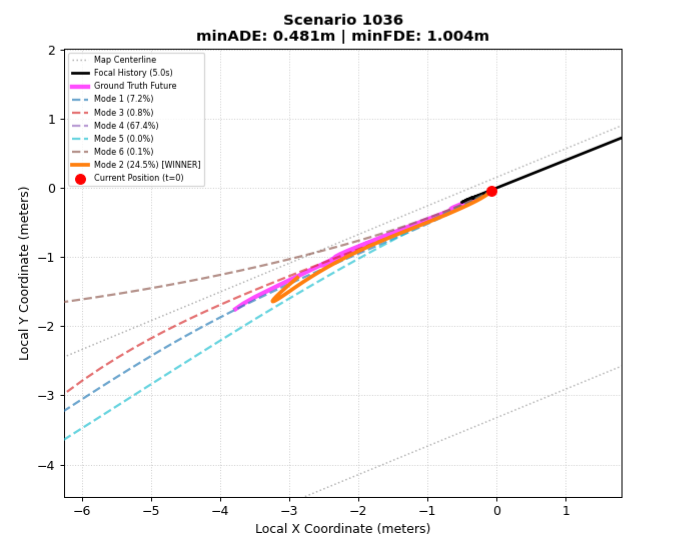

#### 5.3 Pedestrian-Specific Model: Results

##### 5.3.1 Quantitative Results

On the 19,603-scene validation set, the model reaches an ADE of $0.2187\,\text{m}$ and an FDE of $0.5107\,\text{m}$. With a stricter $0.8\,\text{m}$ threshold suited to pedestrian motion, the miss rate is $23.67\%$. These results use a $2.0\,\text{s}$ horizon and are not directly comparable to the vehicle models' $6.0\,\text{s}$ horizon and $2.0\,\text{m}$ threshold (Sections 5.1 and 5.2).

**Pedestrian evaluation setup:** Loads the full pedestrian validation cache and restores `SceneSocialLSTM` from the provided weights (`social_lstm_human.pth`).

In [70]:
# If the preprocessed validation dataset is located elsewhere on your machine/server,
# please update the VAL_CACHE_PATH variable below to point to the correct .pt file.
VAL_CACHE_PATH = Path("val_samples.pt")

if not VAL_CACHE_PATH.exists():
    raise FileNotFoundError(
        f"Validation cache not found at '{VAL_CACHE_PATH}'. "
        "Please update the VAL_CACHE_PATH variable to the correct location."
    )

print(f"Loading Validation Dataset from {VAL_CACHE_PATH}...")
      
# Load using torch.load to match our .pt caching format
val_samples = torch.load(VAL_CACHE_PATH)

val_ds = CachedDataset(val_samples)

print("Loaded successfully!!")

# 1. Recreate the model
model = SceneSocialLSTM(hidden_dim=HIDDEN_DIM, grid_size=GRID_SIZE, radius=RADIUS).to(DEVICE)

# 2. Load the state dictionary into memory first
state_dict = torch.load("social_lstm_human.pth", map_location=DEVICE)

# 3. Filter out any keys that belong to the map_engine buffers
filtered_state_dict = {
    k: v for k, v in state_dict.items() 
    if not k.startswith("map_engine.")
}

# 4. Load the filtered dictionary into the model
model.load_state_dict(filtered_state_dict, strict=False)
model.eval()

print("Loaded model from social_lstm_human.pth (ignoring dynamic map buffers)")

Loading Validation Dataset from val_samples.pt...
Loaded successfully!!
Loaded model from social_lstm_human.pth (ignoring dynamic map buffers)


**Pedestrian quantitative evaluation:** Runs autoregressive inference on the first `VAL_LEN` validation scenes (100 by default, for a quick check) and prints ADE, FDE and miss rate. Set `VAL_LEN = None` to evaluate all 19,603 scenes, which reproduces the metrics reported above.

In [71]:
VAL_LEN = 100

# --- TRACKING METRICS ---
total_ade_sum = 0.0
total_fde_sum = 0.0
total_pedestrians = 0

total_misses = 0
MISS_THRESHOLD = 0.8

# Best/Worst trackers (based on Final Displacement Error)
worst_fde = -1.0
worst_info = {}

best_fde = float('inf')
best_info = {}

if VAL_LEN is not None:
    val_ds_an = val_ds[:VAL_LEN]
else:
    val_ds_an = val_ds

print(f"\nStarting analysis of {len(val_ds_an)} scenes...")
start_time = time.time()

with torch.no_grad():
    for i in tqdm(range(len(val_ds_an)), desc="Analyzing Dataset"):
        sample = val_ds_an[i]
        hist = sample["hist"].to(DEVICE)
        fut = sample["fut"].to(DEVICE)
        scene_id = sample.get("scene_id", f"Unknown_{i}")

        map_tensors = {k: v.to(DEVICE) for k, v in sample["map_tensors"].items()}

        # Inference
        pred = model(hist, map_tensors, fut_seq=fut, teacher_forcing=False)

        # Calculate errors per agent (Shape: A)
        err = torch.norm(pred - fut, dim=-1)
        ade_per_agent = err.mean(dim=-1)
        fde_per_agent = err[:, -1]

        num_agents = hist.shape[0]
        total_ade_sum += ade_per_agent.sum().item()
        total_fde_sum += fde_per_agent.sum().item()
        total_pedestrians += num_agents

        misses_in_scene = (fde_per_agent > MISS_THRESHOLD).sum().item()
        total_misses += misses_in_scene

        # Check for worst individual prediction in this scene
        scene_max_fde, scene_max_idx = fde_per_agent.max(dim=0)
        if scene_max_fde.item() > worst_fde:
            worst_fde = scene_max_fde.item()
            worst_info = {
                "scene_idx": i,
                "scene_id": scene_id,
                "agent_idx": scene_max_idx.item(),
                "fde": worst_fde,
                "ade": ade_per_agent[scene_max_idx].item()
            }

        # Check for best individual prediction in this scene
        scene_min_fde, scene_min_idx = fde_per_agent.min(dim=0)
        if scene_min_fde.item() < best_fde:
            best_fde = scene_min_fde.item()
            best_info = {
                "scene_idx": i,
                "scene_id": scene_id,
                "agent_idx": scene_min_idx.item(),
                "fde": best_fde,
                "ade": ade_per_agent[scene_min_idx].item()
            }

# --- GENERATE REPORT ---
elapsed = time.time() - start_time
global_ade = total_ade_sum / total_pedestrians
global_fde = total_fde_sum / total_pedestrians

global_miss_rate = (total_misses / total_pedestrians) * 100

report = f"""
==================================================
FULL DATASET ANALYSIS REPORT
==================================================
Time taken:       {elapsed / 60:.2f} minutes
Total Scenes:     {len(val_ds_an):,}
Total Agents:     {total_pedestrians:,}

GLOBAL AVERAGES:
Average ADE:      {global_ade:.4f} meters
Average FDE:      {global_fde:.4f} meters
Miss Rate (>0.8m):  {global_miss_rate:.2f}% ({total_misses}/{total_pedestrians} missed)

WORST PREDICTION (Highest FDE):
Scene Index:      {worst_info['scene_idx']}
Scene ID:         {worst_info['scene_id']}
Agent Index:      {worst_info['agent_idx']}
Error (FDE):      {worst_info['fde']:.4f} meters off-target
Error (ADE):      {worst_info['ade']:.4f} meters

BEST PREDICTION (Lowest FDE):
Scene Index:      {best_info['scene_idx']}
Scene ID:         {best_info['scene_id']}
Agent Index:      {best_info['agent_idx']}
Error (FDE):      {best_info['fde']:.4f} meters off-target
Error (ADE):      {best_info['ade']:.4f} meters
==================================================
"""

print(report)


Starting analysis of 100 scenes...


Analyzing Dataset: 100%|██████████████████████████████████████████████████████████████████████████| 100/100 [00:12<00:00,  8.09it/s]


FULL DATASET ANALYSIS REPORT
Time taken:       0.21 minutes
Total Scenes:     100
Total Agents:     636

GLOBAL AVERAGES:
Average ADE:      0.2360 meters
Average FDE:      0.5545 meters
Miss Rate (>0.8m):  24.69% (157/636 missed)

WORST PREDICTION (Highest FDE):
Scene Index:      34
Scene ID:         scenario_008415aa-6a7d-4c51-9b82-f29bc76f7f28.parquet
Agent Index:      5
Error (FDE):      6.3429 meters off-target
Error (ADE):      2.2300 meters

BEST PREDICTION (Lowest FDE):
Scene Index:      96
Scene ID:         scenario_0177f3b7-ded5-4542-b4ce-009cda952dc1.parquet
Agent Index:      0
Error (FDE):      0.0064 meters off-target
Error (ADE):      0.0045 meters



##### 5.3.2 Qualitative Analysis

The plots in this subsection use the following function, which runs inference on one scene, prints the per-pedestrian metrics and draws the scene in bird's-eye view with the map elements, history, ground truth and prediction of every pedestrian. It requires the preprocessed `val_samples.pt` loaded in Section 5.3.1.

**Scene plotting function:** Defines `evaluate_and_plot_scene`, which renders bird's-eye-view plots of the map elements, ground truth and predicted trajectories.

In [72]:
def evaluate_and_plot_scene(model, dataset, scene_idx, target_agent_idx=None, zoom_margin=2.0, save_prefix="scenario", x_limit=None, y_limit=None):
    """
    Runs inference on a single scene, prints ADE/FDE metrics, and generates a BEV plot.
    
    Args:
        model: The trained SceneSocialLSTM model.
        dataset: The validation dataset (e.g., val_ds).
        scene_idx (int): The index of the scene in the dataset.
        target_agent_idx (int, optional): The index of the specific pedestrian to zoom in on. 
                                          If None, plots the entire scene.
        zoom_margin (float): The buffer in meters around the target agent for the plot window.
        save_prefix (str): Prefix for the saved .png and .pdf files to prevent overwriting.
        x_limit (tuple, optional): Explicit (xmin, xmax) bounds for the plot.
        y_limit (tuple, optional): Explicit (ymin, ymax) bounds for the plot.
    """
    # 1. Extract Scene Data
    sample = dataset[scene_idx]
    hist = sample["hist"]
    fut = sample["fut"]
    scene_id = sample["scene_id"]
    agent_ids = sample["agent_ids"]
    map_tensors = sample["map_tensors"]

    num_agents = hist.shape[0]
    print(f"==================================================")
    print(f"Scene ID: {scene_id} | Dataset Index: {scene_idx}")
    print(f"Number of pedestrians: {num_agents}")
    print(f"==================================================")

    # 2. Run Inference
    map_tensors_gpu = {k: v.to(DEVICE) for k, v in map_tensors.items()}
    with torch.no_grad():
        pred = model(
            hist.to(DEVICE),
            map_tensors_gpu, 
            fut_seq=fut.to(DEVICE),   
            teacher_forcing=False     
        ).cpu()

    # 3. Compute Metrics
    loss = scene_loss(pred, fut)
    print(f"Scene Mean Euclidean Distance: {loss.item():.4f} m")
    
    ade = torch.norm(pred - fut, dim=2).mean(dim=1)
    fde = torch.norm(pred[:, -1] - fut[:, -1], dim=1)
    
    print("\n--- Per-Pedestrian Metrics ---")
    for i, (aid, a, f) in enumerate(zip(agent_ids, ade, fde)):
        marker = " <--- TARGET" if i == target_agent_idx else ""
        print(f"Index {i} (ID {aid}): ADE = {a.item():.3f} m | FDE = {f.item():.3f} m{marker}")
        
    print(f"\nOverall Scene ADE: {ade.mean().item():.3f} m")
    print(f"Overall Scene FDE: {fde.mean().item():.3f} m")
    
    # 4. Initialize Plot
    fig, ax = plt.subplots(figsize=(8, 8))

    # 5. Plot Map Features
    if "drive_bounds" in map_tensors and map_tensors["drive_bounds"].numel() > 0:
        drive_b = map_tensors["drive_bounds"].cpu().numpy()
        for i, poly in enumerate(drive_b):
            # Close the polygon visually
            poly_closed = np.vstack([poly, poly[0]])
            ax.plot(poly_closed[:, 0], poly_closed[:, 1], color='cornflowerblue', alpha=0.3, linewidth=1.5,
                    label="Drivable Area" if i == 0 else None)

    if "lane_left_bounds" in map_tensors and map_tensors["lane_left_bounds"].numel() > 0:
        left_b = map_tensors["lane_left_bounds"].cpu().numpy()
        for i, poly in enumerate(left_b):
            ax.plot(poly[:, 0], poly[:, 1], color='gray', linestyle='--', alpha=0.5,
                    label="Lane Boundary" if i == 0 else None)
            
    if "lane_right_bounds" in map_tensors and map_tensors["lane_right_bounds"].numel() > 0:
        right_b = map_tensors["lane_right_bounds"].cpu().numpy()
        for poly in right_b:
            ax.plot(poly[:, 0], poly[:, 1], color='gray', linestyle='--', alpha=0.5)

    if "lane_centerlines" in map_tensors and map_tensors["lane_centerlines"].numel() > 0:
        center_c = map_tensors["lane_centerlines"].cpu().numpy()
        for i, poly in enumerate(center_c):
            ax.plot(poly[:, 0], poly[:, 1], color='lightgray', linestyle='-', alpha=0.4,
                    label="Lane Centerline" if i == 0 else None)

    if "cross_poly" in map_tensors and map_tensors["cross_poly"].numel() > 0:
        cross = map_tensors["cross_poly"].cpu().numpy()
        for i, poly in enumerate(cross):
            poly_closed = np.vstack([poly, poly[0]])
            ax.fill(poly_closed[:, 0], poly_closed[:, 1], color='mediumseagreen', alpha=0.2, 
                    label="Pedestrian Crossing" if i == 0 else None)
            ax.plot(poly_closed[:, 0], poly_closed[:, 1], color='mediumseagreen', alpha=0.5, linewidth=1)

    # 6. Plot Agent Trajectories
    cmap = plt.get_cmap("tab20")
    for i in range(num_agents):
        color = cmap(i % 20) 

        ax.plot(
            hist[i, :, 0].cpu().numpy(),
            hist[i, :, 1].cpu().numpy(),
            "-",
            color=color,
            alpha=0.6,
            label="History" if i == 0 else None
        )

        ax.plot(
            fut[i, :, 0].cpu().numpy(),
            fut[i, :, 1].cpu().numpy(),
            "-x",
            color=color,
            alpha=0.8,
            label="Ground Truth" if i == 0 else None
        )

        ax.plot(
            pred[i, :, 0].cpu().numpy(),
            pred[i, :, 1].cpu().numpy(),
            "-o",
            color=color,
            linewidth=2,
            markersize=3,
            label="Prediction" if i == 0 else None
        )

        ax.plot(
            hist[i, -1, 0].cpu().numpy(),
            hist[i, -1, 1].cpu().numpy(),
            "o",
            color=color,
            markersize=3
        )

    # 7. Apply Zoom & Formatting
    ax.set_aspect("equal", adjustable="box")
    title_str = f"Scene: {scene_id}"
    
    if x_limit is not None and y_limit is not None:
        ax.set_xlim(x_limit)
        ax.set_ylim(y_limit)
        title_str += " | Manual Zoom Window"
    elif target_agent_idx is not None and target_agent_idx < num_agents:
        agent_x = torch.cat([hist[target_agent_idx, :, 0], fut[target_agent_idx, :, 0], pred[target_agent_idx, :, 0]])
        agent_y = torch.cat([hist[target_agent_idx, :, 1], fut[target_agent_idx, :, 1], pred[target_agent_idx, :, 1]])
        ax.set_xlim(agent_x.min().item() - zoom_margin, agent_x.max().item() + zoom_margin)
        ax.set_ylim(agent_y.min().item() - zoom_margin, agent_y.max().item() + zoom_margin)
        title_str += f" | Zoom: Agent {agent_ids[target_agent_idx]}"
        
    ax.set_title(title_str)
    ax.grid(True, linestyle=':', alpha=0.6)
    ax.legend(loc='upper right')

    plt.show()

**Success cases.**
1. **Curved path:** in scene 9022 (pedestrian 10), the prediction follows the curve (ADE 0.239 m, FDE 0.264 m).

**Success case 1:** Plots validation scene 9022, zoomed on pedestrian 10.

In [73]:
# Evaluate Success Case 1 (Curved Path)
evaluate_and_plot_scene(
    model, 
    val_ds, 
    scene_idx=9022, 
    target_agent_idx=10
)

Scene ID: scenario_77f14420-427f-497c-b997-631b09b5d217.parquet | Dataset Index: 9022
Number of pedestrians: 16
Scene Mean Euclidean Distance: 0.3371 m

--- Per-Pedestrian Metrics ---
Index 0 (ID 181192): ADE = 0.067 m | FDE = 0.078 m
Index 1 (ID 181326): ADE = 0.008 m | FDE = 0.015 m
Index 2 (ID 181416): ADE = 0.008 m | FDE = 0.015 m
Index 3 (ID 181440): ADE = 0.019 m | FDE = 0.022 m
Index 4 (ID 181510): ADE = 1.231 m | FDE = 2.841 m
Index 5 (ID 181553): ADE = 0.008 m | FDE = 0.015 m
Index 6 (ID 181567): ADE = 0.009 m | FDE = 0.017 m
Index 7 (ID 181592): ADE = 0.008 m | FDE = 0.015 m
Index 8 (ID 181595): ADE = 0.329 m | FDE = 0.625 m
Index 9 (ID 181618): ADE = 0.480 m | FDE = 0.952 m
Index 10 (ID 181629): ADE = 0.239 m | FDE = 0.264 m <--- TARGET
Index 11 (ID 181633): ADE = 2.481 m | FDE = 5.861 m
Index 12 (ID 181678): ADE = 0.158 m | FDE = 0.812 m
Index 13 (ID 181681): ADE = 0.317 m | FDE = 1.079 m
Index 14 (ID 181705): ADE = 0.025 m | FDE = 0.239 m
Index 15 (ID 181717): ADE = 0.008 

Canvas(toolbar=Toolbar(toolitems=[('Home', 'Reset original view', 'home', 'home'), ('Back', 'Back to previous …

2. **Straight walk:** on linear trajectories, the autoregressive decoder does not drift (scene 18601, ADE 0.051 m, FDE 0.141 m).

**Success case 2:** Plots validation scene 18601, zoomed on pedestrian 0.

In [74]:
# Evaluate Success Case 2 (Straight Walk)
evaluate_and_plot_scene(
    model, 
    val_ds, 
    scene_idx=18601, 
    target_agent_idx=0
)

Scene ID: scenario_f2996d9b-54ec-444f-ab1d-94f95ce73903.parquet | Dataset Index: 18601
Number of pedestrians: 3
Scene Mean Euclidean Distance: 0.0558 m

--- Per-Pedestrian Metrics ---
Index 0 (ID 62528): ADE = 0.051 m | FDE = 0.141 m <--- TARGET
Index 1 (ID 62670): ADE = 0.042 m | FDE = 0.065 m
Index 2 (ID 62791): ADE = 0.074 m | FDE = 0.052 m

Overall Scene ADE: 0.056 m
Overall Scene FDE: 0.086 m


Canvas(toolbar=Toolbar(toolitems=[('Home', 'Reset original view', 'home', 'home'), ('Back', 'Back to previous …

3. **Pedestrian crossing:** the ray-cast point-in-polygon crossing features keep the prediction inside the crosswalk (scene 3492, ADE 0.032 m, FDE 0.124 m).

**Success case 3:** Plots validation scene 3492, zoomed on pedestrian 2.

In [75]:
# Evaluate Success Case 3 (Pedestrian Crossing)
evaluate_and_plot_scene(
    model, 
    val_ds, 
    scene_idx=3492, 
    target_agent_idx=2
)

Scene ID: scenario_2f4dd018-c54f-4a1d-a3e4-cbb8f5fe93bc.parquet | Dataset Index: 3492
Number of pedestrians: 4
Scene Mean Euclidean Distance: 0.0139 m

--- Per-Pedestrian Metrics ---
Index 0 (ID 151031): ADE = 0.008 m | FDE = 0.015 m
Index 1 (ID 151145): ADE = 0.008 m | FDE = 0.015 m
Index 2 (ID 151165): ADE = 0.032 m | FDE = 0.124 m <--- TARGET
Index 3 (ID 151251): ADE = 0.008 m | FDE = 0.015 m

Overall Scene ADE: 0.014 m
Overall Scene FDE: 0.042 m


Canvas(toolbar=Toolbar(toolitems=[('Home', 'Reset original view', 'home', 'home'), ('Back', 'Back to previous …

**Failure cases and data quality limits.**

1. **Diluted map features:** mean pooling can blur important boundaries such as crosswalk edges, so social repulsion dominates and pushes the pedestrian onto a parallel path instead of crossing (scene 13818, ADE 0.609 m, FDE 1.418 m). Max pooling is a possible alternative.

**Failure case 1:** Plots validation scene 13818, zoomed on pedestrian 8.

In [76]:
# Evaluate Failure Case 1 (Rigid Social Repulsion / Diluted Map)
evaluate_and_plot_scene(
    model, 
    val_ds, 
    scene_idx=13818, 
    target_agent_idx=8
)

Scene ID: scenario_b4d49923-00e1-4764-8d4d-017fd694c2a4.parquet | Dataset Index: 13818
Number of pedestrians: 10
Scene Mean Euclidean Distance: 0.2309 m

--- Per-Pedestrian Metrics ---
Index 0 (ID 36477): ADE = 0.008 m | FDE = 0.015 m
Index 1 (ID 36484): ADE = 0.840 m | FDE = 2.057 m
Index 2 (ID 36491): ADE = 0.594 m | FDE = 1.344 m
Index 3 (ID 36497): ADE = 0.008 m | FDE = 0.015 m
Index 4 (ID 36506): ADE = 0.034 m | FDE = 0.147 m
Index 5 (ID 36520): ADE = 0.177 m | FDE = 0.574 m
Index 6 (ID 36523): ADE = 0.007 m | FDE = 0.014 m
Index 7 (ID 36524): ADE = 0.025 m | FDE = 0.034 m
Index 8 (ID 36526): ADE = 0.609 m | FDE = 1.418 m <--- TARGET
Index 9 (ID 36550): ADE = 0.008 m | FDE = 0.015 m

Overall Scene ADE: 0.231 m
Overall Scene FDE: 0.563 m


Canvas(toolbar=Toolbar(toolitems=[('Home', 'Reset original view', 'home', 'home'), ('Back', 'Back to previous …

2. **Static-looking history:** missing history frames are filled by position holding, so a moving pedestrian appears stationary and the model predicts that it stays in place (scene 1481, ADE 1.455 m, FDE 2.885 m).

**Failure case 2:** Plots validation scene 1481, zoomed on pedestrian 12.

In [77]:
# Evaluate Failure Case 2 (Static-Looking History)
evaluate_and_plot_scene(
    model, 
    val_ds, 
    scene_idx=1481, 
    target_agent_idx=12
)

Scene ID: scenario_14a80078-a832-4f16-bb5c-0d21aa05ceb2.parquet | Dataset Index: 1481
Number of pedestrians: 18
Scene Mean Euclidean Distance: 0.2889 m

--- Per-Pedestrian Metrics ---
Index 0 (ID 219117): ADE = 0.018 m | FDE = 0.022 m
Index 1 (ID 219235): ADE = 0.008 m | FDE = 0.015 m
Index 2 (ID 219272): ADE = 0.008 m | FDE = 0.015 m
Index 3 (ID 219331): ADE = 0.096 m | FDE = 0.152 m
Index 4 (ID 219363): ADE = 1.178 m | FDE = 2.937 m
Index 5 (ID 219369): ADE = 0.008 m | FDE = 0.015 m
Index 6 (ID 219373): ADE = 0.008 m | FDE = 0.015 m
Index 7 (ID 219378): ADE = 0.008 m | FDE = 0.015 m
Index 8 (ID 219387): ADE = 0.008 m | FDE = 0.015 m
Index 9 (ID 219392): ADE = 0.318 m | FDE = 0.779 m
Index 10 (ID 219397): ADE = 0.444 m | FDE = 1.655 m
Index 11 (ID 219411): ADE = 1.074 m | FDE = 2.079 m
Index 12 (ID 219413): ADE = 1.455 m | FDE = 2.885 m <--- TARGET
Index 13 (ID 219419): ADE = 0.313 m | FDE = 0.424 m
Index 14 (ID 219423): ADE = 0.227 m | FDE = 0.926 m
Index 15 (ID 219429): ADE = 0.016 

Canvas(toolbar=Toolbar(toolitems=[('Home', 'Reset original view', 'home', 'home'), ('Back', 'Back to previous …

3. **Noisy trajectories:** tracking jitter in the raw data produces seemingly random motion without a learnable pattern. In scene 5709, the metrics are very low (ADE 0.013 m, FDE 0.000 m) only because the pedestrian barely moves, which shows that distance-based metrics say little about near-stationary tracks dominated by sensor noise.

**Failure case 3:** Plots validation scene 5709 with explicit axis limits around pedestrian 2.

In [78]:
# Evaluate Failure Case 3 (Noisy Trajectories)
evaluate_and_plot_scene(
    model, 
    val_ds, 
    scene_idx=5709, 
    target_agent_idx=2,
    x_limit=(1396.375, 1396.625),
    y_limit=(196.5, 196.25)
)

Scene ID: scenario_4b548dd5-dc32-431f-a99a-84de5238e3c6.parquet | Dataset Index: 5709
Number of pedestrians: 21
Scene Mean Euclidean Distance: 0.1476 m

--- Per-Pedestrian Metrics ---
Index 0 (ID 126460): ADE = 0.716 m | FDE = 1.665 m
Index 1 (ID 126721): ADE = 0.027 m | FDE = 0.039 m
Index 2 (ID 126811): ADE = 0.013 m | FDE = 0.000 m <--- TARGET
Index 3 (ID 126873): ADE = 0.046 m | FDE = 0.071 m
Index 4 (ID 126999): ADE = 0.290 m | FDE = 0.575 m
Index 5 (ID 127017): ADE = 0.159 m | FDE = 0.187 m
Index 6 (ID 127022): ADE = 0.304 m | FDE = 0.422 m
Index 7 (ID 127033): ADE = 0.008 m | FDE = 0.015 m
Index 8 (ID 127039): ADE = 0.010 m | FDE = 0.026 m
Index 9 (ID 127042): ADE = 0.008 m | FDE = 0.015 m
Index 10 (ID 127045): ADE = 0.287 m | FDE = 0.387 m
Index 11 (ID 127051): ADE = 0.071 m | FDE = 0.164 m
Index 12 (ID 127066): ADE = 1.010 m | FDE = 2.213 m
Index 13 (ID 127071): ADE = 0.061 m | FDE = 0.115 m
Index 14 (ID 127078): ADE = 0.028 m | FDE = 0.152 m
Index 15 (ID 127081): ADE = 0.011 

Canvas(toolbar=Toolbar(toolitems=[('Home', 'Reset original view', 'home', 'home'), ('Back', 'Back to previous …

##### 5.3.3 Interactive Exploration

The final cell plots any scene or pedestrian, chosen manually or at random.

**Interactive exploration:** Evaluates and plots a selected or randomly sampled validation scene.

In [79]:
import random

# Toggle these flags to True to randomly sample the validation set
RANDOM_SCENE = True
RANDOM_TARGET = True  # Set to True to automatically zoom in on a random pedestrian

# Manually specify indices (these are ignored if the respective RANDOM flag is True)
MANUAL_SCENE_IDX = 0
MANUAL_TARGET_IDX = None  # Use an integer (e.g., 0) to zoom, or None for a full scene view

# 1. Determine Scene Index
if RANDOM_SCENE:
    scene_to_plot = random.randrange(len(val_ds))
else:
    scene_to_plot = MANUAL_SCENE_IDX

# 2. Determine Target Agent Index
if RANDOM_TARGET:
    num_agents_in_scene = len(val_ds[scene_to_plot]["agent_ids"])
    target_to_plot = random.randrange(num_agents_in_scene)
else:
    target_to_plot = MANUAL_TARGET_IDX

# 3. Evaluate and Plot
evaluate_and_plot_scene(
    model=model, 
    dataset=val_ds, 
    scene_idx=scene_to_plot, 
    target_agent_idx=target_to_plot, 
    zoom_margin=5.0,  # A slightly wider margin for general exploration
)

Scene ID: scenario_6194fec5-e1f5-435f-b887-bbf762228479.parquet | Dataset Index: 7394
Number of pedestrians: 9
Scene Mean Euclidean Distance: 0.4603 m

--- Per-Pedestrian Metrics ---
Index 0 (ID 40816): ADE = 0.530 m | FDE = 1.359 m
Index 1 (ID 40871): ADE = 0.296 m | FDE = 0.842 m
Index 2 (ID 40956): ADE = 0.390 m | FDE = 0.964 m
Index 3 (ID 40996): ADE = 1.289 m | FDE = 3.709 m
Index 4 (ID 41000): ADE = 0.008 m | FDE = 0.015 m
Index 5 (ID 41031): ADE = 1.135 m | FDE = 2.163 m
Index 6 (ID 41033): ADE = 0.417 m | FDE = 1.212 m <--- TARGET
Index 7 (ID 41038): ADE = 0.070 m | FDE = 0.286 m
Index 8 (ID 41045): ADE = 0.008 m | FDE = 0.015 m

Overall Scene ADE: 0.460 m
Overall Scene FDE: 1.174 m


Canvas(toolbar=Toolbar(toolitems=[('Home', 'Reset original view', 'home', 'home'), ('Back', 'Back to previous …

#### 5.4 Combined Multi-Agent Scene Visualization

To show both models working together, the cell below applies them to one validation scene that contains both vehicles and pedestrians. The Map-Aware model predicts the focal vehicle's 6 s future (highest-confidence mode, as deployed), and the pedestrian model predicts all pedestrians active at $t = 5\,\text{s}$ over its 2 s horizon. Neighboring vehicles are shown with their ground truth. The animation shows the 5 s history, followed by the forecast unfolding next to the ground truth.

**Scene animation:** Loads scenario `aa72b05f…` from `Datasets/val/`, runs both models with the provided weights (`Map_aware_output/multimodal_social_map_aware_V4.pt`, `social_lstm_human.pth`) and saves a 110-frame animation (11 s at 10 Hz) as `unified_scene_prediction.mp4` (or a `.gif` if `ffmpeg` is unavailable), which is displayed below the cell.

Selected scenario: aa72b05f-749f-4f3b-bc92-0625d9103053
Loading trained models...
Running pedestrian forecasting...
Running focal-vehicle forecasting...
Encoding animation (110 frames): 3 pedestrians, 1 focal vehicle, 19 neighbor vehicles...
Saved to unified_scene_prediction.gif


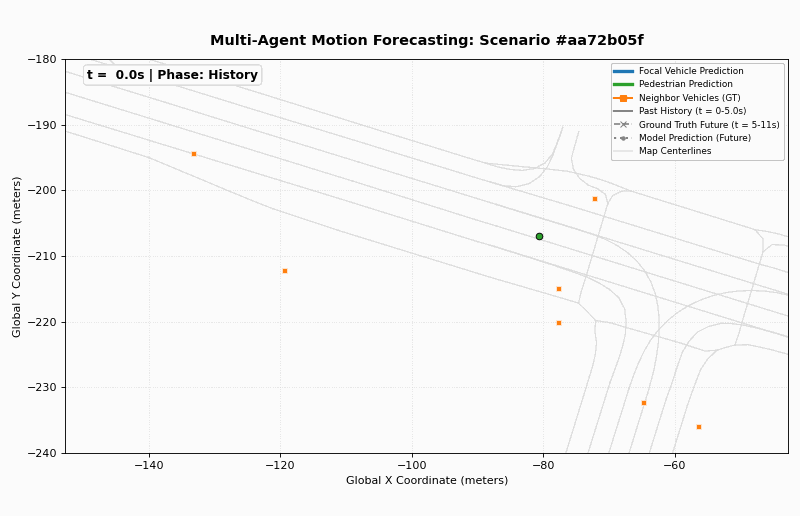

In [82]:
# Combined multi-agent scene animation: Map-Aware model (focal vehicle, Top-1 mode)
# and pedestrian Map-Aware Social-LSTM (all active pedestrians) on one validation scene.
import json
from pathlib import Path

import matplotlib.animation as animation
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
import numpy as np
import pandas as pd
import torch
from IPython.display import Video, Image, display

# ---------------------------------------------------------
# 1. Configuration & scenario lookup
# ---------------------------------------------------------
PARTIAL_ID = "aa72b05f"                    # first 8 characters of the scenario ID
MANUAL_YLIM = (-240.0, -180.0)             # view limits chosen for this scenario
VEH_CKPT = "Map_aware_output/multimodal_social_map_aware_V4.pt"
PED_CKPT = "social_lstm_human.pth"
OUTPUT_VIDEO = "unified_scene_prediction.mp4"

def _find_datasets_root():
    current_dir = Path.cwd()
    for d in [current_dir, *current_dir.parents]:
        if (d / "Datasets").exists():
            return d / "Datasets"
    raise FileNotFoundError("Could not locate the 'Datasets' folder (see Dependencies & Setup).")

VAL_DIR = _find_datasets_root() / "val"

scenario_dir = next((d for d in sorted(VAL_DIR.iterdir())
                     if d.is_dir() and d.name.startswith(PARTIAL_ID)), None)
use_manual_view = scenario_dir is not None

if scenario_dir is None:
    # Fallback: first scenario that contains pedestrians
    print(f"Scenario '{PARTIAL_ID}' not found; searching for a scene with pedestrians...")
    for d in sorted(VAL_DIR.iterdir()):
        p = d / f"scenario_{d.name}.parquet"
        if d.is_dir() and p.exists() and (pd.read_parquet(p)["object_type"] == "pedestrian").any():
            scenario_dir = d
            break
if scenario_dir is None:
    raise FileNotFoundError(f"No suitable scenario found in {VAL_DIR}.")

SCENARIO_ID = scenario_dir.name
scene_df = pd.read_parquet(scenario_dir / f"scenario_{SCENARIO_ID}.parquet")
with open(scenario_dir / f"log_map_archive_{SCENARIO_ID}.json", "r") as f:
    map_data = json.load(f)
print(f"Selected scenario: {SCENARIO_ID}")

# ---------------------------------------------------------
# 2. Load both trained models (classes defined in Sections 3.4 and 3.5)
# ---------------------------------------------------------
print("Loading trained models...")
ped_model = SceneSocialLSTM(hidden_dim=HIDDEN_DIM, grid_size=GRID_SIZE, radius=RADIUS).to(DEVICE)
ped_state = torch.load(PED_CKPT, map_location=DEVICE)
ped_model.load_state_dict({k: v for k, v in ped_state.items()
                           if not k.startswith("map_engine.")}, strict=False)
ped_model.eval()

veh_model = MapAwareMultimodalTrajectoryPredictor(
    input_dim=2, hidden_dim=128, num_heads=4, num_modes=6, prediction_steps=60
).to(DEVICE)
veh_ckpt = torch.load(VEH_CKPT, map_location=DEVICE, weights_only=False)
veh_model.load_state_dict(veh_ckpt["model_state_dict"]
                          if isinstance(veh_ckpt, dict) and "model_state_dict" in veh_ckpt
                          else veh_ckpt)
veh_model.eval()

# ---------------------------------------------------------
# 3. Helper functions for trajectory & map extraction
# ---------------------------------------------------------
def extract_full_track(track_df, target_len=110):
    """Continuous 110-step coordinates with position-holding padding."""
    time_col = "timestep" if "timestep" in track_df.columns else "timestamp"
    track_df = track_df.sort_values(by=time_col)
    t_vals = track_df[time_col].values.astype(int)
    c_vals = track_df[["position_x", "position_y"]].values.astype(np.float32)

    full_coords = np.zeros((target_len, 2), dtype=np.float32)
    valid_t = t_vals[t_vals < target_len]
    valid_c = c_vals[: len(valid_t)]
    if len(valid_t) == 0:
        return full_coords, False

    full_coords[valid_t] = valid_c
    if valid_t.min() > 0:
        full_coords[: valid_t.min()] = valid_c[0]
    if valid_t.max() < target_len - 1:
        full_coords[valid_t.max() + 1:] = valid_c[-1]
    return full_coords, 49 in valid_t   # active at the present (t = 49)

def extract_lanes_for_anchor(map_data, origin_anchor, max_lanes=16, points_per_lane=10):
    """16 nearest lane centerlines, resampled to 10 points, relative to the anchor."""
    lane_tensor = np.zeros((max_lanes, points_per_lane, 2), dtype=np.float32)
    lane_mask = np.zeros((max_lanes,), dtype=bool)
    raw_lanes = []
    for lane_info in map_data.get("lane_segments", {}).values():
        pts = lane_info.get("centerline", [])
        coords = [[pt["x"], pt["y"]] if isinstance(pt, dict) else pt[:2] for pt in pts]
        if len(coords) >= 2:
            raw_lanes.append(np.array(coords, dtype=np.float32))
    if not raw_lanes:
        return lane_tensor, lane_mask

    order = sorted(range(len(raw_lanes)),
                   key=lambda i: np.min(np.linalg.norm(raw_lanes[i] - origin_anchor, axis=1)))
    for slot, idx in enumerate(order[:max_lanes]):
        lane = raw_lanes[idx]
        alphas, orig = np.linspace(0, 1, points_per_lane), np.linspace(0, 1, len(lane))
        lane_tensor[slot] = np.stack([np.interp(alphas, orig, lane[:, 0]),
                                      np.interp(alphas, orig, lane[:, 1])], axis=1) - origin_anchor
        lane_mask[slot] = True
    return lane_tensor, lane_mask

# ---------------------------------------------------------
# 4. Pedestrians (pedestrian Map-Aware Social-LSTM)
# ---------------------------------------------------------
print("Running pedestrian forecasting...")
ped_data_list, agent_hist_for_model = [], []
map_tensors_gpu = {k: v.to(DEVICE) for k, v in prepare_map_tensors(map_data).items()}

for tid in scene_df.loc[scene_df["object_type"] == "pedestrian", "track_id"].unique():
    full_coords, active_at_49 = extract_full_track(scene_df[scene_df["track_id"] == tid])
    if not active_at_49:
        continue
    agent_hist_for_model.append(full_coords[30:50])          # 20-frame history
    ped_data_list.append({"track_id": tid, "gt_full": full_coords,
                          "gt_hist": full_coords[:50], "gt_fut": full_coords[50:]})

if agent_hist_for_model:
    ped_tensor = torch.tensor(np.stack(agent_hist_for_model), dtype=torch.float32).to(DEVICE)
    with torch.no_grad():
        ped_preds = ped_model(ped_tensor, map_tensors_gpu, fut_seq=None,
                              teacher_forcing=False).cpu().numpy()   # (N, 20, 2), absolute
    for i, p in enumerate(ped_data_list):
        p["pred"] = ped_preds[i]

# ---------------------------------------------------------
# 5. Focal vehicle (Map-Aware Social MHA, Top-1 mode)
# ---------------------------------------------------------
print("Running focal-vehicle forecasting...")
non_ped_ids = scene_df.loc[scene_df["object_type"] != "pedestrian", "track_id"].unique()
all_tracks_dict, active_veh_ids = {}, []
for tid in non_ped_ids:
    full_coords, active_at_49 = extract_full_track(scene_df[scene_df["track_id"] == tid])
    all_tracks_dict[tid] = full_coords
    if active_at_49:
        active_veh_ids.append(tid)

focal_col = "object_category" if "object_category" in scene_df.columns else "track_category"
focal_row = scene_df[scene_df[focal_col] == 3]
selected_veh_ids, focal_anchor = [], None
if not focal_row.empty and focal_row.iloc[0]["track_id"] in active_veh_ids:
    selected_veh_ids = [focal_row.iloc[0]["track_id"]]
elif active_veh_ids:
    selected_veh_ids = [active_veh_ids[0]]              # fallback if no focal label
if selected_veh_ids:
    focal_anchor = all_tracks_dict[selected_veh_ids[0]][49]

veh_data_list, bg_veh_data_list = [], []
for tid in active_veh_ids:
    coords = all_tracks_dict[tid]
    if tid not in selected_veh_ids:
        bg_veh_data_list.append({"track_id": tid, "gt_full": coords})
        continue

    anchor = coords[49].copy()
    local_coords = coords - anchor
    f_hist_disp = np.zeros_like(local_coords[:50])
    f_hist_disp[1:] = np.diff(local_coords[:50], axis=0)
    f_hist_disp[0] = local_coords[0]

    cand = sorted(((np.mean(np.linalg.norm(o[:50] - coords[:50], axis=1)), o[:50] - anchor)
                   for oid, o in all_tracks_dict.items() if oid != tid), key=lambda x: x[0])
    neighbor_tracks = np.zeros((10, 50, 2), dtype=np.float32)
    for n_i in range(min(10, len(cand))):
        neighbor_tracks[n_i] = cand[n_i][1]
    neighbor_mask = np.any(neighbor_tracks != 0.0, axis=(1, 2))
    lane_tensor, lane_mask = extract_lanes_for_anchor(map_data, anchor)

    to_t = lambda a, dt: torch.tensor(a, dtype=dt).unsqueeze(0).to(DEVICE)
    with torch.no_grad():
        pred_disps, conf = veh_model(to_t(f_hist_disp, torch.float32),
                                     to_t(neighbor_tracks, torch.float32),
                                     to_t(neighbor_mask, torch.bool),
                                     to_t(lane_tensor, torch.float32),
                                     to_t(lane_mask, torch.bool))
    best_mode = torch.argmax(conf, dim=1)[0].item()             # highest-confidence mode
    pred_abs = torch.cumsum(pred_disps[0, best_mode], dim=0).cpu().numpy() + anchor

    veh_data_list.append({"track_id": tid, "gt_full": coords, "gt_hist": coords[:50],
                          "gt_fut": coords[50:], "pred": pred_abs})

# ---------------------------------------------------------
# 6. Canvas setup
# ---------------------------------------------------------
plt.ioff()   # build the figure off-screen: no empty interactive canvas in the output
fig, ax = plt.subplots(figsize=(10, 10), dpi=150)
ax.set_facecolor("#fafafa")
ax.set_aspect("equal")
ax.grid(True, linestyle=":", alpha=0.5, color="#bfbfbf")

for lane in map_data.get("lane_segments", {}).values():
    pts = lane.get("centerline", [])
    if pts:
        ax.plot([p["x"] for p in pts], [p["y"] for p in pts],
                color="#dcdcdc", linewidth=1.2, zorder=1)

zone_pts = [a["gt_full"][30:80] for a in ped_data_list + veh_data_list]
if zone_pts:
    pts = np.vstack(zone_pts)
    center_x, center_y = (pts[:, 0].min() + pts[:, 0].max()) / 2, (pts[:, 1].min() + pts[:, 1].max()) / 2
    span = max(np.ptp(pts[:, 0]), np.ptp(pts[:, 1]))
    half_span = max(min(span / 2.0 + 15.0, 55.0), 35.0)
elif focal_anchor is not None:
    (center_x, center_y), half_span = focal_anchor, 45.0
else:
    center_x, center_y, half_span = 0.0, 0.0, 45.0
ax.set_xlim(center_x - half_span, center_x + half_span)
ax.set_ylim(center_y - half_span, center_y + half_span)
if use_manual_view:
    ax.set_ylim(*MANUAL_YLIM)

# Fit the figure to the visible area so no blank bands appear above/below the plot
x0, x1 = ax.get_xlim()
y0, y1 = ax.get_ylim()
fig.set_size_inches(10, 10 * (y1 - y0) / (x1 - x0) + 1.0)

ax.set_title(f"Multi-Agent Motion Forecasting: Scenario #{SCENARIO_ID[:8]}",
             fontsize=13, fontweight="bold", pad=12)
ax.set_xlabel("Global X Coordinate (meters)", fontsize=10)
ax.set_ylabel("Global Y Coordinate (meters)", fontsize=10)

COLOR_PED, COLOR_VEH, COLOR_BG_VEH = "#2ca02c", "#1f77b4", "#ff7f0e"

def make_agent_artists(color, head_marker):
    return {
        "hist": ax.plot([], [], color=color, linestyle="-", linewidth=2.0, zorder=3)[0],
        "gt": ax.plot([], [], color=color, linestyle="--", marker="x", markersize=4,
                      markevery=3, linewidth=1.5, alpha=0.8, zorder=2)[0],
        "pred": ax.plot([], [], color=color, linestyle=":", marker=".", markersize=5,
                        markevery=2, linewidth=2.0, zorder=4)[0],
        "head": ax.plot([], [], marker=head_marker, color=color, markersize=6,
                        markeredgecolor="black", markeredgewidth=0.8, zorder=6)[0],
    }

ped_artists = [make_agent_artists(COLOR_PED, "o") for _ in ped_data_list]
veh_artists = [make_agent_artists(COLOR_VEH, "s") for _ in veh_data_list]
bg_veh_artists = [{
    "line": ax.plot([], [], color=COLOR_BG_VEH, linestyle="-", linewidth=1.5, alpha=0.6, zorder=2)[0],
    "head": ax.plot([], [], marker="s", color=COLOR_BG_VEH, markersize=4.5,
                    markeredgecolor="white", markeredgewidth=0.5, zorder=5)[0],
} for _ in bg_veh_data_list]

ax.legend(handles=[
    Line2D([0], [0], color=COLOR_VEH, lw=3, label="Focal Vehicle Prediction"),
    Line2D([0], [0], color=COLOR_PED, lw=3, label="Pedestrian Prediction"),
    Line2D([0], [0], color=COLOR_BG_VEH, lw=2, marker="s", label="Neighbor Vehicles (GT)"),
    Line2D([0], [0], color="gray", lw=2.0, linestyle="-", label="Past History (t = 0-5.0s)"),
    Line2D([0], [0], color="gray", lw=1.5, linestyle="--", marker="x", markersize=5,
           label="Ground Truth Future (t = 5-11s)"),
    Line2D([0], [0], color="gray", lw=2.0, linestyle=":", marker=".", markersize=6,
           label="Model Prediction (Future)"),
    Line2D([0], [0], color="#dcdcdc", lw=1.5, label="Map Centerlines"),
], loc="upper right", framealpha=0.92, fontsize=8, edgecolor="#bfbfbf")

time_text = ax.text(0.03, 0.95, "", transform=ax.transAxes, fontsize=11, fontweight="bold",
                    bbox=dict(boxstyle="round,pad=0.3", fc="white", ec="#cccccc", alpha=0.85))

fig.tight_layout()

# ---------------------------------------------------------
# 7. Animation
# ---------------------------------------------------------
def update_agent(art, a, frame):
    if frame < 50:
        art["hist"].set_data(a["gt_hist"][: frame + 1, 0], a["gt_hist"][: frame + 1, 1])
        art["gt"].set_data([], [])
        art["pred"].set_data([], [])
        art["head"].set_data([a["gt_hist"][frame, 0]], [a["gt_hist"][frame, 1]])
    else:
        step = frame - 50
        art["hist"].set_data(a["gt_hist"][:, 0], a["gt_hist"][:, 1])
        art["gt"].set_data(a["gt_fut"][: step + 1, 0], a["gt_fut"][: step + 1, 1])
        if "pred" in a:   # prediction unfolds up to its horizon (20 steps ped., 60 veh.)
            art["pred"].set_data(a["pred"][: step + 1, 0], a["pred"][: step + 1, 1])
        art["head"].set_data([a["gt_fut"][step, 0]], [a["gt_fut"][step, 1]])

def animate(frame):
    phase = "History" if frame < 50 else "Forecasting"
    time_text.set_text(f"t = {frame * 0.1:4.1f}s | Phase: {phase}")
    for art, p in zip(ped_artists, ped_data_list):
        update_agent(art, p, frame)
    for art, v in zip(veh_artists, veh_data_list):
        update_agent(art, v, frame)
    for art, bg in zip(bg_veh_artists, bg_veh_data_list):
        art["line"].set_data(bg["gt_full"][: frame + 1, 0], bg["gt_full"][: frame + 1, 1])
        art["head"].set_data([bg["gt_full"][frame, 0]], [bg["gt_full"][frame, 1]])
    return []

print(f"Encoding animation (110 frames): {len(ped_data_list)} pedestrians, "
      f"{len(veh_data_list)} focal vehicle, {len(bg_veh_data_list)} neighbor vehicles...")
anim = animation.FuncAnimation(fig, animate, frames=110, interval=100)

if animation.writers.is_available("ffmpeg"):
    anim.save(OUTPUT_VIDEO, writer="ffmpeg", fps=10, extra_args=["-vcodec", "libx264"])
    saved_path = OUTPUT_VIDEO
else:
    saved_path = OUTPUT_VIDEO.replace(".mp4", ".gif")
    anim.save(saved_path, writer=animation.PillowWriter(fps=10), dpi=80)

plt.close(fig)
plt.ion()    # restore interactive mode for any later plots
print(f"Saved to {saved_path}")
display(Video(saved_path, width=700) if saved_path.endswith(".mp4") else Image(filename=saved_path))

### 6. Conclusion

This work developed two motion forecasting models on Argoverse 2: a staged, agent-agnostic model progressing from physics baselines to a map-aware multimodal architecture, and a pedestrian-specific Map-Aware Social-LSTM, reflecting the different motion characteristics of the two agent classes.

For the agent-agnostic model, each architectural addition reduced error. ADE fell from 4.56 m (constant velocity) to 2.305 m (single-agent LSTM), to a minADE₆ of 1.4854 m with social interaction and multimodal output, and to 0.8966 m with map context, while the miss rate dropped from 83% to 43.03%. These figures mix single-path and best-of-6 results and different observation windows (Section 4.2). Map context gave the largest relative ADE reduction (39.6%), consistent with lane geometry strongly constraining vehicle trajectories. Under deployment-oriented Top-1 selection, the highest-confidence mode matched the most accurate one in only 59.30% of scenarios, costing about 0.77 m ADE and 1.96 m FDE. Generating an accurate trajectory and ranking it first are therefore distinct capabilities, and both matter for real-world use.

The pedestrian model, which encodes social context via grid-based pooling and map context via 46 hand-crafted geometric features, achieved sub-meter accuracy (0.2187 m ADE, 0.5107 m FDE) on over 132,000 pedestrians over a 2 s horizon. Its performance is limited less by the architecture than by map feature fidelity, as mean pooling blurs sharp boundaries such as crosswalk edges, and by tracking quality, as missing or noisy history degrades predictions.

Overall, the results support the hypothesis that richer social and especially map context systematically improves trajectory prediction. They also reveal two broader limitations: multimodal models trained with oracle-style objectives need explicit mode ranking and calibration to be reliable in deployment, and hand-crafted context features cap performance as models mature. These findings motivate the future work in Section 7.

### 7. Future Work

The two models provide a solid foundation, but several directions remain open to move this work toward the state of the art.

**Transformer-based architectures.** The most immediate step is replacing recurrent, social-pooling models with transformer-based architectures such as HiVT [[15]](https://openaccess.thecvf.com/content/CVPR2022/html/Zhou_HiVT_Hierarchical_Vector_Transformer_for_Multi-Agent_Motion_Prediction_CVPR_2022_paper.html) and QCNet [[16]](https://openaccess.thecvf.com/content/CVPR2023/papers/Zhou_Query-Centric_Trajectory_Prediction_CVPR_2023_paper.pdf). Their vectorized scene representations, hierarchical or query-centric attention and learned mode queries capture long-range agent–map interactions more effectively and are expected to improve both best-of-K accuracy and mode ranking.

**Calibration-aware evaluation and training.** Given the Oracle–Top-1 gap found in this work, evaluation should include calibration-sensitive metrics such as brier-minFDE [[1]](https://arxiv.org/abs/2301.00493) and reliability analyses of the confidence head. Training should be adapted to close the gap, for example by aligning mode-selection criteria between training and evaluation.

**Scenario- and horizon-level analysis.** Breaking down performance by context, such as dense intersections, highway merges and roundabouts, would reveal failure modes hidden by aggregate scores. This should be combined with an analysis of error accumulation over the 6 s horizon, including whether map-conditioned attention behaves differently at short and long horizons, and with a closer study of the failure categories left open in Sections 5.2.3 and 5.2.4 (map–social conflict, topological ambiguity, negative social transfer).

**Unified architecture.** Combining the pedestrian model's dual-branch design with the agent-agnostic model's multimodal decoding would test whether a shared backbone with agent-type conditioning outperforms separate architectures.

**Further experiments.** Other extensions include:
- comparing later refinement checkpoints of the Map-Aware model (Section 3.4.4) with the reported V4 checkpoint
- testing cross-dataset generalization on nuScenes [[17]](https://openaccess.thecvf.com/content_CVPR_2020/html/Caesar_nuScenes_A_Multimodal_Dataset_for_Autonomous_Driving_CVPR_2020_paper.html) and the Waymo Open Motion Dataset [[18]](https://openaccess.thecvf.com/content/ICCV2021/html/Ettinger_Large_Scale_Interactive_Motion_Forecasting_for_Autonomous_Driving_The_Waymo_ICCV_2021_paper.html)
- evaluating inference latency, since deployed prediction must fit within the planning module's latency budget

#### References

| # | Year | Authors | Title |
|---|------|---------|-------|
| 1 | 2021 | Wilson et al. | [Argoverse 2: Next Generation Datasets for Self-Driving Perception and Forecasting](https://arxiv.org/abs/2301.00493) |
| 2 | 2020 | Rudenko et al. | [Human Motion Trajectory Prediction: A Survey](https://arxiv.org/abs/1905.06113) |
| 3 | 2017 | Altché & de La Fortelle | [An LSTM Network for Highway Trajectory Prediction](https://arxiv.org/abs/1801.07962) |
| 4 | 2019 | Dai, Li & Li | [Modeling Vehicle Interactions via Modified LSTM Models for Trajectory Prediction](https://ieeexplore.ieee.org/document/8672889) |
| 5 | 2018 | Deo & Trivedi | [Convolutional Social Pooling for Vehicle Trajectory Prediction](https://arxiv.org/abs/1805.06771) |
| 6 | 2019 | Zhao et al. | [Multi-Agent Tensor Fusion for Contextual Trajectory Prediction](https://arxiv.org/abs/1904.04776) |
| 7 | 2018 | Casas, Luo & Urtasun | [IntentNet: Learning to Predict Intention from Raw Sensor Data](https://proceedings.mlr.press/v87/casas18a.html) |
| 8 | 2018 | Luo, Yang & Urtasun | [Fast and Furious: Real Time End-to-End 3D Detection, Tracking and Motion Forecasting with a Single Convolutional Net](https://openaccess.thecvf.com/content_cvpr_2018/html/Luo_Fast_and_Furious_CVPR_2018_paper.html) |
| 9 | 2016 | Alahi et al. | [Social LSTM: Human Trajectory Prediction in Crowded Spaces](https://openaccess.thecvf.com/content_cvpr_2016/html/Alahi_Social_LSTM_Human_CVPR_2016_paper.html) |
| 10 | 2018 | Bartoli, Lisanti, Ballan & Del Bimbo | [Context-Aware Trajectory Prediction](https://arxiv.org/abs/1705.02503) |
| 11 | 2018 | Xue, Huynh & Reynolds | [SS-LSTM: A Hierarchical LSTM Model for Pedestrian Trajectory Prediction](https://ieeexplore.ieee.org/document/8354239) |
| 12 | 2021 | SAE International | [Taxonomy and Definitions for Terms Related to Driving Automation Systems for On-Road Motor Vehicles (J3016_202104)](https://www.sae.org/standards/content/j3016_202104/) |
| 13 | 2018 | Gupta, Johnson, Fei-Fei, Savarese & Alahi | [Social GAN: Socially Acceptable Trajectories with Generative Adversarial Networks](https://openaccess.thecvf.com/content_cvpr_2018/html/Gupta_Social_GAN_Socially_CVPR_2018_paper.html) |
| 14 | 2020 | Gao et al. | [VectorNet: Encoding HD Maps and Agent Dynamics from Vectorized Representation](https://arxiv.org/abs/2005.04259) |
| 15 | 2022 | Zhou, Ye, Wang, Wu & Lu | [HiVT: Hierarchical Vector Transformer for Multi-Agent Motion Prediction](https://openaccess.thecvf.com/content/CVPR2022/html/Zhou_HiVT_Hierarchical_Vector_Transformer_for_Multi-Agent_Motion_Prediction_CVPR_2022_paper.html) |
| 16 | 2023 | Zhou, Wang, Li & Huang | [Query-Centric Trajectory Prediction](https://openaccess.thecvf.com/content/CVPR2023/papers/Zhou_Query-Centric_Trajectory_Prediction_CVPR_2023_paper.pdf) |
| 17 | 2020 | Caesar et al. | [nuScenes: A Multimodal Dataset for Autonomous Driving](https://openaccess.thecvf.com/content_CVPR_2020/html/Caesar_nuScenes_A_Multimodal_Dataset_for_Autonomous_Driving_CVPR_2020_paper.html) |
| 18 | 2021 | Ettinger et al. | [Large Scale Interactive Motion Forecasting for Autonomous Driving: The Waymo Open Motion Dataset](https://openaccess.thecvf.com/content/ICCV2021/html/Ettinger_Large_Scale_Interactive_Motion_Forecasting_for_Autonomous_Driving_The_Waymo_ICCV_2021_paper.html) |
| 19 | 1997 | Hochreiter & Schmidhuber | [Long Short-Term Memory](https://doi.org/10.1162/neco.1997.9.8.1735) |


#### Code Attribution

This project builds on the Argoverse 2 API (`av2`, MIT License) and PyTorch.

**Reference codebases**
- **`argoverse-forecasting`** ([github.com/jagjeet-singh/argoverse-forecasting](https://github.com/jagjeet-singh/argoverse-forecasting), BSD-3-Clause-Clear): Argoverse 1 baseline; reference for the LSTM encoder–decoder, feature extraction and ADE/FDE metrics, adapted to Argoverse 2.
- **`Argoverse2_Motion_Forecasting`** (narsisn; [github.com/narsisn/Argoverse2_Motion_Forecasting](https://github.com/narsisn/Argoverse2_Motion_Forecasting)): reference for Argoverse 2 data loading, the 60-step horizon and missing-timestep handling.

**Own work.** The team implemented the training loops, losses (Smooth L1, winner-take-all, bounded diversity), learning-rate scheduling, coordinate reconstruction and evaluation (ADE, FDE, Miss Rate).